In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
import os
from scipy import signal
import pandas as pd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore

In [23]:
hemo_ =loadmat('/home/benedetta/codici/results/sub-101006.mat_TR1_realData_var11_emo_points16.mat')

In [1]:
hemo_['h'].shape

NameError: name 'hemo_' is not defined

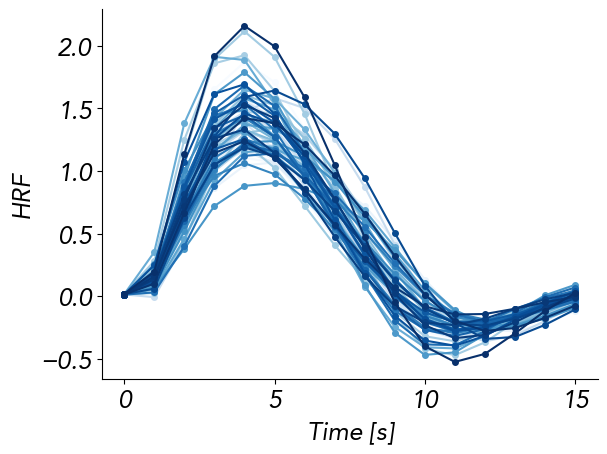

In [38]:
plt.rcParams['font.size'] =18

plt.rcParams['axes.spines.top']=False
plt.rcParams['axes.spines.right']=False

from matplotlib import cm
colors = cm.Blues(np.linspace(0,1,62))
for i in range(len(colors)):
    plt.plot(hemo_['h'][:,i], '-o',color=colors[i], markersize=4);
plt.xlabel('Time [s]')
plt.ylabel('HRF')
plt.savefig('../Figures/poster_hrf.jpg', dpi =300, bbox_inches='tight');

In [2]:
import numpy as np

In [11]:
np.random.randn(100).shape

(100,)

# Stochastic Block Model

In [3]:
import os
from scipy import signal

In [4]:
import sys
sys.path.append('../pyMOU-master/')
sys.path.append('..')
from pymou.mou_model import *

In [5]:
from my_module import *

In [6]:
JS = np.load('../numpy files/EC_matrix_HCP1_100.npy')

In [15]:
#JS = np.load('../../numpy files/EC_matrix_HCP1_100.npy')

In [7]:
import numpy as np
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests

n_subjects, n_nodes, _ = JS[:,:100,:100].shape

# T-test a livello di link
t_values, p_values = ttest_1samp(JS[:,:100,:100], popmean=0, axis=0)

# Correzione Bonferroni
p_flat = p_values.flatten()
reject, p_corrected, _, _ = multipletests(p_flat, method='bonferroni',alpha =.05)
significant_mask = reject.reshape((n_nodes, n_nodes))

# Matrice binaria dei link significativi
JS_significant = np.zeros((n_nodes, n_nodes))
JS_significant[significant_mask] = 1

print("Numero di link significativi con Bonferroni:", np.sum(JS_significant)/(n_nodes*n_nodes))
#print(significant_mask.sum(),np.sum(JS_significant))

np.sum(JS_significant)

Numero di link significativi con Bonferroni: 0.8091


np.float64(8091.0)

In [8]:

import numpy as np
import matplotlib.pyplot as plt
from nilearn.datasets import fetch_atlas_schaefer_2018

# =========================
# INPUT (tuoi dati)
# =========================
# F_sym: dynamic flow NxN (simmetrizzata, >=0)
# partition: dict {node: community_id}

# ESEMPIO placeholder (rimuovi se hai i tuoi)
# F_sym = np.load("F_sym.npy")
# partition = np.load("partition.npy", allow_pickle=True).item()

N = 100  # Schaefer-100

# =========================
# 1. Carica Schaefer 100 (7 networks)
# =========================
atlas = fetch_atlas_schaefer_2018(
    n_rois=100,
    yeo_networks=7,
    resolution_mm=2
)

labels = atlas.labels  # lista di stringhe, lunghezza 100
labels = [lab.decode("utf-8") if isinstance(lab, bytes) else lab
          for lab in atlas.labels]
len(labels)

100

## plots

In [18]:
print(len(np.unique(a[0])))

NameError: name 'a' is not defined

In [9]:
import numpy as np
import graph_tool.all as gt

def sbm_with_mcmc(F_t, rec_type= "real-normal", bool_value = True,iter_tot=1000, iter_skip=10):
    """
    F_t: NxN adjacency / flow matrix (directed, weighted)
    rec_type: SBM edge distribution type ("real-normal", "real-exponential", etc.)
    iter_tot: numero totale di iterazioni MCMC
    iter_skip: passi tra callback
    """
    # --- grafico diretto pesato ---
    N = F_t.shape[0]
    g = gt.Graph(directed=bool_value)
    g.add_vertex(N)
    weight = g.new_edge_property("double")
    if bool_value:
            
        for i in range(N):
            for j in range(N):
                if F_t[i,j] != 0:
                    e = g.add_edge(i,j)
                    weight[e] = F_t[i,j]
    else:

        for i in range(N):
            for j in range(i+1, N):
                if F_t[i, j] != 0:
                    e = g.add_edge(i, j)
                    weight[e] = F_t[i, j]

    g.ep.weight = weight

    # --- callback per salvare partizioni ---
    partitions = []
    dls =[]
    def collect(s):
        dls.append(s.entropy())
        partitions.append(s.get_state().a.copy())

    # --- SBM iniziale ---
    state = gt.minimize_blockmodel_dl(
        g,
        state_args=dict(recs=[g.ep.weight], rec_types=[rec_type])
    )

    # --- MCMC per consensus ---
    gt.mcmc_equilibrate(state, force_niter=iter_tot, mcmc_args=dict(niter=iter_skip),
                        callback=collect)

    # --- consensus clustering ---
    pmode = gt.ModeClusterState(partitions)
    best_partition = np.array(pmode.get_modes()[0].get_max(g))
    #print(len(pmode.get_modes()))
    # --- compatta blocchi in 0..K-1 ---
    unique_blocks = np.unique(best_partition)
    id_map = {old: new for new, old in enumerate(unique_blocks)}
    compact_partition = np.array([id_map[b] for b in best_partition])

    # --- inter-block matrix stimata dal modello SBM ---
    inter_block_matrix = state.get_matrix()

    return compact_partition, inter_block_matrix, dls

In [10]:
from nilearn.datasets import fetch_atlas_schaefer_2018

N = 100  # Schaefer-100

# =========================
# 1. Carica Schaefer 100 (7 networks)
# =========================
atlas = fetch_atlas_schaefer_2018(
    n_rois=100,
    yeo_networks=7,
    resolution_mm=2
)
from sklearn.metrics import normalized_mutual_info_score

labels = atlas.labels  # lista di stringhe, lunghezza 100
labels = [lab.decode("utf-8") if isinstance(lab, bytes) else lab
          for lab in atlas.labels]
labels = np.asarray(labels)

new_lab = cluster_2(labels[:100], aggregate[:100])
new_lab =(list(map(np.unique,cluster_2(labels, aggregate[:100]))))
# new_lab[53] = new_lab[53][0]

for i,el in enumerate(new_lab):
    if len(el) > 1:
        #print(new_lab[i])
        new_lab[i] = np.asarray([new_lab[i][0]])

In [11]:
for i,el in enumerate(new_lab):
    if len(el) > 1:
        #print(new_lab[i])
        new_lab[i] = np.asarray([new_lab[i][0]])

In [12]:
labels_100= np.asarray(labels, dtype=str)
print(labels_100[0])
len(labels)
labels100=[]
for i in labels_100[:]:
    labels100.append(i[10:])
print(len(labels100))
#labels100[:100]

7Networks_LH_Vis_1
100


In [13]:
#aggregate
new_lab = np.asarray(new_lab)
new_lab = new_lab.reshape(-1)
new_lab[:5]

array(['7Networks_LH_Vis_1', '7Networks_LH_Vis_2',
       '7Networks_LH_SomMot_1', '7Networks_LH_SomMot_4',
       '7Networks_LH_SomMot_5'], dtype='<U37')

NMI SBM vs Yeo: 14 0.5852520568765359
19 100


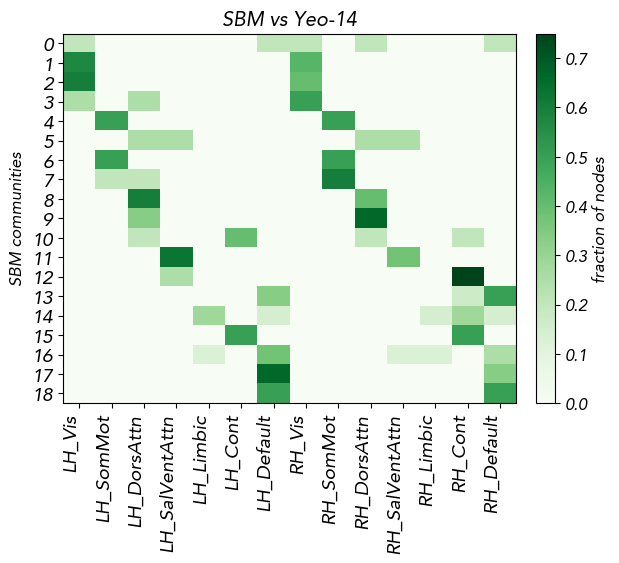

In [38]:
#
fig,ax =plt.subplots(1,1)
plot(a_ec_norm,labels100,ax, fig)
print(len(np.unique(a_ec_norm[0])), len(a_ec_norm[0]))

Number of SBM communities: 17


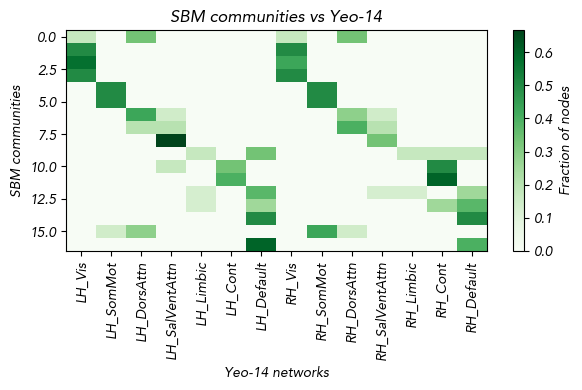

NMI SBM vs Yeo-: 14 , 0.5693528852228261
17 100


In [79]:
#
#fig,ax =plt.subplots(1,1)
plot(a_ec_norm,labels100)
print(len(np.unique(a_ec_norm[0])), len(a_ec_norm[0]))

13 100


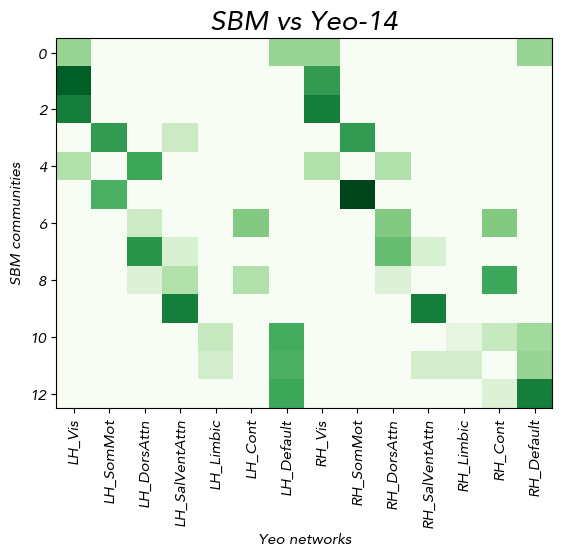

In [216]:
fig,ax =plt.subplots(1,1)
plot(a_ec_norm,labels100,ax)
print(len(np.unique(a_ec_norm[0])), len(a_ec_norm[0]))

14 100


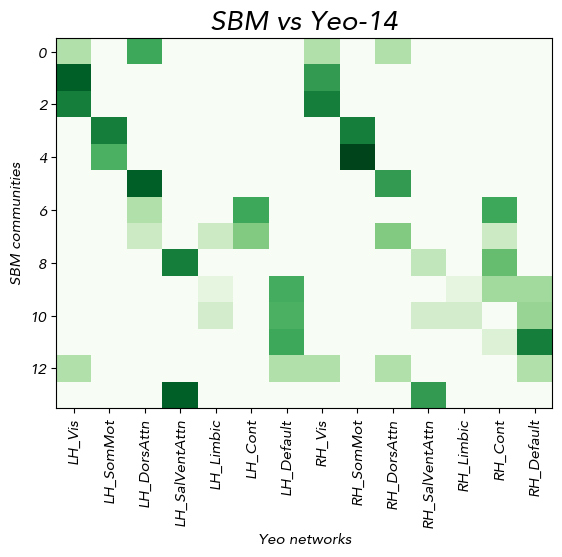

In [214]:
fig,ax =plt.subplots(1,1)
plot(a_ec_norm,labels100,ax)
print(len(np.unique(a_ec_norm[0])), len(a_ec_norm[0]))

13 100


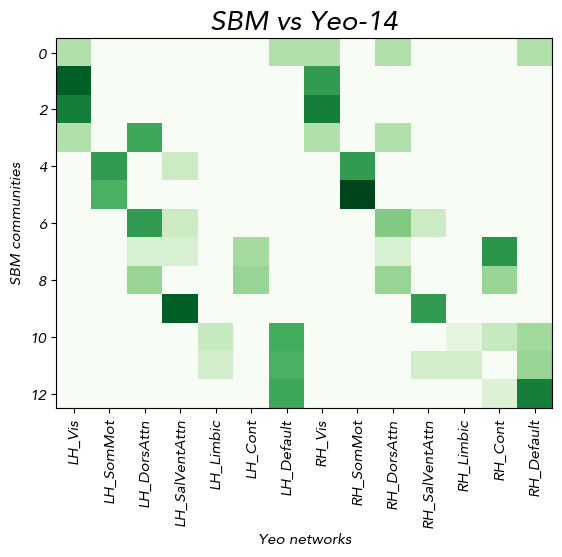

In [212]:
fig,ax =plt.subplots(1,1)
plot(a_ec_norm,labels100,ax)
print(len(np.unique(a_ec_norm[0])), len(a_ec_norm[0]))

NMI SBM vs Yeo-: 14 , 0.5845260383672299
15 100


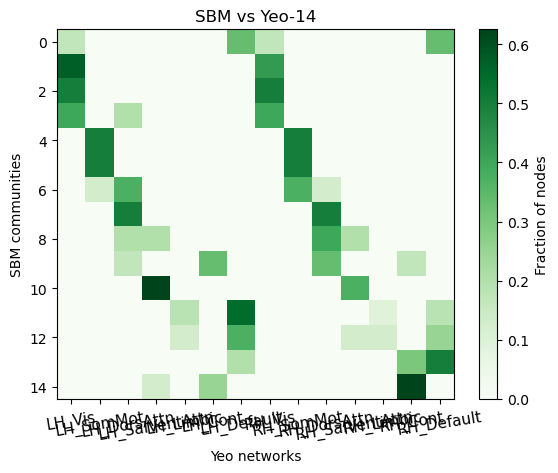

In [24]:
fig,ax =plt.subplots(1,1)
plot(a_ec_norm,labels100,ax,fig)
print(len(np.unique(a_ec_norm[0])), len(a_ec_norm[0]))

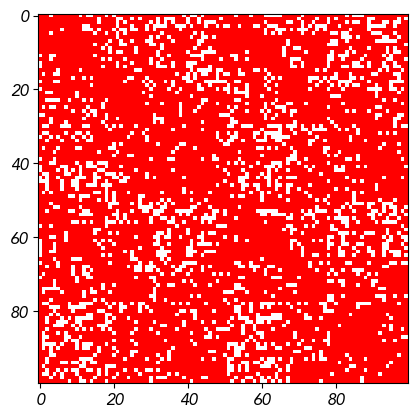

In [123]:
#plt.imshow(J, cmap='bwr', vmin=-.1,vmax=.1);
plt.imshow(significant_mask, cmap='bwr', vmin=-.1,vmax=.1);


(array([  9.,  60., 208., 276., 291., 314., 308., 301., 121.,  21.]),
 array([-3.91002780e-03, -3.14304781e-03, -2.37606782e-03, -1.60908782e-03,
        -8.42107828e-04, -7.51278343e-05,  6.91852160e-04,  1.45883215e-03,
         2.22581215e-03,  2.99279214e-03,  3.75977214e-03]),
 <BarContainer object of 10 artists>)

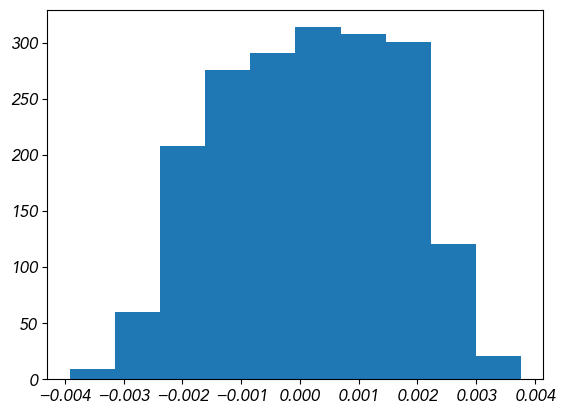

In [120]:
J = np.mean(JS,0)[:100,:100]
plt.hist(J[np.logical_not(significant_mask)].flatten())

In [142]:
significant_mask.shape
Sigma = np.diag(np.ones(100))
J = np.mean(JS,0)[:100,:100]
#J[np.logical_not(significant_mask)[:100,:100]] = 0
J = J*(np.abs(J)>=np.percentile(np.abs(J),10))
print(np.percentile(np.abs(J),10))

significant_mask.shape
Sigma = np.diag(np.ones(100))
J = np.mean(JS,0)[:100,:100]
#print(np.percentile(np.abs(J),20))

J[np.logical_not(significant_mask)[:100,:100]] = 0
#print(np.percentile(np.abs(J[significant_mask]),90))

J = J*(np.abs(J)>=np.percentile(np.abs(J),10))
print(np.percentile(np.abs(J),10))

0.0011672492057225358
0.0


In [118]:
Sigma = np.diag(np.ones(100))
J = np.mean(JS,0)[:100,:100]
#J[np.logical_not(significant_mask)[:100,:100]] = 0
J = J*(np.abs(J)>=np.percentile(np.abs(J),40))
"""
J0 = np.diag(np.diag(J))      # J0: solo autoconnettività locale
# --- 2. Norma L1 per la normalizzazione ---
scaling = 1.0 / norm(J0, ord=1)  # ||J0||_1
# --- 3. Calcolo C(t) normalizzata ---
t = 1.0  # impulso-responce time
#C_t = scaling * (expm(J * t) - expm(J0 * t))
Ct = expm(J*t) - expm(J0*t)
F_t = scaling * np.sqrt(Sigma) @ Ct   # dynamic flow
#F_t[F_t<0] = 0
#J[J<0] = 0
"""
#J[J<0] = 0
bb= sbm_with_mcmc(dediag(J), bool_value=True, rec_type='real-normal')
#fig,ax = plt.subplots(1,1)
print(len(np.unique(bb[0])))

16


In [21]:
def plot(a, labels, ax,fig, no_net=14, cmap='Greens', fontsize = 11):

    partition_array = np.array(a[0])

    unique_blocks = np.unique(partition_array)
    id_map = {old: new for new, old in enumerate(unique_blocks)}
    compact_partition = np.array([id_map[b] for b in partition_array])

    N = len(partition_array)
    if N != len(labels):
        raise Exception('wrong shape')

    yeo_names_2 = [
        "LH_Vis", "LH_SomMot", "LH_DorsAttn",
        "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
        "RH_Vis", "RH_SomMot", "RH_DorsAttn",
        "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
    ]
    
    yeo_names = [
        "Vis", "SomMot", "DorsAttn",
        "SalVentAttn", "Limbic", "Cont", "Default"]

    riferi = yeo_names_2 if no_net == 14 else yeo_names

    schaefer_network_hemi_2 = np.zeros(N, dtype=int)

    for i, lab in enumerate(labels):
        for k, net in enumerate(riferi):
            if net in lab:
                schaefer_network_hemi_2[i] = k
                break

    K = len(np.unique(compact_partition))
    Y = len(np.unique(schaefer_network_hemi_2))

    M = np.zeros((K, Y), dtype=float)

    for i in range(len(compact_partition[:100])):
        M[compact_partition[i], schaefer_network_hemi_2[i]] += 1

    M = M / (M.sum(axis=1, keepdims=True) + 1e-12)

    im = ax.imshow(M, aspect='auto', cmap=cmap)

    ax.set_title(f"SBM vs Yeo-{len(riferi)}")
    ax.set_xlabel("Yeo networks")
    ax.set_ylabel("SBM communities")
    fig.colorbar(im,label="Fraction of nodes", ax=ax)
    
    ax.set_xticks(np.arange(len(riferi)))
    ax.set_xticklabels(riferi, rotation=9, fontsize = fontsize)
    
    nmi = normalized_mutual_info_score(schaefer_network_hemi_2, compact_partition[:100],)  # yeo_labels in 0..6
    print("NMI SBM vs Yeo-:", len(riferi), ",", nmi)

    
    nmi = normalized_mutual_info_score(schaefer_network_hemi_2, compact_partition[:100],average_method  ='min')  # yeo_labels in 0..6
    print("NMI SBM vs Yeo-:", len(riferi), ",", nmi)

    
    nmi = normalized_mutual_info_score(schaefer_network_hemi_2, compact_partition[:100],average_method  ='max')  # yeo_labels in 0..6
    print("NMI SBM vs Yeo-:", len(riferi), ",", nmi)
    return im, nmi



NMI SBM vs Yeo-: 14 , 0.5744106195738597
NMI SBM vs Yeo-: 14 , 0.6168112132449122
NMI SBM vs Yeo-: 14 , 0.5374644498824641
NMI SBM vs Yeo-: 7 , 0.6288401505347425
NMI SBM vs Yeo-: 7 , 0.8058189212262639
NMI SBM vs Yeo-: 7 , 0.5156008158086492


19

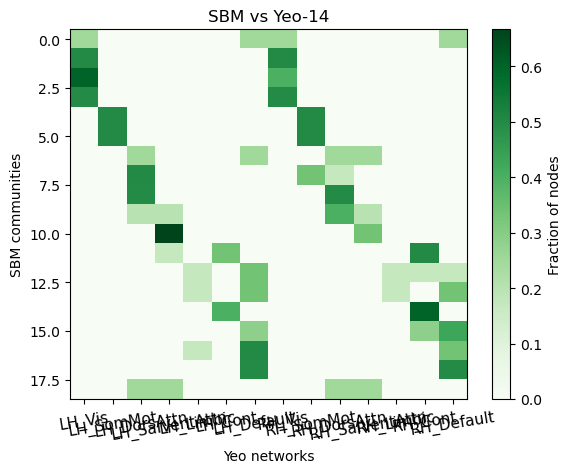

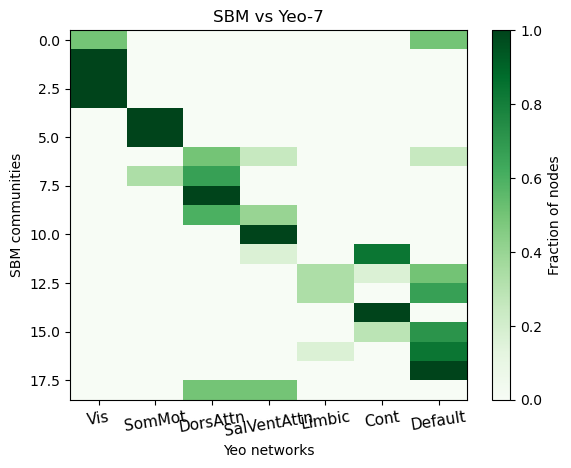

In [24]:
fig,ax = plt.subplots(1,1)
plot(a_ec_norm,labels,ax,fig,14)
len(np.unique(a_ec_norm[0]))

fig,ax = plt.subplots(1,1)
plot(a_ec_norm,labels,ax,fig,7)
len(np.unique(a_ec_norm[0]))

In [23]:
a_ec_norm[0]

array([ 0,  1,  2,  3,  3,  2,  1,  1,  2,  4,  4,  4,  5,  5,  5,  6,  7,
        8,  7,  8,  7, 18,  9, 18, 10, 10, 11, 10,  9, 10, 12, 13, 16, 11,
       11, 14, 14, 13, 13,  6, 15, 12, 16, 17, 12, 16, 16, 15,  0, 17,  0,
        1,  1,  3,  3,  2,  1,  2,  4,  4,  4,  5,  7,  5,  7,  5,  6,  7,
        8,  8,  9, 18,  9,  6, 18, 10,  9, 10, 12, 13, 11, 15, 12, 11, 11,
       15, 14, 14, 14, 15, 15, 13, 13, 12, 16, 17, 16, 15,  0, 17])

In [93]:
a_ec_normm =  np.array([ 0, 1,  1,  2,  2,  1 , 3,  3,  1,  4,  4 , 6,  5,  5,  5,  3,  6,  7,  6,  7,  6,  9,  8, 10,
 10 ,10, 14 ,10,  8 ,10 ,11 ,12 ,11 , 9 , 9, 14 ,14, 12, 12, 12, 13 ,11 ,11, 11, 11, 11, 11,  0,
  0 ,13 , 0 , 1,  3,  2  ,2  ,1 , 3,  1 , 4 , 4,  6,  5,  6 , 5,  6,  5,  7,  6,  9 , 7 , 8 , 9,
  8 ,12 ,10 ,10,  8, 10 ,11 ,12 ,14, 13, 13,  9, 14, 13, 14, 14 ,14, 13, 13, 12, 12, 11, 11, 13,
 13 , 0 , 0, 13])
len(a_ec_normm)

100

NMI SBM vs Yeo: 14 0.591018259685078
NMI SBM vs Yeo: 14 0.6274724258674691
NMI SBM vs Yeo: 14 0.5585672656845705
NMI SBM vs Yeo: 7 0.6380960286617717
NMI SBM vs Yeo: 7 0.8071342483863783
NMI SBM vs Yeo: 7 0.5276005780913874


18

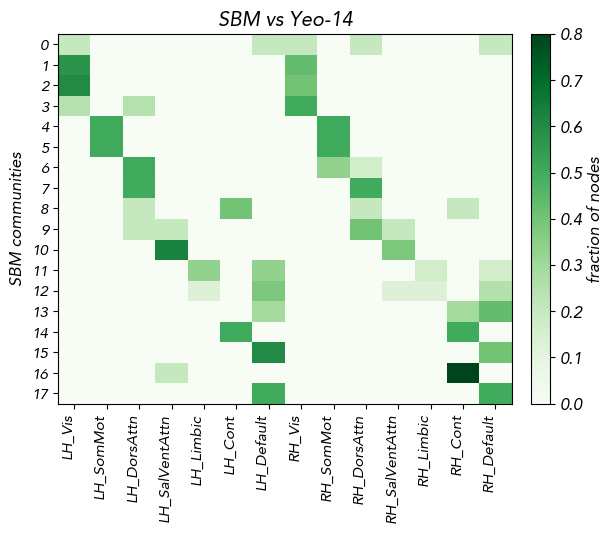

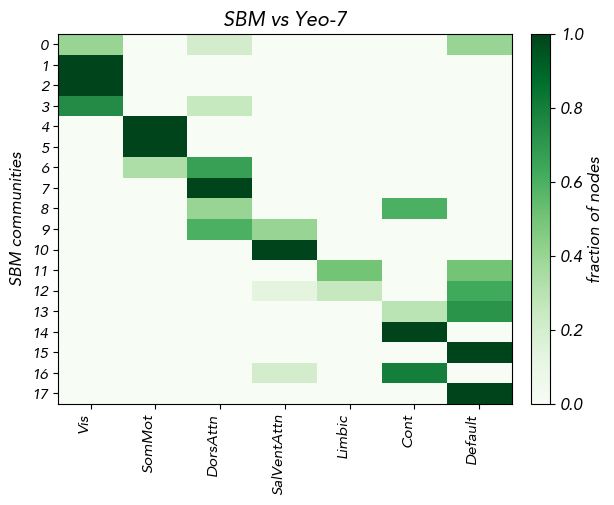

In [162]:
fig,ax = plt.subplots(1,1)
plot(a_ec_norm,labels,ax,fig,14)
len(np.unique(a_ec_norm[0]))

fig,ax = plt.subplots(1,1)
plot(a_ec_norm,labels,ax,fig,7)
len(np.unique(a_ec_norm[0]))

NMI SBM vs Yeo: 14 0.5845260383672299
NMI SBM vs Yeo: 14 0.5970128838798298
NMI SBM vs Yeo: 14 0.572550829868845
NMI SBM vs Yeo: 7 0.6404150595086344
NMI SBM vs Yeo: 7 0.7749050056676569
NMI SBM vs Yeo: 7 0.5457044096422179


18

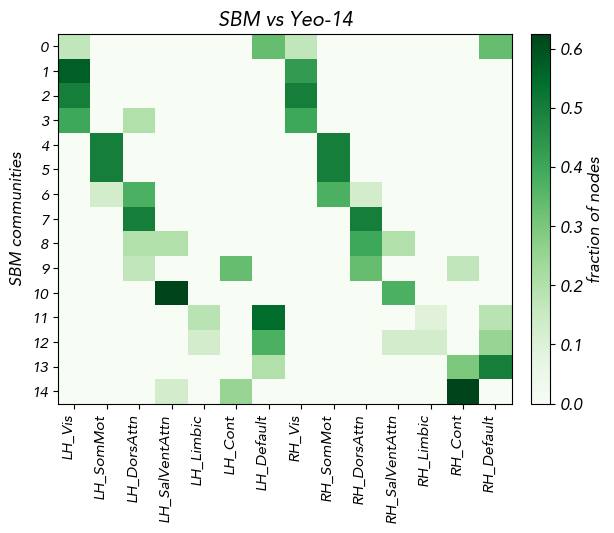

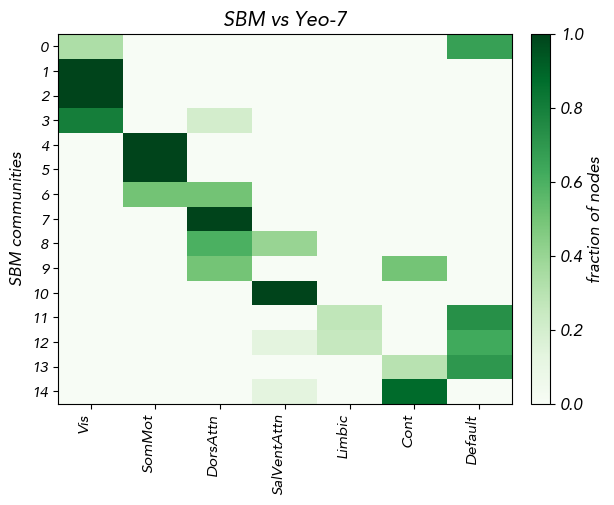

In [161]:
fig,ax = plt.subplots(1,1)
plot([a_ec_normm],labels,ax,fig,14)
len(np.unique(a_ec_norm[0]))

fig,ax = plt.subplots(1,1)
plot([a_ec_normm],labels,ax,fig,7)
len(np.unique(a_ec_norm[0]))

In [ ]:

# tempo (quanti volumi per ottenere ecvicina a quella che trovo) per ec V
# vedere diverse condizioni iniziali V
# in srength out strength
# inibizioe eccitazione
# sbm 
# bootstrap ? per sparsificare 
# hessianoo di gilson
# fare confronti anche con lemon


In [25]:
import numpy as np

partition_array = np.array(a_ec_norm[0])  # output SBM originale
unique_blocks = np.unique(partition_array)

# mapping compatto: 0,1,...,K-1
id_map = {old: new for new, old in enumerate(unique_blocks)}
compact_partition = np.array([id_map[b] for b in partition_array])

print("Number of SBM communities:", len(unique_blocks))
print("Compact partition:", compact_partition)


Number of SBM communities: 19
Compact partition: [ 0  1  2  3  3  2  1  1  2  4  4  4  5  5  5  6  7  8  7  8  7 18  9 18
 10 10 11 10  9 10 12 13 16 11 11 14 14 13 13  6 15 12 16 17 12 16 16 15
  0 17  0  1  1  3  3  2  1  2  4  4  4  5  7  5  7  5  6  7  8  8  9 18
  9  6 18 10  9 10 12 13 11 15 12 11 11 15 14 14 14 15 15 13 13 12 16 17
 16 15  0 17]


In [178]:
J.shape, significant_mask.shape, 
to_plot = np.copy(J[:100,:100])

to_plot[np.logical_not(significant_mask[:100,:100])]=np.nan

In [85]:
J = np.mean(JS,0)
J.shape, JS.shape

((112, 112), (1013, 112, 112))

### su media di fc

In [154]:

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel = 100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'

In [155]:
sub_tot=[]
for sub in tqdm(pat):
    #print(sub)

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        if len(data_1) ==1200 and len(data_2) ==1200:
            sub_tot.append(sub)
        

100%|██████████| 1097/1097 [00:02<00:00, 498.07it/s]


In [10]:
cd ../..

/home/benedetta/Scripts/Insight_project


In [12]:
from my_module import *

In [22]:
import sys
sys.path.append('pyMOU-master/')
from pymou.mou_model import *

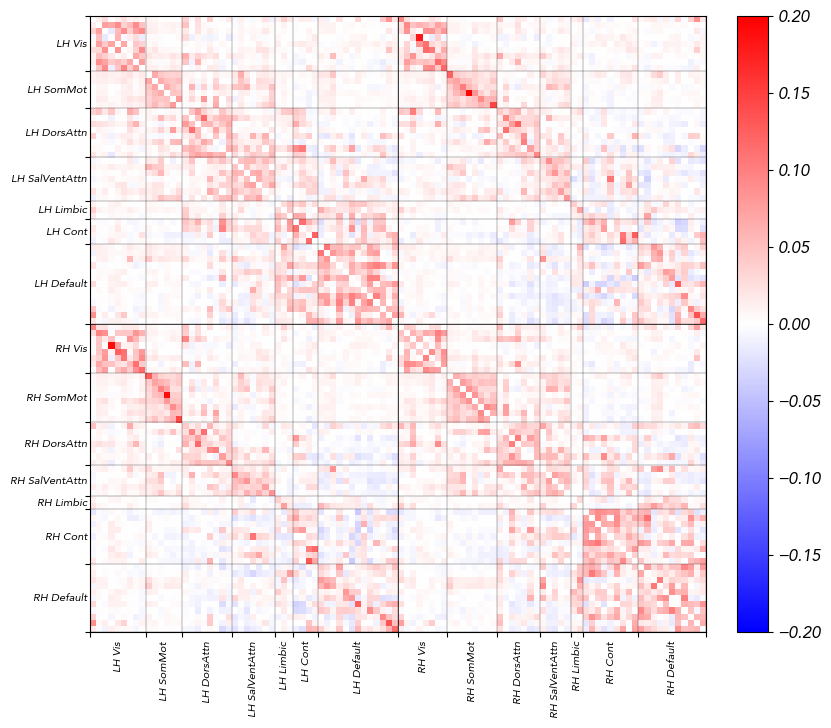

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict

import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict

def plot_fc_matrix(fc, labels, cmap="bwr", vmin=-0.2, vmax=0.2):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]  # hemi, net

    # --------------------------------------------------
    # 1. GROUPING (network within hemisphere order preserved)
    # --------------------------------------------------
    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        key = f"{hemi}_{net}"
        groups.setdefault(key, []).append(i)

    new_order = []
    bounds = []
    names = []

    start = 0
    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    # --------------------------------------------------
    # 2. PLOT
    # --------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # --------------------------------------------------
    # 3. BOUNDARY TICKS (network blocks)
    # --------------------------------------------------
    tick_positions = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(tick_positions)-.5)
    ax.set_yticks(np.array(tick_positions)-.5)

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(axis='x', bottom=True, top=False, labelbottom=True)
    ax.tick_params(axis='y', left=True, right=False, labelleft=True)

    # --------------------------------------------------
    # 4. GRID (light network boundaries)
    # --------------------------------------------------
    for t in tick_positions:
        ax.axhline(t - 0.5, color="black", linewidth=0.2)
        ax.axvline(t - 0.5, color="black", linewidth=0.2)

    # --------------------------------------------------
    # 5. STRONG LH / RH SEPARATION LINE
    # --------------------------------------------------
    # find boundary between hemispheres
    lh_count = sum(1 for l in labels if l.startswith("LH_"))
    split = lh_count  # index where RH starts

    ax.axhline(split - 0.5, color="black", linewidth=0.5)
    ax.axvline(split - 0.5, color="black", linewidth=0.5)

    # --------------------------------------------------
    # 6. NETWORK LABELS (centered)
    # --------------------------------------------------
    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split("_")

        # bottom labels
        ax.text(
            center -.5,
            n + 1,
            f"{hemi} {net}",
            ha="center",
            va="top",
            rotation=90,
            fontsize=8,
            clip_on=False
        )

        # left labels
        ax.text(
            -1,
            center-.5,
            f"{hemi} {net}",
            ha="right",
            va="center",
            fontsize=8,
            clip_on=False
        )

    # --------------------------------------------------
    # 7. AXES LIMITS (critical for alignment)
    # --------------------------------------------------
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    return fig, ax
plot_fc_matrix(dediag(J), labels100);


In [30]:
J.shape


(100, 100)

In [48]:
import nibabel as nib
import numpy as np

# Percorso del file NIfTI Schaefer-100
atlas_path = "/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii"
atlas_img = nib.load(atlas_path)
atlas_data = atlas_img.get_fdata()
roi_numbers = np.unique(atlas_data)
roi_numbers = roi_numbers[roi_numbers != 0]  # rimuovi lo sfondo
print(roi_numbers)
labels = []
networks = ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','DefaultC']
hemis = ['LH','RH']

count = 0
for hemi in hemis:
    for net in networks:
        n_nodes = 100 // (len(networks)*2)  # per Schaefer-100 e 7 networks
        for i in range(1, n_nodes+1):
            count += 1
            labels.append(f"{hemi}_{net}")
len(labels)

[  1.   2.   3.   4.   5.   6.   7.   8.   9.  10.  11.  12.  13.  14.
  15.  16.  17.  18.  19.  20.  21.  22.  23.  24.  25.  26.  27.  28.
  29.  30.  31.  32.  33.  34.  35.  36.  37.  38.  39.  40.  41.  42.
  43.  44.  45.  46.  47.  48.  49.  50.  51.  52.  53.  54.  55.  56.
  57.  58.  59.  60.  61.  62.  63.  64.  65.  66.  67.  68.  69.  70.
  71.  72.  73.  74.  75.  76.  77.  78.  79.  80.  81.  82.  83.  84.
  85.  86.  87.  88.  89.  90.  91.  92.  93.  94.  95.  96.  97.  98.
  99. 100.]


98

Avenir


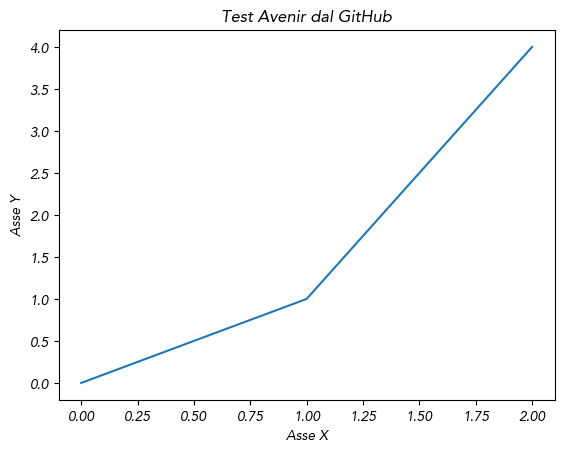

In [33]:
import urllib.request
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt

# Link diretto al file TTF su GitHub (raw)
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"

# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = font_name

# Test plot
plt.figure()
plt.title("Test Avenir dal GitHub")
plt.xlabel("Asse X")
plt.ylabel("Asse Y")
plt.plot([0, 1, 2], [0, 1, 4])

In [36]:
labels=labels[:100]

NameError: name 'ssi_mean' is not defined

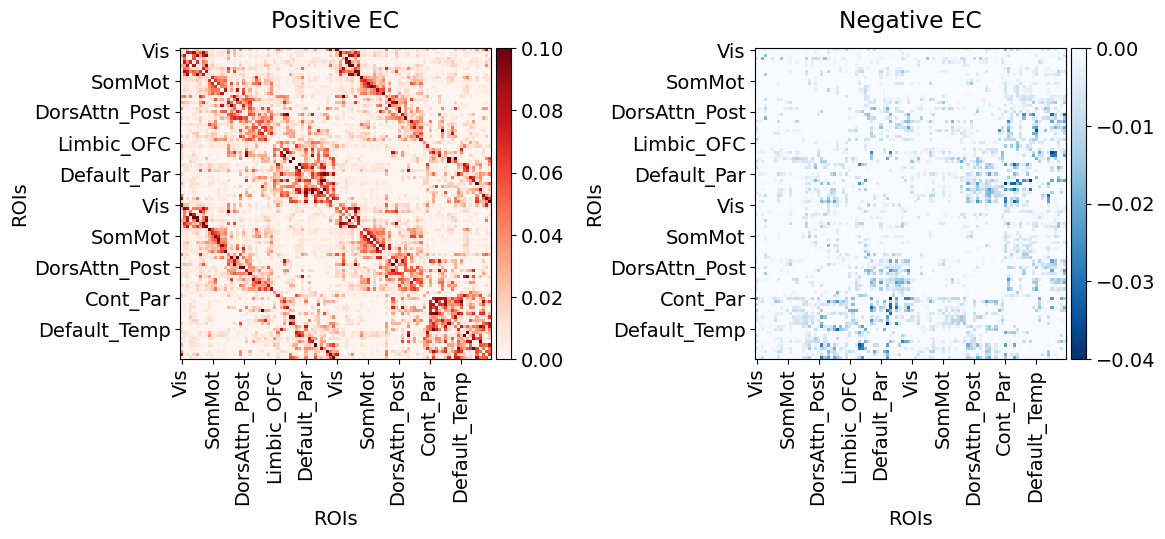

In [37]:

#lot(a_ec_norm,labels,14)

fig, axes = plt.subplots(1, 2, figsize=(12,6)  )
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 44
#12
plt.rcParams['font.size'] = 14

#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')
media = dediag(np.mean(JS,0))[:100,:100]
#sub = 600
#media = JS[sub]

pos = media.copy()
neg = media.copy()
pos[media<0] = 0
neg[media>0] = 0





# Primo pannello
v = [[0.,.1],[-.04,0]]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[pos, neg]
cmaps = ['Reds', 'Blues_r']

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['Positive EC', 'Negative EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(dediag(js[i]), vmin=v[i][0], vmax=v[i][1], cmap = cmaps[i]);
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
    ax.set_yticks(np.arange(0,100,10),)
    ax.set_xticks(np.arange(0,100,10),)
    ax.set_xticklabels(labels[::10], rotation = 90)
    ax.set_yticklabels(labels[::10],)
    
plt.tight_layout()
#ig('Figures/positivemap.jpg', dpi = 300, bbox_inches='tight');


import nibabel as nib

I1=nib.load('/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii')

data = I1.get_fdata()
affine=I1.affine

data_J = np.zeros(np.shape(data))

for r in range(100):
    v=np.where(data==r+1)
    data_J[v]=ssi_mean[r]
    #np.sum(J_all,axis=(1,2))[r]-np.sum(J_all,axis=(0,2))[r]
    
    

img_J = nib.Nifti1Image(data_J, affine)



from matplotlib import cm
from matplotlib.colors import ListedColormap

top = cm.get_cmap('Blues_r', 128)
bottom = cm.get_cmap('Oranges', 128)
newcolors1 = np.vstack((top(np.linspace(0, 1, 128)),
                       bottom(np.linspace(0, 1, 128))))
newcmp = ListedColormap(newcolors1, name='OrangeBlue')


import nilearn
import nilearn.plotting

fig = plt.figure(figsize=(8, 3))
display=nilearn.plotting.plot_stat_map(img_J,cmap=newcmp,draw_cross=False,display_mode='x',\
                                       cut_coords=[-34,-17,0,17, 34],colorbar=True,figure=fig, vmin=-.1, vmax=.1)
display._colorbar_ax.tick_params(labelsize=10)
#fig.suptitle('C MOU', fontsize=20, y=1.05)
fig.subplots_adjust(top=0.85)
plt.tight_layout()
plt.savefig('deltaJ_map.png')

In [71]:

#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')
media = dediag(np.mean(JS,0))[:100,:100]
#sub = 600
#media = JS[sub]

pos = media.copy()
neg = media.copy()
pos[media<0] = 0
neg[media>0] = 0


# Main figure

In [14]:
# =========================
# FIXED plot() (subplot-safe)
# =========================
def plot(a, labels, ax,fig, no_net=14, cmap='Greens', fontsize = 11):

    partition_array = np.array(a[0])

    unique_blocks = np.unique(partition_array)
    id_map = {old: new for new, old in enumerate(unique_blocks)}
    compact_partition = np.array([id_map[b] for b in partition_array])

    N = len(partition_array)
    if N != len(labels):
        raise Exception('wrong shape')

    yeo_names_2 = [
        "LH_Vis", "LH_SomMot", "LH_DorsAttn",
        "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
        "RH_Vis", "RH_SomMot", "RH_DorsAttn",
        "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
    ]

    riferi = yeo_names_2 if no_net == 14 else yeo_names_2[:7]

    schaefer_network_hemi_2 = np.zeros(N, dtype=int)

    for i, lab in enumerate(labels):
        for k, net in enumerate(riferi):
            if net in lab:
                schaefer_network_hemi_2[i] = k
                break

    K = len(np.unique(compact_partition))
    Y = len(np.unique(schaefer_network_hemi_2))

    M = np.zeros((K, Y), dtype=float)

    for i in range(len(compact_partition[:100])):
        M[compact_partition[i], schaefer_network_hemi_2[i]] += 1

    M = M / (M.sum(axis=1, keepdims=True) + 1e-12)

    im = ax.imshow(M, aspect='auto', cmap=cmap)

    ax.set_title(f"SBM vs Yeo-{len(riferi)}")
    ax.set_xlabel("Yeo networks")
    ax.set_ylabel("SBM communities")
    fig.colorbar(im,label="Fraction of nodes", ax=ax)
    
    ax.set_xticks(np.arange(len(riferi)))
    ax.set_xticklabels(riferi, rotation=9, fontsize = fontsize)
    
    nmi = normalized_mutual_info_score(schaefer_network_hemi_2, compact_partition[:100])  # yeo_labels in 0..6
    print("NMI SBM vs Yeo-:", len(riferi), ",", nmi)
    return im, nmi



In [44]:
JS.shape

(1013, 112, 112)

In [15]:
import numpy as np

#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')#[:,:100,:100]
#JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')
#JS_2 = np.load('numpy files/EC_matrix_HCP2_200_converged.npy')#[:,:100,:100]


JS = np.load('../numpy files/EC_matrix_HCP1_100.npy')#[:,:100,:100]
#JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')
JS_2 = np.load('../numpy files/EC_matrix_HCP2_100.npy')#[:,:100,:100]


n_subjects, N, _ = JS.shape

ssi_norm_all = np.zeros((n_subjects, N-12))

for s in range(n_subjects):
    C = dediag(JS[s].T)[:100,:100]
    C[np.logical_not(significant_mask[:100,:100])] = 0
    
    thr = np.percentile(np.abs(C), 60)
    C_thr = C 
    #* (np.abs(C) >= thr)

    in_strength  = np.sum(np.abs(C_thr), axis=1)
    out_strength = np.sum(np.abs(C_thr), axis=0)

    ssi_norm_all[s] = (out_strength - in_strength) / \
                      (out_strength + in_strength + 1e-12)

prop_source = np.mean(ssi_norm_all > 0, axis=0)
prop_sink   = np.mean(ssi_norm_all < 0, axis=0)


"""

n_subjects, N, _ = JS.shape

ssi_norm_all = np.zeros((n_subjects, N))

for s in range(n_subjects):
    C = dediag(JS_2[s].T)
    
    
    thr = np.percentile(np.abs(C), 60)
    C_thr = C 
    #* (np.abs(C) >= thr

    in_strength  = np.sum(np.abs(C_thr), axis=1)
    out_strength = np.sum(np.abs(C_thr), axis=0)

    ssi_norm_all[s] = (out_strength - in_strength) / \
                      (out_strength + in_strength + 1e-12)

prop_source_2 = np.mean(ssi_norm_all > 0, axis=0)
prop_sink_2   = np.mean(ssi_norm_all < 0, axis=0)
prop_source_2.shape
"""
ssi_mean = np.mean(np.asarray(ssi_norm_all),0)

#plt.scatter(prop_source, prop_source_2, marker='.');

In [86]:
sig_mask.shape

(100, 100)

In [158]:
import numpy as np
from sklearn.metrics.cluster import normalized_mutual_info_score
import matplotlib.pyplot as plt
#for sub in np.arange(1):
Sigma = np.diag(np.ones(100))
J = np.mean(JS,0)[:100,:100]
J[np.logical_not(significant_mask)[:100,:100]] = 0
"""
J0 = np.diag(np.diag(J))      # J0: solo autoconnettività locale
# --- 2. Norma L1 per la normalizzazione ---
scaling = 1.0 / norm(J0, ord=1)  # ||J0||_1
# --- 3. Calcolo C(t) normalizzata ---
t = 1.0  # impulso-responce time
#C_t = scaling * (expm(J * t) - expm(J0 * t))
Ct = expm(J*t) - expm(J0*t)
F_t = scaling * np.sqrt(Sigma) @ Ct   # dynamic flow
#F_t[F_t<0] = 0
#J[J<0] = 0
"""
#J[J<0] = 0
a_ec_norm= sbm_with_mcmc(dediag(J), bool_value=True, rec_type='real-normal')

In [16]:
a_ec_norm = [np.load('../numpy files/community_div.npy')]

(array([ 2.,  0.,  7.,  9.,  9., 21., 17., 16., 23.,  8.]),
 array([-3.27736046, -2.75819606, -2.23903167, -1.71986727, -1.20070288,
        -0.68153848, -0.16237409,  0.35679031,  0.8759547 ,  1.3951191 ,
         1.91428349]),
 <BarContainer object of 10 artists>)

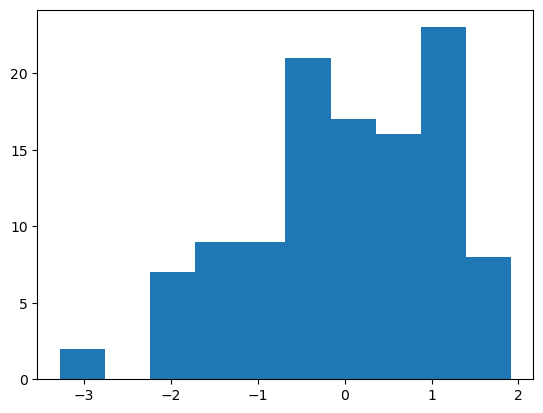

In [18]:
S_s =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], False)
    S_s.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s = np.asarray(S_s)
source_sink_S = np.sum(np.mean(S_s,0),0)
plt.hist(source_sink_S)

In [56]:
#np.save('../numpy files/community_div.npy',np.asarray(a_ec_norm[0]))

NMI SBM vs Yeo: 7 0.6288401505347425
NMI SBM vs Yeo: 7 0.8058189212262639
NMI SBM vs Yeo: 7 0.5156008158086492
AMI arithmetic: 0.5006766115080192
AMI min: 0.7106473484443183
AMI max: 0.3864843761451387
0.6288401505347425 0.8058189212262639 0.5156008158086492


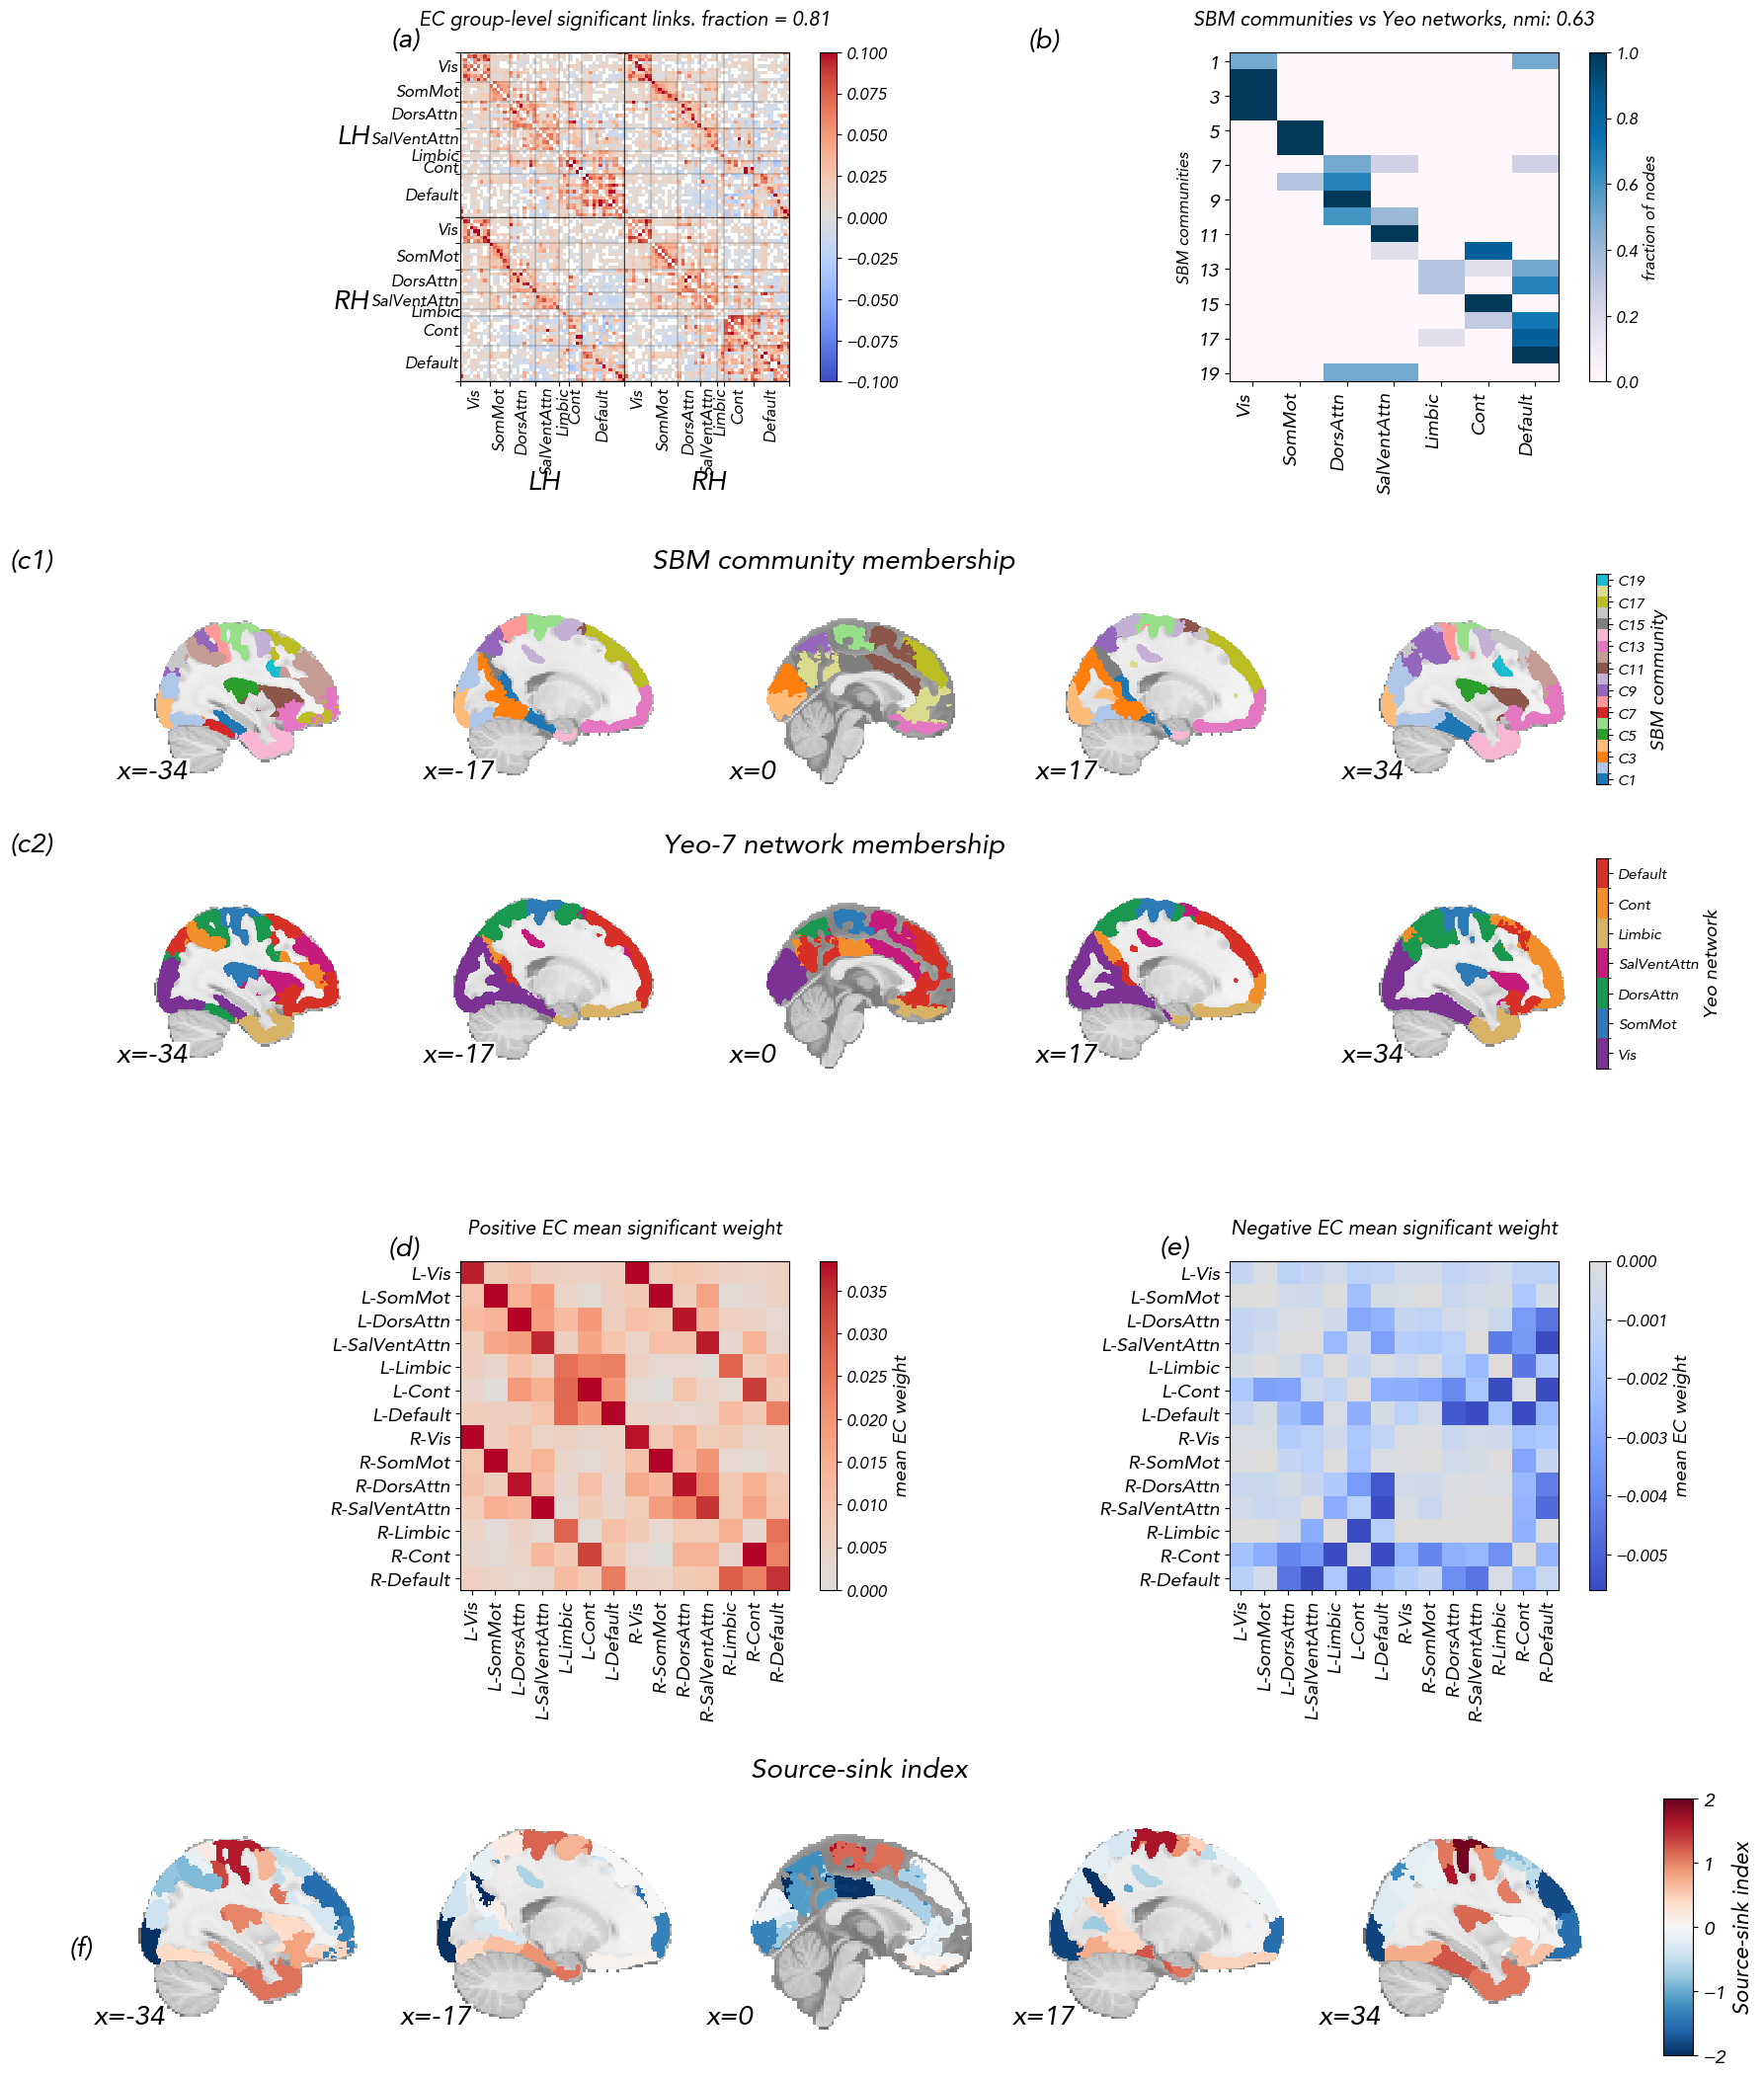

In [27]:
ssi_mean = np.mean(np.asarray(ssi_norm_all),0)
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import nilearn.plotting as plotting
from matplotlib.colors import ListedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import colormaps
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
from collections import OrderedDict
from sklearn.metrics import adjusted_mutual_info_score
plt.rcParams['font.size'] = 12

# =========================================================
# FC PLOTTING FUNCTION (SUBPLOT-SAFE)
# =========================================================
def plot_fc_matrix(fc, labels, ax, cmap="bwr", vmin=-0.2, vmax=0.2):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]

    # ---- grouping ----
    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order, bounds, names = [], [], []
    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)

    # ---- boundaries ----
    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks)-.5)
    ax.set_yticks(np.array(ticks)-.5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(axis='x', bottom=True, labelbottom=True)

    for t in ticks:
        ax.axhline(t - 0.5, color="black", linewidth=0.2)
        ax.axvline(t - 0.5, color="black", linewidth=0.2)

    # ---- LH / RH separation ----
    lh_count = sum(lab.startswith("LH_") for lab in labels)
    ax.axhline(lh_count - 0.5, color="black", linewidth=0.5)
    ax.axvline(lh_count - 0.5, color="black", linewidth=0.5)

        # ---- labels ----
    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split("_")
    
        ax.text(center-.5, n + 1, f"{net}",
                ha="center", va="top",
                rotation=90, clip_on=False)
    
        ax.text(-1, center-.5, f"{net}",
                ha="right", va="center", clip_on=False)
    
        ax.set_xlim(-0.5, n - 0.5)
        ax.set_ylim(n - 0.5, -0.5)
        
    # ---- LH / RH labels ----
    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2
    
    offset_x = n + 18   # distanza sull'asse x (sopra le label dei network)
    offset_y = -18      # distanza sull'asse y (a sinistra delle label dei network)
    
    # Asse X (sopra)
    ax.text(lh_center 
            , offset_x+8, "LH",
            ha="center", va="top",
            fontweight='bold', clip_on=False, fontsize = 20)
    ax.text(rh_center , offset_x+8, "RH",
            ha="center", va="top",
            fontweight='bold', clip_on=False, fontsize = 20)
    
    # Asse Y (sinistra)
    ax.text(offset_y-10, lh_center , "LH",
            ha="right", va="center",
            fontweight='bold', clip_on=False, fontsize = 20)
    ax.text(offset_y-10, rh_center , "RH",
            ha="right", va="center",
            fontweight='bold', clip_on=False, fontsize = 20)

    return im
from sklearn.metrics import normalized_mutual_info_score
import numpy as np
import matplotlib.pyplot as plt

def plot(a, labels, ax, fig,no_net=14, cmap='Greens', fontsize=11):

    partition_array = np.array(a[0])

    unique_blocks = np.unique(partition_array)
    id_map = {old: new for new, old in enumerate(unique_blocks)}
    compact_partition = np.array([id_map[b] for b in partition_array])

    N = len(partition_array)
    if N != len(labels):
        raise Exception('wrong shape')

    yeo_names_2 = [
        "LH_Vis", "LH_SomMot", "LH_DorsAttn",
        "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
        "RH_Vis", "RH_SomMot", "RH_DorsAttn",
        "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
    ]

    
    yeo_names = [
        "Vis", "SomMot", "DorsAttn",
        "SalVentAttn", "Limbic", "Cont", "Default"]
    riferi = yeo_names_2 if no_net == 14 else yeo_names

    schaefer_network_hemi_2 = np.zeros(N, dtype=int)

    for i, lab in enumerate(labels):
        for k, net in enumerate(riferi):
            if net in lab:
                schaefer_network_hemi_2[i] = k
                break

    K = len(np.unique(compact_partition))
    Y = len(np.unique(schaefer_network_hemi_2))

    M = np.zeros((K, Y), dtype=float)

    for i in range(N):
        M[compact_partition[i], schaefer_network_hemi_2[i]] += 1

    # row-normalization
    M = M / (M.sum(axis=1, keepdims=True) + 1e-12)

    # =========================
    # PLOT (FIXED GEOMETRY)
    # =========================
    im = ax.imshow(M, cmap=cmap, aspect='auto')
    
    #ax.set_aspect('equal')
    #ax.set_aspect('equal')
    
    #ax.imshow(M)
    #ax.set_aspect(M.shape[1]/ M.shape[0])

    ax.set_title(f"SBM vs Yeo-{len(riferi)}")
    #ax.set_xlabel("Yeo networks")
    ax.set_ylabel("SBM communities")

    ax.set_xticks(np.arange(Y))
    ax.set_xticklabels(riferi, rotation=90, ha='right', fontsize=fontsize)
    fig.colorbar(im,ax=ax, label='fraction of nodes',fraction=0.046, pad=0.04,)
    ax.set_yticks(np.arange(K))
    ax.set_yticklabels(np.arange(K), fontsize=fontsize)

    nmi = normalized_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition
    )

    print("NMI SBM vs Yeo:", len(riferi), nmi)
    
    nmi2 = normalized_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition, average_method ='min'
    )

    print("NMI SBM vs Yeo:", len(riferi), nmi2)

    
    nmi3 = normalized_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition, average_method ='max'
    )
    

    print("NMI SBM vs Yeo:", len(riferi), nmi3)
    from sklearn.metrics import adjusted_mutual_info_score
    
    ami_arithmetic = adjusted_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition,
        average_method="arithmetic"
    )
    
    ami_min = adjusted_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition,
        average_method="min"
    )
    
    ami_max = adjusted_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition,
        average_method="max"
    )
    
    print("AMI arithmetic:", ami_arithmetic)
    print("AMI min:", ami_min)
    print("AMI max:", ami_max)
    return im, nmi, nmi2, nmi3

# =========================================================
# FIGURE LAYOUT
# ====================================
fig = plt.figure(figsize=(20, 26))

gs = fig.add_gridspec(
    4, 2,
    height_ratios=[1, 1.5, 1., .75],
    width_ratios=[1, 1],
    hspace=.55,
    wspace=.01
)

ax_fc         = fig.add_subplot(gs[0, 0])
ax_cm         = fig.add_subplot(gs[0, 1])
ax_pos        = fig.add_subplot(gs[2, 0])
ax_neg        = fig.add_subplot(gs[2, 1])
ax_brain      = fig.add_subplot(gs[3, 0:2])   # SSI map
# =========================================================
# NELLA SEZIONE "FIGURE LAYOUT"
# Sostituisci:
#
# ax_brain_comm = fig.add_subplot(gs[1, 0:2])
#
# con:
# =========================================================

gs_brain_networks = gs[1, 0:2].subgridspec(
    2, 1,
    hspace=0.35
)

ax_brain_comm = fig.add_subplot(gs_brain_networks[0, 0])
ax_brain_yeo  = fig.add_subplot(gs_brain_networks[1, 0])
#ax_brain_comm = fig.add_subplot(gs[1, 0:2])   # SBM community map

#plt.rcParams['font.size'] = 12


# =========================================================
# (a) FC SIGNIFICANT LINKS
# =========================================================
JS_fc = JS[:, :100, :100]
n_nodes = JS_fc.shape[1]

_, p_values = ttest_1samp(JS_fc, popmean=0, axis=0)

mask = ~np.eye(n_nodes, dtype=bool)
p_flat = p_values[mask]

reject, _, _, _ = multipletests(p_flat, method='bonferroni', alpha=0.05)

sig_mask = np.zeros((n_nodes, n_nodes), dtype=bool)
sig_mask[mask] = reject
np.fill_diagonal(sig_mask, 0)

mean_fc = np.mean(JS_fc, axis=0)

vis_fc = np.full((n_nodes, n_nodes), np.nan)
vis_fc[sig_mask] = mean_fc[sig_mask]

cmap_fc = colormaps['coolwarm'].copy()
cmap_fc.set_bad(color='white')

#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')
media = dediag(np.mean(JS,0))
#sub = 600
#media = JS[sub]

pos = media[:100,:100].copy()
neg = media[:100,:100].copy()
pos[media[:100,:100]<0] = 0
neg[media[:100,:100]>0] = 0
pos[np.logical_not(sig_mask)] = 0
neg[np.logical_not(sig_mask)] = 0

im_fc = plot_fc_matrix(
    vis_fc,
    labels100,
    ax=ax_fc,
    cmap=cmap_fc,
    vmin=-0.1,
    vmax=0.1
)

ax_fc.set_title(
    f"EC group-level significant links. fraction = {sig_mask.sum() / (n_nodes*(n_nodes-1)):.2f}",
    pad=20
)

fig.colorbar(im_fc, ax=ax_fc, fraction=0.046, pad=0.04)


# =========================================================
# (b) COMMUNITY MATRIX
# =========================================================
im_cm = plot(a_ec_norm, labels, ax=ax_cm, fig=fig,no_net=7, cmap='PuBu', fontsize =14)
#im_cm = plot(a_ec_norm, labels, ax=ax_cm, no_net=14, cmap='PuBu')
ax_cm.set_box_aspect(1)  #
ax_cm.set_title(f"SBM communities vs Yeo networks, nmi: {round(im_cm[1],2)}", pad = 20)
print(im_cm[1],im_cm[2], im_cm[3])
divider = make_axes_locatable(ax_cm)
#xax = divider.append_axes("right", size="5%", pad=0.05)
#fig.colorbar(im_cm[0], ax=ax_cm,fraction=0.046, pad=0.04)

ncomm = len(np.unique(a_ec_norm[0]))
ax_cm.set_yticks(np.arange(0, ncomm, 2))
ax_cm.set_yticklabels(np.arange(1, ncomm+1, 2), )












# =========================================================
# (c) POSITIVE / (d) NEGATIVE EC - 14x14 SIGNIFICANT LINKS
# =========================================================
# =========================================================
# (c) POSITIVE / (d) NEGATIVE EC - MEAN SIGNIFICANT LINK WEIGHT 14x14
# =========================================================

yeo_names_14 = [
    "LH_Vis", "LH_SomMot", "LH_DorsAttn",
    "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
    "RH_Vis", "RH_SomMot", "RH_DorsAttn",
    "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
]

short_yeo_names = [
    x.replace("LH_", "L-").replace("RH_", "R-")
    for x in yeo_names_14
]

# ---------------------------
# assign each ROI to one of the 14 Yeo/hemi networks
# ---------------------------
net_ids = np.full(len(labels), -1, dtype=int)

for i, lab in enumerate(labels):
    for k, net in enumerate(yeo_names_14):
        if net in lab:
            net_ids[i] = k
            break

if np.any(net_ids == -1):
    raise ValueError("Alcune label in labels100 non sono state assegnate a nessun network.")

# ---------------------------
# significant EC matrix
# ---------------------------
mat = media[:100, :100].copy()
mat[~sig_mask] = 0
np.fill_diagonal(mat, 0)

pos_mask = mat > 0
neg_mask = mat < 0

nnet = len(yeo_names_14)
pos_mat = mat*pos_mask
neg_mat = mat*neg_mask

# sums of weights
pos_sum = np.zeros((nnet, nnet), dtype=float)
neg_sum = np.zeros((nnet, nnet), dtype=float)

# counts of significant links
pos_count = np.zeros((nnet, nnet), dtype=float)
neg_count = np.zeros((nnet, nnet), dtype=float)

# ---------------------------
# aggregate sums and counts
# ---------------------------
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):

        ni = net_ids[i]
        nj = net_ids[j]

        #if pos_mask[i, j]:
        pos_sum[ni, nj] += pos_mat[i, j]
        pos_count[ni, nj] += 1

        #elif neg_mask[i, j]:
        neg_sum[ni, nj] += neg_mat[i, j]
        neg_count[ni, nj] += 1

# ---------------------------
# mean significant link weight
# ---------------------------
pos_net = np.full((nnet, nnet), np.nan)
neg_net = np.full((nnet, nnet), 0, dtype = float)

pos_net[pos_count > 0] = pos_sum[pos_count > 0] / pos_count[pos_count > 0]
neg_net[neg_count > 0] = neg_sum[neg_count > 0] / neg_count[neg_count > 0]

# Optional:
# if you prefer empty cells to be zero instead of white/nan:
# pos_net = np.nan_to_num(pos_net, nan=0)
# neg_net = np.nan_to_num(neg_net, nan=0)

# ---------------------------
# colormaps
# ---------------------------
base = colormaps['coolwarm']

reds = ListedColormap(base(np.linspace(0.5, 1.0, 256)))
blues = ListedColormap(base(np.linspace(0.0, 0.5, 256)))

#reds.set_bad(color='white')
#blues.set_bad(color='white')

# robust limits
pos_vmax = np.nanpercentile(pos_net, 95) if np.any(~np.isnan(pos_net)) else 1
neg_vmax = np.nanpercentile(np.abs(neg_net), 95) if np.any(~np.isnan(neg_net)) else 1

if pos_vmax == 0:
    pos_vmax = np.nanmax(pos_net)

if neg_vmax == 0:
    neg_vmax = np.nanmax(np.abs(neg_net))

# =========================================================
# Positive mean EC
# =========================================================

im_pos = ax_pos.imshow(
    pos_net,
    cmap=reds,
    vmin=0,
    vmax=pos_vmax
)

ax_pos.set_title("Positive EC mean significant weight", pad=20)
ax_pos.set_xticks(np.arange(nnet))
ax_pos.set_yticks(np.arange(nnet))
ax_pos.set_xticklabels(short_yeo_names, rotation=90, fontsize=14)
ax_pos.set_yticklabels(short_yeo_names, fontsize=14)

cbar_pos = fig.colorbar(
    im_pos,
    ax=ax_pos,
    fraction=0.046,
    pad=0.04,
    label='mean EC weight'
)

cbar_pos.set_label('mean EC weight', fontsize=14)
cbar_pos.ax.tick_params(labelsize=12)

# =========================================================
# Negative mean EC
# =========================================================

im_neg = ax_neg.imshow(
    neg_net,
    cmap=blues,
    vmin=-neg_vmax,
    vmax=0
)

ax_neg.set_title("Negative EC mean significant weight", pad=20)
ax_neg.set_xticks(np.arange(nnet))
ax_neg.set_yticks(np.arange(nnet))
ax_neg.set_xticklabels(short_yeo_names, rotation=90, fontsize=14)
ax_neg.set_yticklabels(short_yeo_names, fontsize=14)

cbar_neg = fig.colorbar(
    im_neg,
    ax=ax_neg,
    fraction=0.046,
    pad=0.04,
    label='mean EC weight'
)

cbar_neg.set_label('mean EC weight', fontsize=14)
cbar_neg.ax.tick_params(labelsize=12)






# =========================================================
# (e) BRAIN MAP - SOURCE-SINK INDEX
# =========================================================

I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)

data = I1.get_fdata()
affine = I1.affine

# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 2

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='RdBu_r',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain,
    vmin=-numero,
    vmax=numero
)

ax_brain.set_title(
    "Source-sink index",
    fontsize=20,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='RdBu_r')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.1, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=16)
cbar_ssi.ax.tick_params(labelsize=14)


# =========================================================
# (f) BRAIN MAP - SBM COMMUNITY MEMBERSHIP
# =========================================================
# =========================================================
# BRAIN MAPS:
# 1. SBM COMMUNITY MEMBERSHIP
# 2. YEO-7 NETWORK MEMBERSHIP
# =========================================================

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable


# =========================================================
# LOAD SCHAEFER-100 / YEO-7 ATLAS
# =========================================================

I1 = nib.load(
    "/home/allegra/atlases/"
    "Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii"
)

data = I1.get_fdata()
affine = I1.affine


# =========================================================
# 1. SBM COMMUNITY MAP
# =========================================================

communities = np.asarray(a_ec_norm[0]).squeeze()

if len(communities) != 100:
    raise ValueError(
        f"communities deve avere lunghezza 100, "
        f"ma ha shape {communities.shape}"
    )

# Convert arbitrary community labels into 1, ..., K
unique_comms = np.unique(communities)

comm_map = {
    old_label: new_label + 1
    for new_label, old_label in enumerate(unique_comms)
}

comm_compact = np.array([
    comm_map[c]
    for c in communities
])

ncomm = len(unique_comms)


# ---------------------------------------------------------
# Build SBM volume
# ---------------------------------------------------------

data_comm = np.zeros_like(data)

for roi in range(100):
    data_comm[data == roi + 1] = comm_compact[roi]

img_comm = nib.Nifti1Image(
    data_comm,
    affine
)


# ---------------------------------------------------------
# Independent categorical colours for SBM communities
# ---------------------------------------------------------

if ncomm <= 20:
    comm_colors = plt.cm.tab20(
        np.linspace(0, 1, 20)
    )[:ncomm]
else:
    comm_colors = plt.cm.nipy_spectral(
        np.linspace(0.05, 0.95, ncomm)
    )

cmap_comm = ListedColormap(comm_colors)

bounds_comm = np.arange(
    0.5,
    ncomm + 1.5,
    1
)

norm_comm = BoundaryNorm(
    bounds_comm,
    cmap_comm.N
)


# ---------------------------------------------------------
# Plot SBM map
# ---------------------------------------------------------

display_comm = plotting.plot_stat_map(
    img_comm,
    cmap=cmap_comm,
    display_mode="x",
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_comm,
    vmin=0.5,
    vmax=ncomm + 0.5,
    threshold=0.5,
    interpolation="nearest"
)

ax_brain_comm.set_title(
    "SBM community membership",
    fontsize=20,
    pad=1
)


# ---------------------------------------------------------
# SBM colorbar
# ---------------------------------------------------------

sm_comm = ScalarMappable(
    norm=norm_comm,
    cmap=cmap_comm
)

sm_comm.set_array([])

cbar_comm = fig.colorbar(
    sm_comm,
    ax=ax_brain_comm,
    ticks=np.arange(1, ncomm + 1, 2),
    fraction=0.018,
    pad=0.015,
    aspect=18
)

cbar_comm.set_label(
    "SBM community",
    fontsize=14
)

cbar_comm.ax.set_yticklabels([
    f"C{i}"
    for i in range(1, ncomm + 1, 2)
])

cbar_comm.ax.tick_params(
    labelsize=11
)


# =========================================================
# 2. YEO-7 NETWORK MAP
# =========================================================

yeo_names = [
    "Vis",
    "SomMot",
    "DorsAttn",
    "SalVentAttn",
    "Limbic",
    "Cont",
    "Default"
]

# A separate value 1, ..., 7 for every ROI
yeo_ids = np.full(
    len(labels100),
    -1,
    dtype=int
)

for roi, label in enumerate(labels100):

    matches = [
        network_id
        for network_id, network_name in enumerate(yeo_names)
        if network_name in label
    ]

    if len(matches) != 1:
        raise ValueError(
            f"La label '{label}' ha {len(matches)} "
            f"corrispondenze Yeo: "
            f"{[yeo_names[k] for k in matches]}"
        )

    # Values in the volume run from 1 to 7
    yeo_ids[roi] = matches[0] + 1


# ---------------------------------------------------------
# Build Yeo volume
# ---------------------------------------------------------

data_yeo = np.zeros_like(data)

for roi in range(100):
    data_yeo[data == roi + 1] = yeo_ids[roi]

img_yeo = nib.Nifti1Image(
    data_yeo,
    affine
)


# ---------------------------------------------------------
# Yeo-7 categorical colours
# ---------------------------------------------------------

# Colours chosen to be approximately consistent with
# commonly used Yeo-network colour conventions:
# visual = purple, somatomotor = blue,
# dorsal attention = green, salience/ventral attention = violet,
# limbic = cream, control = orange, default = red.

yeo_colors = [
    "#7B3294",  # Visual
    "#2C7BB6",  # Somatomotor
    "#1A9850",  # Dorsal attention
    "#C51B7D",  # Salience / ventral attention
    "#D9B365",  # Limbic
    "#F28E2B",  # Control
    "#D73027"   # Default
]

cmap_yeo = ListedColormap(
    yeo_colors
)

bounds_yeo = np.arange(
    0.5,
    len(yeo_names) + 1.5,
    1
)

norm_yeo = BoundaryNorm(
    bounds_yeo,
    cmap_yeo.N
)


# ---------------------------------------------------------
# Plot Yeo map
# ---------------------------------------------------------

display_yeo = plotting.plot_stat_map(
    img_yeo,
    cmap=cmap_yeo,
    display_mode="x",
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_yeo,
    vmin=0.5,
    vmax=7.5,
    threshold=0.5,
    interpolation="nearest"
)

ax_brain_yeo.set_title(
    "Yeo-7 network membership",
    fontsize=20,
    pad=1
)


# ---------------------------------------------------------
# Yeo colorbar
# ---------------------------------------------------------

sm_yeo = ScalarMappable(
    norm=norm_yeo,
    cmap=cmap_yeo
)

sm_yeo.set_array([])

cbar_yeo = fig.colorbar(
    sm_yeo,
    ax=ax_brain_yeo,
    ticks=np.arange(1, 8),
    fraction=0.018,
    pad=0.015,
    aspect=18
)

cbar_yeo.set_label(
    "Yeo network",
    fontsize=14
)

cbar_yeo.ax.set_yticklabels(
    yeo_names
)

cbar_yeo.ax.tick_params(
    labelsize=11
)


# =========================================================
# ENLARGE SLICE COORDINATE LABELS
# =========================================================

for display_obj in [
    display_comm,
    display_yeo,
    display_ssi
]:
    for cut_ax in display_obj.axes.values():
        for text in cut_ax.ax.texts:
            text.set_fontsize(20)
# =========================================================
# FINAL LAYOUT
# =========================================================
#plt.subplots_adjust(hspace=0.7, wspace=0.3)


def add_panel_label(ax, label):
    bbox = ax.get_position()
    if label != "(b)" and label != "(f)":
        fig.text(
            bbox.x0 - 0.02,
            bbox.y1 + 0.01,
            label,
            fontsize=20,
            fontweight='bold',
            va='top',
            ha='right'
        )
    elif label == "(b)":
        fig.text(
            bbox.x0 +0.1,
            bbox.y1  +0.01,
            label,
            fontsize=20,
            fontweight='bold',
            va='top',
            ha='right'
        )
    
        
    elif label == "(f)":
        fig.text(
            bbox.x0 ,
            bbox.y1  -0.06,
            label,
            fontsize=20,
            fontweight='bold',
            va='top',
            ha='right'
        )      

add_panel_label(ax_fc, "(a)")
add_panel_label(ax_cm, "(b)")
add_panel_label(ax_pos, "(d)")
add_panel_label(ax_neg, "(e)")
add_panel_label(ax_brain, "(f)")
add_panel_label(ax_brain_comm, "(c1)")
add_panel_label(ax_brain_yeo, "(c2)")
#add_panel_label(ax_brain_comm, "(c)")
cbar_comm.set_ticks(np.arange(1, ncomm + 1, 2))
cbar_comm.ax.set_yticklabels([f"C{i}" for i in range(1, ncomm + 1, 2)])
plt.subplots_adjust(wspace = .3, hspace=.5)
plt.savefig('../Figures/networks_figure.jpg', bbox_inches ='tight', dpi = 300);

In [30]:
ls '../numpy files'

 ass_100_1013_log.npy               EC_matrix_HCP2_74.npy
 ass_62_1013_log.npy                EC_ms_200.npy
 ass_62_102sub_log.npy              EC_ms_ihmask.npy
 ass_74_102sub_log.npy              EC_ms_mask_minC.npy
 ass_74_102sub.npy                  ec_ms_new_100.npy
 community_div.npy                  ec_ms_new_62.npy
 corr__100_1013_log.npy             ec_ms_new_72.npy
 corr_100_1013_log.npy              ec_ms_new_cov.npy
 corr__62_1013_log.npy              ec_ms_new.npy
 corr_62_1013_log.npy               EC_ms_not_mask.npy
 corr__62_102sub_log.npy            EC_ms.npy
 corr_62_102sub_log.npy             ecs_dcm_ms.npy
 corr__74_102sub_log.npy           'ec + sub.npy'
 corr_74_102sub_log.npy             est_tau_delta.npy
 corr__74_102sub.npy                est_tau.npy
 corr_74_102sub.npy                 fgradient1_sh100.npy
 corr_S_Q1asym_100_1013_log.npy     JS_1_100_new.npy
 corr_S_Q1asym_62_1013_log.npy      JS_1_200_new.npy
 corr_S_Q1asym_62_102sub_log.npy    JS_2_100_new.npy

In [165]:
stats.pearsonr(source_sink_S[:100], my_grad),stats.spearmanr(source_sink_S[:100], my_grad)

(PearsonRResult(statistic=np.float64(0.27557610146886125), pvalue=np.float64(0.005519104432363776)),
 SignificanceResult(statistic=np.float64(0.2536333633363336), pvalue=np.float64(0.010889452704212668)))

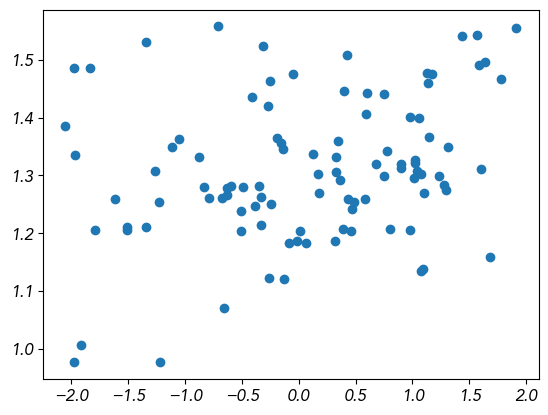

In [167]:
plt.plot(source_sink_S[:100], my_grad,'o');

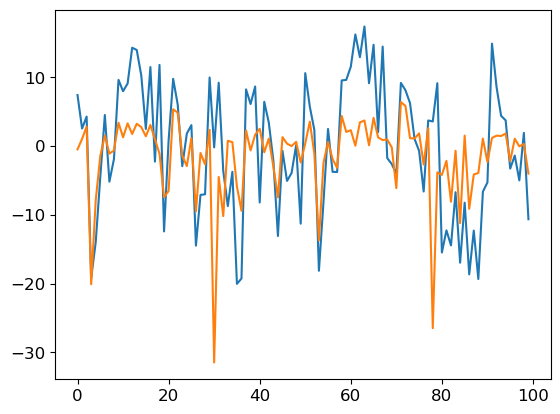

In [50]:
plt.plot(source_sink_S)
plt.plot(ssi_mean_abs*100)

In [33]:
source_sink_S =np.mean(np.sum(S_s[:,:100,:100],0),0)
print(S_s.shape)

(1013, 112, 112)


In [58]:
## check se numero communtiy sbm cambia con soglia
## check sink source fatto da differential cross covariance
## check come vengono time scale del segnale stimate...

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18])

In [ ]:
### correlare con mappe date da luca e con asse z
# descrivere hrf

In [64]:
ssi_mean.shape

(100,)

In [111]:
import numpy as np
import nibabel as nib
import pandas as pd

atlas_path = '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'

img = nib.load(atlas_path)
data = img.get_fdata()
affine = img.affine

rows = []

for roi in range(1, 101):

    # voxel appartenenti alla parcella roi
    vox = np.array(np.where(data == roi)).T

    if vox.shape[0] == 0:
        rows.append({
            "roi": roi,
            "x": np.nan,
            "y": np.nan,
            "z": np.nan
        })
        continue

    # coordinate MNI di tutti i voxel della parcella
    mni_coords = nib.affines.apply_affine(affine, vox)

    # centroide medio in MNI
    centroid = mni_coords.mean(axis=0)

    rows.append({
        "roi": roi,
        "x": centroid[0],
        "y": centroid[1],
        "z": centroid[2]
    })

coords_df = pd.DataFrame(rows)

coords_df.head()

,roi,x,y,z
0,1,-25.737496,-32.890730,-17.216311
1,2,-25.453702,-76.772003,-13.582332
2,3,-16.365642,-60.910559,-6.716181
3,4,-27.227118,-94.463081,-4.660665
4,5,-5.459609,-92.129488,-2.787883


In [ ]:

# =========================================================
# (e) / (f) BRAIN MAPS - K-OUT AND K-IN DEGREE
# =========================================================

I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)

data = I1.get_fdata()
affine = I1.affine

A = media[:100, :100].copy()
A[~sig_mask] = 0
np.fill_diagonal(A, 0)

# binary degree: number of significant directed links
k_out = np.mean(out_strength,0)
k_in = np.mean(in_strength,0)
#np.sum(np.abs(A) , axis=1)
#k_in = np.sum(np.abs(A), axis=0)

data_kout = np.zeros_like(data)
data_kin = np.zeros_like(data)

for r in range(100):
    data_kout[data == r + 1] = k_out[r]
    data_kin[data == r + 1] = k_in[r]

img_kout = nib.Nifti1Image(data_kout, affine)
img_kin = nib.Nifti1Image(data_kin, affine)

vmax_degree = max(k_out.max(), k_in.max())

display=plotting.plot_stat_map(
    img_kout,
    cmap=reds,
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_out,
    vmin=1.5
    ,
    vmax=vmax_degree
)


for ax in display.axes.values():
    for text in ax.ax.texts:
        text.set_fontsize(30)
ax_brain_out.set_title("K-out strength: outgoing significant links", pad=10, fontsize =20)

display=plotting.plot_stat_map(
    img_kin,
    cmap=reds,
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_in,
    vmin=1.5,
    vmax=vmax_degree
)

ax_brain_in.set_title("K-in strength: incoming significant links", pad=10, fontsize =20)

norm = Normalize(vmin=1.5, vmax=vmax_degree)
sm = ScalarMappable(norm=norm, cmap=reds)
sm.set_array([])

cax = fig.add_axes([0.92, 0.12, 0.015, 0.18])

cbar=fig.colorbar(
    sm,
    cax=cax,
    label='Strength',
)
cbar.set_label('Strength', fontsize=20)
cbar.ax.tick_params(labelsize=20)
# =========================================================
# FINAL LAYOUT AND PANEL LABELS
# =========================================================


In [53]:
from scipy import stats
stats.spearmanr(coords_df['z'],np.sum(np.mean(S_s[:,:100,:100],0),0))

SignificanceResult(statistic=np.float64(-0.06913891389138914), pvalue=np.float64(0.4942813260674076))

In [71]:
from scipy import stats
stats.spearmanr(coords_df['y'],ssi_mean)

SignificanceResult(statistic=np.float64(-0.3934833483348334), pvalue=np.float64(5.121761221691089e-05))

In [100]:

C = dediag(np.mean(JS,0).T)[:100,:100]
C[significant_mask[:100,:100]] = 0

thr = np.percentile(np.abs(C), 60)
C_thr = C 
#* (np.abs(C) >= thr)

in_strength  = np.sum(np.abs(C_thr), axis=1)
out_strength = np.sum(np.abs(C_thr), axis=0)
ssi_norm_glob = (out_strength- in_strength) / \
                      (out_strength + in_strength+ 1e-12)
print(stats.pearsonr(ssi_norm_glob,first_grad))


PearsonRResult(statistic=np.float64(-0.21993781787202524), pvalue=np.float64(0.027897558147787768))


(array([ 1.,  4.,  6., 13., 16., 22., 20.,  6.,  6.,  6.]),
 array([-0.66203254, -0.53830759, -0.41458264, -0.2908577 , -0.16713275,
        -0.0434078 ,  0.08031715,  0.2040421 ,  0.32776705,  0.451492  ,
         0.57521695]),
 <BarContainer object of 10 artists>)

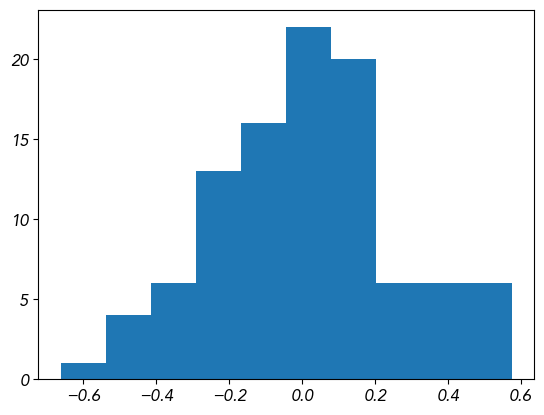

In [101]:
plt.hist(ssi_norm_glob)

In [112]:
first_grad = np.load('../numpy files/fgradient1_sh100.npy')
my

[[1.         0.36017254]
 [0.36017254 1.        ]]


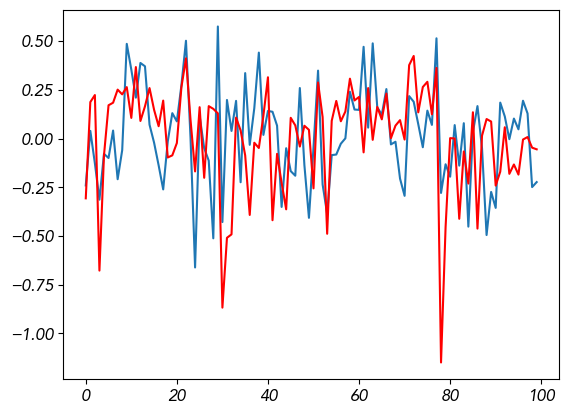

In [110]:
plt.plot(ssi_norm_glob)
plt.plot(ssi_mean*10, 'r')
print(np.corrcoef(ssi_mean*10, ssi_norm_glob))

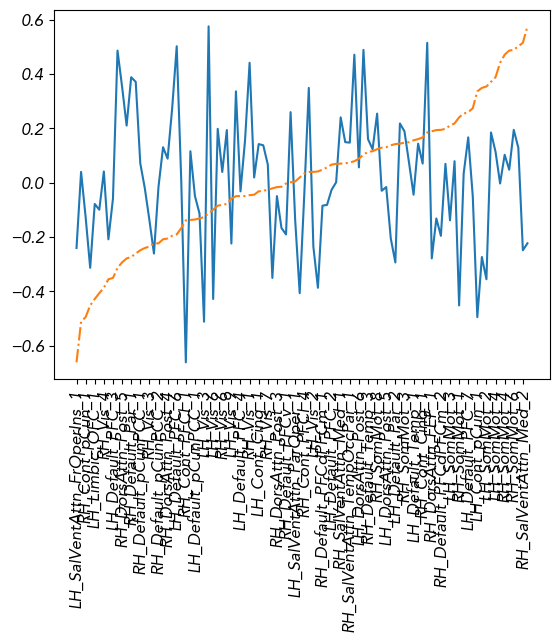

In [105]:
plt.plot(ssi_norm_glob)
np.corrcoef(ssi_norm_glob, first_grad)

plt.plot(np.sort(ssi_norm_glob),'-.')
plt.xticks(np.arange(0,100,2),np.array(labels100)[np.argsort(ssi_norm_glob)][::2], rotation=90);

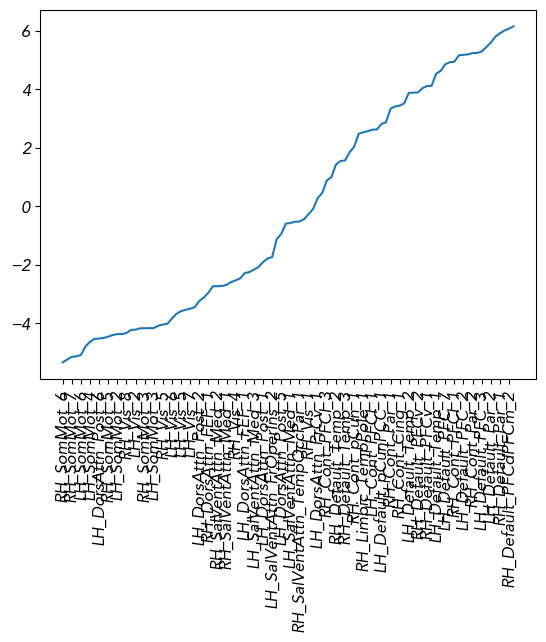

In [104]:
#plt.plot(first_grad)
plt.plot(np.sort(first_grad))
plt.xticks(np.arange(0,100,2),np.array(labels100)[np.argsort(first_grad)][::2], rotation=90);

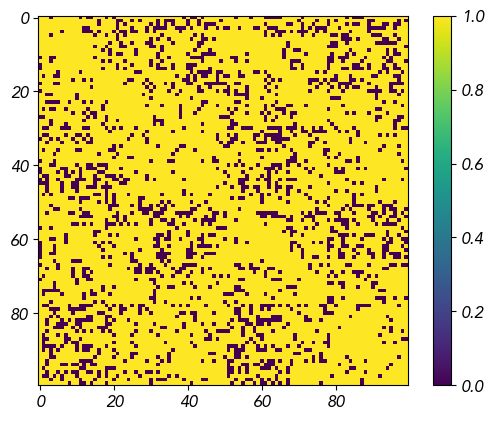

In [81]:
plt.imshow(significant_mask)
plt.colorbar()

In [1]:
import numpy as np




#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')#[:,:100,:100]
#JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')
#JS_2 = np.load('numpy files/EC_matrix_HCP2_200_converged.npy')#[:,:100,:100]


JS = np.load('../numpy files/EC_matrix_HCP1_100.npy')#[:,:100,:100]
#JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')
JS_2 = np.load('../numpy files/EC_matrix_HCP2_100.npy')#[:,:100,:100]


n_subjects, N, _ = JS.shape

ssi_norm_all = np.zeros((n_subjects, N-12))

for s in range(n_subjects):
    C = dediag(JS[s].T)[:100,:100]
    #C[np.logical_not(significant_mask[:100,:100])] = 0
    
    thr = np.percentile(np.abs(C), 20)
    C_thr = C
    #* (np.abs(C) >= thr)

    in_strength  = np.sum((C_thr), axis=1)
    out_strength = np.sum((C_thr), axis=0)

    ssi_norm_all[s] = (out_strength - in_strength) / \
                      (out_strength + in_strength + 1e-12)

prop_source = np.mean(ssi_norm_all > 0, axis=0)
prop_sink   = np.mean(ssi_norm_all < 0, axis=0)


"""

n_subjects, N, _ = JS.shape

ssi_norm_all = np.zeros((n_subjects, N))

for s in range(n_subjects):
    C = dediag(JS_2[s].T)
    
    
    thr = np.percentile(np.abs(C), 60)
    C_thr = C 
    #* (np.abs(C) >= thr

    in_strength  = np.sum(np.abs(C_thr), axis=1)
    out_strength = np.sum(np.abs(C_thr), axis=0)

    ssi_norm_all[s] = (out_strength - in_strength) / \
                      (out_strength + in_strength + 1e-12)

prop_source_2 = np.mean(ssi_norm_all > 0, axis=0)
prop_sink_2   = np.mean(ssi_norm_all < 0, axis=0)
prop_source_2.shape
"""
ssi_mean = np.mean(np.asarray(ssi_norm_all),0)
print(stats.pearsonr(ssi_mean,first_grad))
print(-0.3385302802098624,0.0005709558919608994)

NameError: name 'dediag' is not defined

In [2]:
whos

Variable       Type       Data/Info
-----------------------------------
JS             ndarray    1013x112x112: 12707072 elems, type `float64`, 101656576 bytes (96.947265625 Mb)
JS_2           ndarray    1013x112x112: 12707072 elems, type `float64`, 101656576 bytes (96.947265625 Mb)
N              int        112
n_subjects     int        1013
np             module     <module 'numpy' from '/ho<...>kages/numpy/__init__.py'>
s              int        0
ssi_norm_all   ndarray    1013x100: 101300 elems, type `float64`, 810400 bytes (791.40625 kb)


## differential cross covariance

In [17]:
import numpy as np


def differential_cross_covariance(J, Q0, absolute = False):
    """
    Complete differential cross-covariance:

        D = J @ Q0

    Parameters
    ----------
    J : array, shape (n_roi, n_roi)
        Effective connectivity matrix.

    Q0 : array, shape (n_roi, n_roi)
        Zero-lag covariance matrix.

    Returns
    -------
    D : array, shape (n_roi, n_roi)
        Differential cross-covariance.
    """

    J = np.asarray(J, dtype=float)
    Q0 = np.asarray(Q0, dtype=float)

    if J.shape != Q0.shape:
        raise ValueError(
            f"J and Q0 must have the same shape. "
            f"Got J={J.shape}, Q0={Q0.shape}."
        )
    if absolute:
        J = np.abs(J)
    return J @ Q0


def antisymmetric_differential_cross_covariance(J, Q0, absolute = False):
    """
    Antisymmetric differential cross-covariance:

        S = (J @ Q0 - Q0 @ J.T) / 2
    """

    D = differential_cross_covariance(J, Q0, absolute)

    return 0.5 * ((D) - (D).T)
        
#rcellated/Schaefer200+AAL/'

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
fc_1 = []
sub_tot=[]
for sub in tqdm(pat[:]):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)
            fc_1.append(np.corrcoef(data_ref,rowvar=False))
            #print('here')
#J = np.mean(JS,0).T
#S =antisymmetric_differential_cross_covariance(J, Q0)

100%|██████████| 1097/1097 [00:18<00:00, 58.63it/s]


In [ ]:
dediag(

In [16]:
np.asarray(fc_1).shape

(1013, 112, 112)

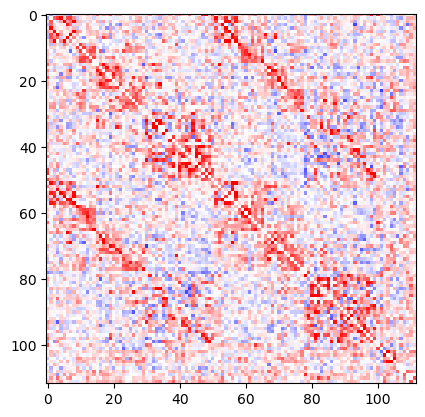

In [17]:
plt.imshow(dediag(JS[-1]), cmap='bwr', vmin=-.1, vmax=.1);

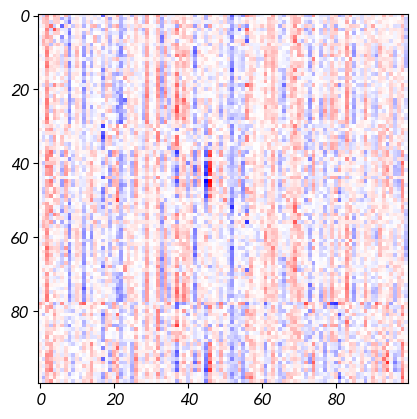

In [243]:
plt.imshow(S[:100,:100]@np.linalg.inv(fc_1[-1][:100,:100]), cmap ='bwr');

In [47]:
import numpy as np

#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')#[:,:100,:100]
#JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')
#JS_2 = np.load('numpy files/EC_matrix_HCP2_200_converged.npy')#[:,:100,:100]


JS = np.load('../numpy files/EC_matrix_HCP1_100.npy')#[:,:100,:100]
#JS_dcm = np.load('numpy files/EC_dcm_HCP1_74.npy')
JS_2 = np.load('../numpy files/EC_matrix_HCP2_100.npy')#[:,:100,:100]


n_subjects, N, _ = JS.shape

ssi_norm_all = np.zeros((n_subjects, N-12))

for s in range(n_subjects):
    C = dediag(JS[s].T)[:100,:100]
    #C[np.logical_not(significant_mask[:100,:100])] = 0
    
    thr = np.percentile(np.abs(C), 60)
    C_thr = C 
    #* (np.abs(C) >= thr)

    in_strength  = np.sum(np.abs(C_thr), axis=1)
    out_strength = np.sum(np.abs(C_thr), axis=0)

    ssi_norm_all[s] = (out_strength - in_strength) / \
                      (out_strength + in_strength + 1e-12)

prop_source = np.mean(ssi_norm_all > 0, axis=0)
prop_sink   = np.mean(ssi_norm_all < 0, axis=0)


"""

n_subjects, N, _ = JS.shape

ssi_norm_all = np.zeros((n_subjects, N))

for s in range(n_subjects):
    C = dediag(JS_2[s].T)
    
    
    thr = np.percentile(np.abs(C), 60)
    C_thr = C 
    #* (np.abs(C) >= thr

    in_strength  = np.sum(np.abs(C_thr), axis=1)
    out_strength = np.sum(np.abs(C_thr), axis=0)

    ssi_norm_all[s] = (out_strength - in_strength) / \
                      (out_strength + in_strength + 1e-12)

prop_source_2 = np.mean(ssi_norm_all > 0, axis=0)
prop_sink_2   = np.mean(ssi_norm_all < 0, axis=0)
prop_source_2.shape
"""
ssi_mean = np.mean(np.asarray(ssi_norm_all),0)


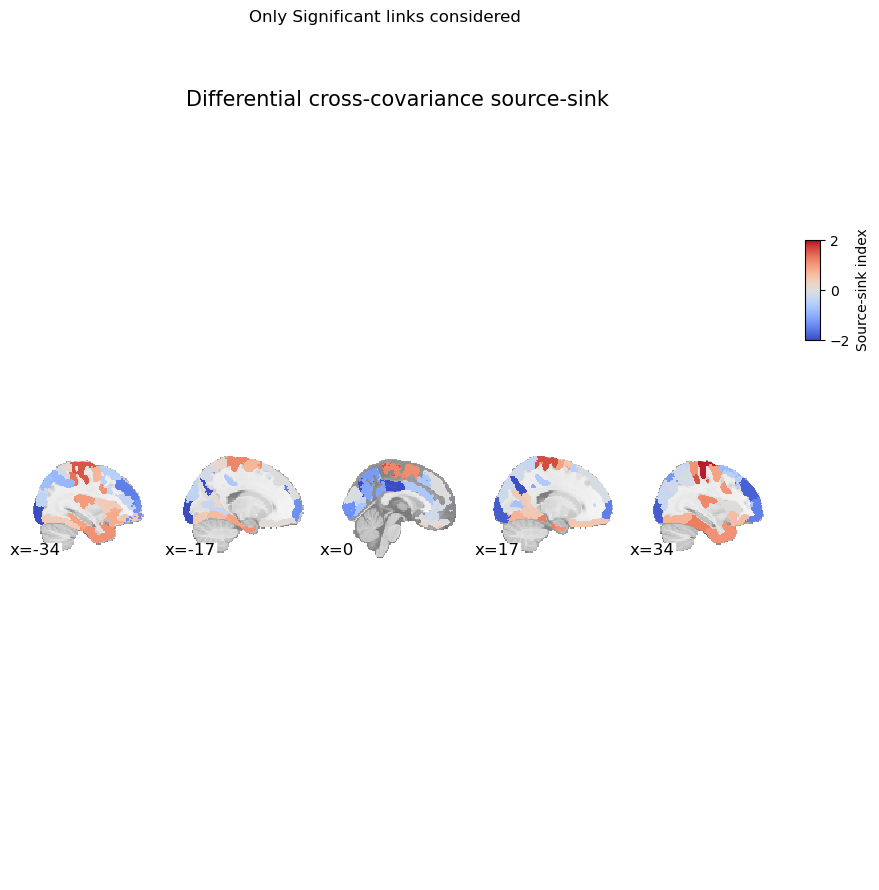

In [72]:
# =========================================================
fig, ax =plt.subplots(1,1,figsize =(10,10))
I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)
fig.suptitle('Only Significant links considered')
data = I1.get_fdata()
affine = I1.affine

# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 2

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax,
    vmin=-numero,
    vmax=numero
)

ax.set_title(
    "Differential cross-covariance source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.65, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=10)


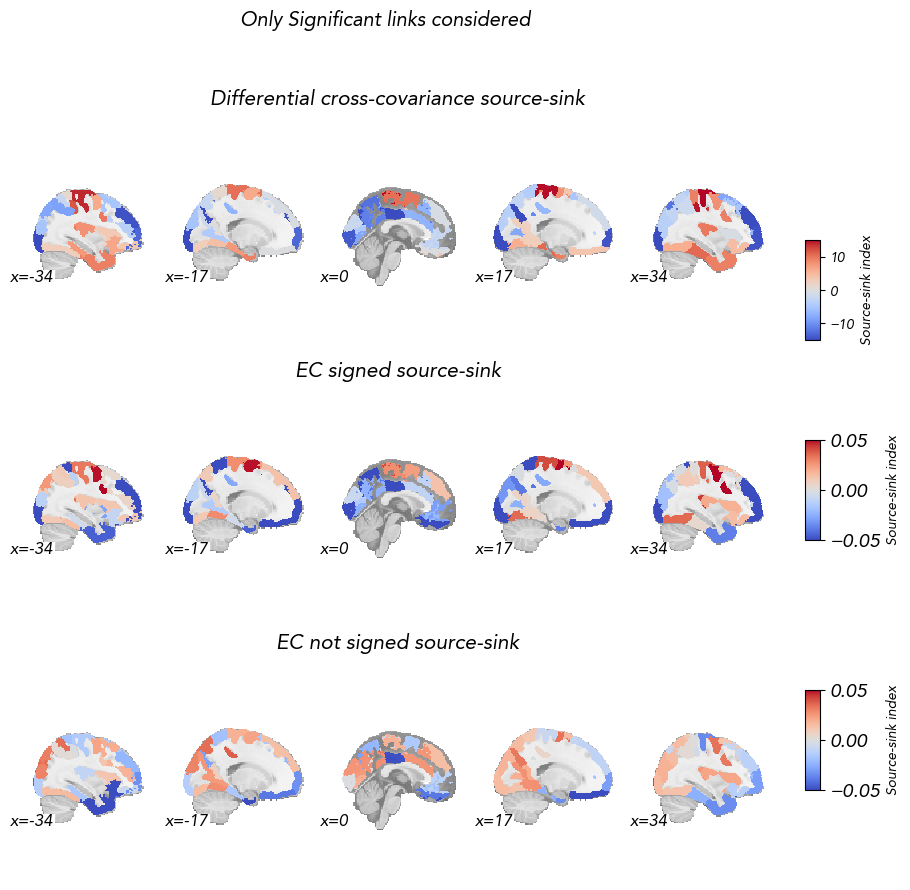

In [76]:
# =========================================================
# (e) BRAIN MAP - SOURCE-SINK INDEX
# =========================================================
fig, ax =plt.subplots(3,1,figsize =(10,10))
I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)
fig.suptitle('Only Significant links considered')
data = I1.get_fdata()
affine = I1.affine

# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 15

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[0],
    vmin=-numero,
    vmax=numero
)

ax[0].set_title(
    "Differential cross-covariance source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.65, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=10)




# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean_No_abs[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[1],
    vmin=-numero,
    vmax=numero
)

ax[1].set_title(
    "EC signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.45, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='EC signed source-sink'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)




# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[2],
    vmin=-numero,
    vmax=numero
)

ax[2].set_title(
    "EC not signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.2, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)



correlation with z axis
diff cross cov SignificanceResult(statistic=np.float64(-0.06913891389138914), pvalue=np.float64(0.4942813260674076))
signed ec SignificanceResult(statistic=np.float64(0.07657965796579656), pvalue=np.float64(0.44888115992605004))
not signed ec SignificanceResult(statistic=np.float64(0.34527452745274523), pvalue=np.float64(0.00043451609912508967))
correlation with first grad
diff cross cov SignificanceResult(statistic=np.float64(-0.47279927992799275), pvalue=np.float64(6.798654188718231e-07))
signed ec SignificanceResult(statistic=np.float64(-0.4108490849084908), pvalue=np.float64(2.1772798653225e-05))
not signed ec SignificanceResult(statistic=np.float64(-0.46655865586558654), pvalue=np.float64(9.949569030936315e-07))
correlation with mielyn grad
diff cross cov SignificanceResult(statistic=np.float64(0.24044404440444042), pvalue=np.float64(0.01596675685263438))
signed ec SignificanceResult(statistic=np.float64(0.3077947794779477), pvalue=np.float64(0.001837912966

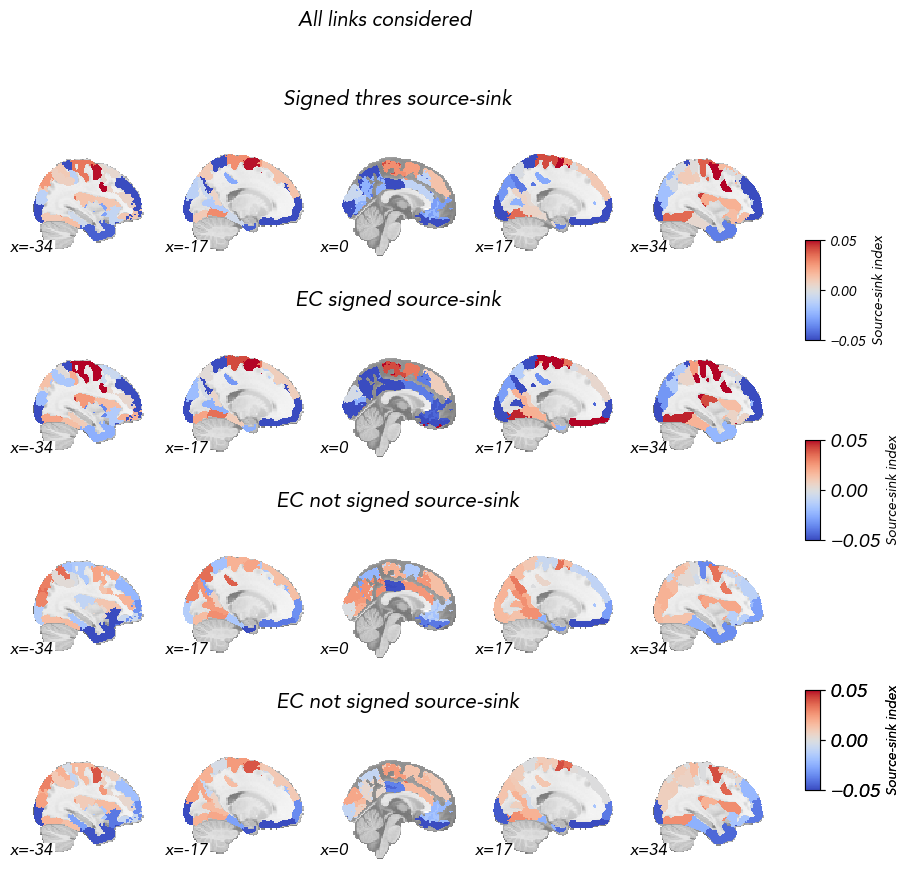

In [84]:
# =========================================================
# (e) BRAIN MAP - SOURCE-SINK INDEX
# =========================================================
fig, ax =plt.subplots(4,1,figsize =(10,10))
I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)
fig.suptitle('All links considered')
data = I1.get_fdata()
affine = I1.affine

# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean_No_abs_thres[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[0],
    vmin=-numero,
    vmax=numero
)

ax[0].set_title(
    "Signed thres source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.65, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=10)




# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean_No_abs[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[1],
    vmin=-numero,
    vmax=numero
)

ax[1].set_title(
    "EC signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.45, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='EC signed source-sink'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)




# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean__thres[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[2],
    vmin=-numero,
    vmax=numero
)

ax[2].set_title(
    "EC not signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.2, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)



# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[3],
    vmin=-numero,
    vmax=numero
)

ax[3].set_title(
    "EC not signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.2, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)


print('correlation with z axis')
print('diff cross cov',stats.spearmanr(coords_df['z'], source_sink_S))
print('signed ec',stats.spearmanr(coords_df['z'], ssi_mean_No_abs))
print('not signed ec',stats.spearmanr(coords_df['z'], ssi_mean))

print('correlation with first grad')
print('diff cross cov',stats.spearmanr(first_grad, source_sink_S))
print('signed ec',stats.spearmanr(first_grad, ssi_mean_No_abs))
print('not signed ec',stats.spearmanr(first_grad, ssi_mean))

print('correlation with mielyn grad')
print('diff cross cov',stats.spearmanr(my_grad, source_sink_S))
print('signed ec',stats.spearmanr(my_grad, ssi_mean_No_abs))
print('not signed ec',stats.spearmanr(my_grad, ssi_mean))


correlation with z axis
diff cross cov (corrvalue +pvalue) -0.06913891389138914 0.4942813260674076
signed ec 0.07657965796579656 0.44888115992605004
not signed ec 0.34527452745274523 0.00043451609912508967
correlation with first grad
diff cross cov -0.47279927992799275 6.798654188718231e-07
signed ec -0.4108490849084908 2.1772798653225e-05
not signed ec -0.46655865586558654 9.949569030936315e-07
correlation with mielyn grad
diff cross cov 0.24044404440444042 0.01596675685263438
signed ec 0.3077947794779477 0.001837912966253104
not signed ec 0.4252985298529853 1.0297454146661446e-05


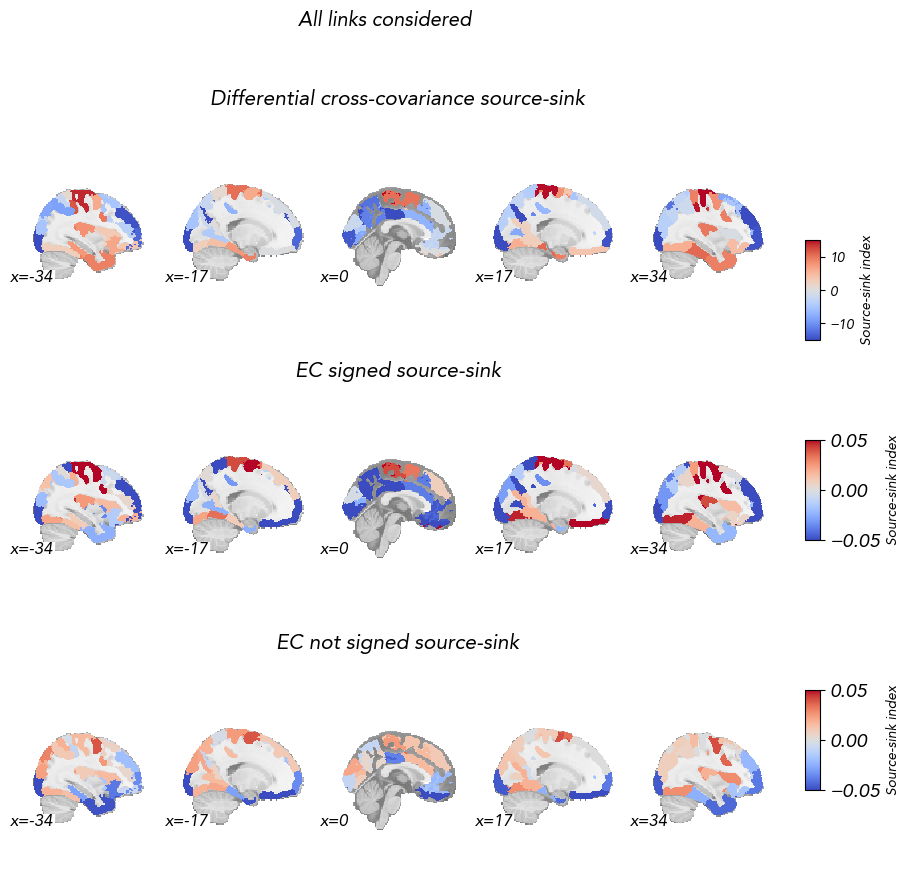

In [92]:
# =========================================================
# (e) BRAIN MAP - SOURCE-SINK INDEX
# =========================================================
fig, ax =plt.subplots(3,1,figsize =(10,10))
I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)
fig.suptitle('All links considered')
data = I1.get_fdata()
affine = I1.affine

# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 15

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[0],
    vmin=-numero,
    vmax=numero
)

ax[0].set_title(
    "Differential cross-covariance source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.65, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=10)




# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean_No_abs[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[1],
    vmin=-numero,
    vmax=numero
)

ax[1].set_title(
    "EC signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.45, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='EC signed source-sink'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)




# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = ssi_mean[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 0.05

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[2],
    vmin=-numero,
    vmax=numero
)

ax[2].set_title(
    "EC not signed source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.2, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='Source-sink index'
)

cbar_ssi.set_label('Source-sink index', fontsize=10)
cbar_ssi.ax.tick_params(labelsize=14)
print('correlation with z axis')
print('diff cross cov (corrvalue +pvalue)',stats.spearmanr(coords_df['z'], source_sink_S).statistic, stats.spearmanr(coords_df['z'], source_sink_S).pvalue)
print('signed ec',stats.spearmanr(coords_df['z'], ssi_mean_No_abs).statistic,stats.spearmanr(coords_df['z'], ssi_mean_No_abs).pvalue)
print('not signed ec',stats.spearmanr(coords_df['z'], ssi_mean).statistic, stats.spearmanr(coords_df['z'], ssi_mean).pvalue)

print('correlation with first grad')
print('diff cross cov',stats.spearmanr(first_grad, source_sink_S).statistic, stats.spearmanr(first_grad, source_sink_S).pvalue)
print('signed ec',stats.spearmanr(first_grad, ssi_mean_No_abs).statistic,stats.spearmanr(first_grad, ssi_mean_No_abs).pvalue)
print('not signed ec',stats.spearmanr(first_grad, ssi_mean).statistic, stats.spearmanr(first_grad, ssi_mean).pvalue)

print('correlation with mielyn grad')
print('diff cross cov',stats.spearmanr(my_grad, source_sink_S).statistic,stats.spearmanr(my_grad, source_sink_S).pvalue)
print('signed ec',stats.spearmanr(my_grad, ssi_mean_No_abs).statistic,stats.spearmanr(my_grad, ssi_mean_No_abs).pvalue)
print('not signed ec',stats.spearmanr(my_grad, ssi_mean).statistic,stats.spearmanr(my_grad, ssi_mean).pvalue)


In [119]:
from scipy import stats
stats.spearmanr(source_sink_S[:100], first_grad)
stats.spearmanr(source_sink_S[:100], my_grad)
stats.spearmanr(source_sink_S[:100], coords_df['z'])


SignificanceResult(statistic=np.float64(-0.07589558955895588), pvalue=np.float64(0.4529552396410834))

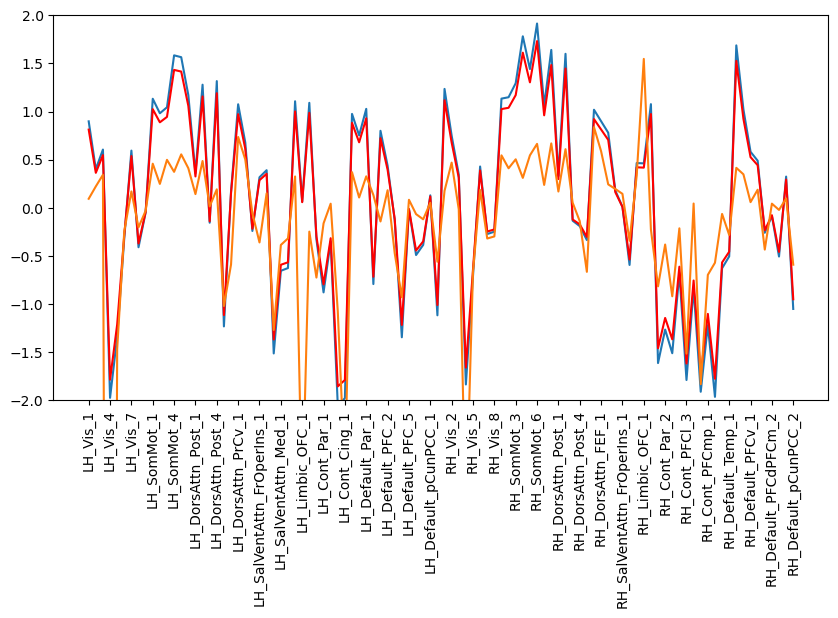

In [105]:
plt.figure(figsize=(10,5))
#labels_100= np.asarray(labels_100, dtype=str)
#labels_100[0]
len(labels)
labels100=[]
for i in labels[:]:
    labels100.append(i[10:])
labels100[:3]
plt.plot(source_sink_S[:100])
plt.plot(source_sink_SS[:100]*0.1,color='red')

plt.plot(ssi_mean_noabs*10)
plt.ylim(-2.,2);
plt.xticks(np.arange(0,100,3),labels100[::3], rotation=90);

In [125]:
stats.spearmanr(source_sink_S[:100], my_grad)
dcm = np.load('../numpy files/EC_dcm_HCP1_74.npy')[:,:62,:62]
dcm.shape

(155, 62, 62)

In [227]:
mapping

array([ 1,  2,  2,  2,  2,  2,  2,  2,  2,  3,  3,  3,  4,  5,  5,  6,  7,
        8,  7,  8,  7,  9,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
       21, 22, 23, 24, 24, 25, 24, 26, 27, 28, 29, 28, 30, 31, 32, 32, 33,
       34, 34, 34, 35, 35, 34, 35, 36, 36, 36, 37, 38, 38, 38, 38, 39, 40,
       41, 41, 42, 43, 43, 44, 45, 46, 47, 47, 48, 49, 50, 51, 52, 52, 53,
       52, 54, 55, 54, 56, 57, 58, 58, 59, 59, 60, 60, 61, 62, 62])

In [132]:
import numpy as np

# FC originale: shape (100, 100)
# mapping originale: l'array che hai mostrato, shape (N, 1)
fc_62 =[]
for i in range(len(fc_1)):
    FC_100 =fc_1[i]
    map_100_to_62 = np.asarray(mapping).squeeze()[:100].astype(int)
    
    #print(map_100_to_62.shape)       # (100,)
    ##print(map_100_to_62.min())       # dovrebbe essere 1
    #print(map_100_to_62.max())       # dovrebbe essere 62
    
    FC_62 = np.full((62, 62), np.nan)
    
    for i in range(1, 63):
        idx_i = np.where(map_100_to_62 == i)[0]
    
        for j in range(1, 63):
            idx_j = np.where(map_100_to_62 == j)[0]
    
            # Sottomatrice contenente tutte le connessioni
            # tra le parcelle fini dei gruppi i e j
            block = FC_100[np.ix_(idx_i, idx_j)]
    
            FC_62[i - 1, j - 1] = np.nanmean(block)
    fc_62.append(FC_62)
    #print(FC_62.shape)  # (62, 62)

In [141]:
ikk=[]
pat = '/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'
for i in os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'):
    if i[-10:-4] in sub_tot:
        ikk.append(i[-10:-4])
sub_tot = np.asarray(sub_tot)        
ikk = np.sort(ikk)
indicia = np.asarray([np.where(ikk[i]==sub_tot)[0] for i in range(len(ikk))]).reshape(-1)
len(indicia)

155

In [145]:
indicia

array([  2,   3,   4,   7,   8,   9,  10,  11,  12,  13,  14,  15,  16,
        17,  18,  19,  20,  21,  22,  24,  25,  26,  27,  28,  29,  30,
        31,  32,  33,  34,  35,  36,  40,  42,  43,  44,  45,  46,  47,
        48,  49,  50,  51,  52,  53,  54,  55,  56,  57,  58,  59,  62,
        63,  64,  65,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,
        82,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,
        95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107,
       109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121,
       122, 123, 124, 125, 126, 127, 128, 129, 130, 136, 137, 138, 139,
       141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 156, 157,
       158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 170, 171,
       172, 173, 174, 175, 176, 177, 178, 179, 180, 186, 187, 188])

In [143]:
S_s_dcm =[]
mean =np.asarray(np.mean(fc_62,0))
for i in range(len(dcm)):
    S =antisymmetric_differential_cross_covariance(dcm[i],np.array(fc_62)[indicia][i] , False)
    S_s_dcm.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s_dcm = np.asarray(S_s_dcm)
source_sink_dcm= np.sum(np.mean(S_s_dcm,0),0)


(100,)


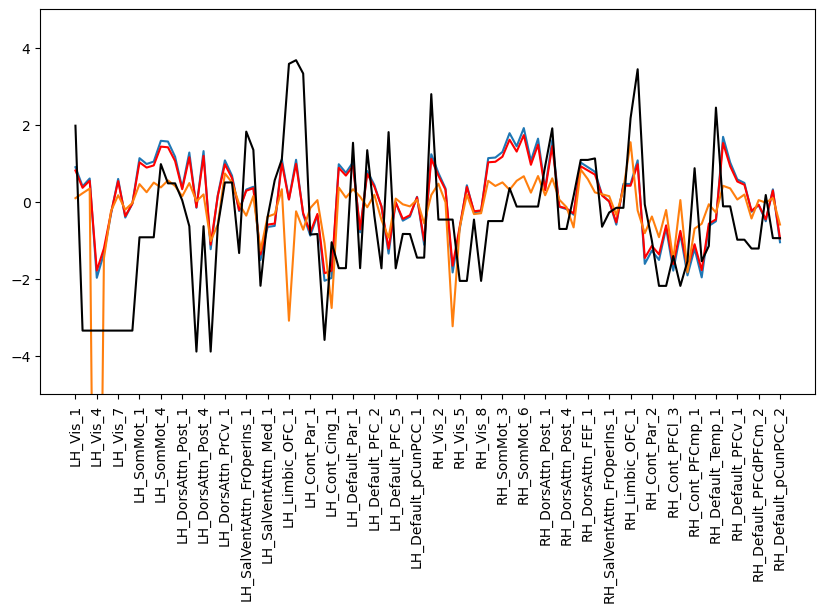

In [144]:
plt.figure(figsize=(10,5))
mapping = aggregate[:100].squeeze().astype(int)  # shape (100,)
mapping0 = mapping - 1                   # da indici 1-based a 0-based
mapping0.shape
x_100 = source_sink_dcm[mapping0]

print(x_100.shape)  # (100,

#labels_100= np.asarray(labels_100, dtype=str)
#labels_100[0]
len(labels)
labels100=[]
for i in labels[:]:
    labels100.append(i[10:])
labels100[:3]
plt.plot(source_sink_S[:100])
plt.plot(source_sink_SS[:100]*0.1,color='red')

plt.plot(ssi_mean_noabs*10)
plt.plot(x_100,color='black')


plt.ylim(-5.,5);
plt.xticks(np.arange(0,100,3),labels100[::3], rotation=90);

In [189]:
#len(labels)
labels100[:4]

['LH_Vis_1', 'LH_Vis_2', 'LH_Vis_3', 'LH_Vis_4']

In [218]:
np.sum(S_s,0).shape

(112, 112)

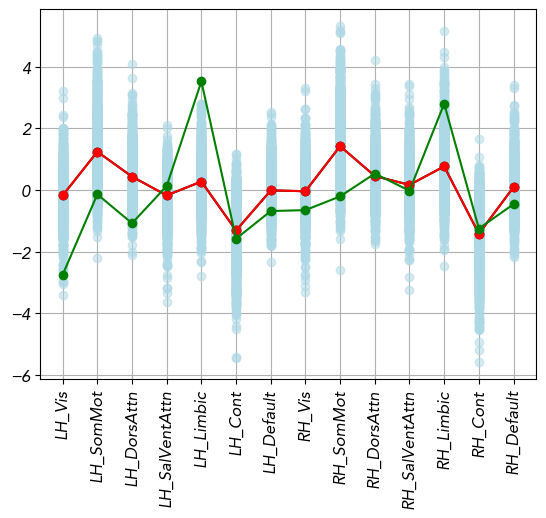

In [232]:
import numpy as np

# INPUT:
# labels = array/lista con nomi tipo 'LH_Vis_1', ..., 'RH_Default_...'
# values = vettore di 100 valori
# matrix = eventuale matrice 100x100 da riordinare (opzionale)
def reduction(vettore, labels):
    labels = np.asarray(labels)
    values = np.asarray(vettore[:100])
    
    if labels.shape[0] != values.shape[0]:
        raise ValueError("labels e values devono avere la stessa lunghezza")
    
    # Ordine desiderato delle 14 network
    network_order = [
        "LH_Vis",
        "LH_SomMot",
        "LH_DorsAttn",
        "LH_SalVentAttn",
        "LH_Limbic",
        "LH_Cont",
        "LH_Default",
        "RH_Vis",
        "RH_SomMot",
        "RH_DorsAttn",
        "RH_SalVentAttn",
        "RH_Limbic",
        "RH_Cont",
        "RH_Default",
    ]
    
    # Estrae LH_Vis da LH_Vis_1
    network_labels = np.array([
        "_".join(label.split("_")[:2])
        for label in labels
    ])
    
    # Indici delle parcelle appartenenti a ciascuna network
    indices_by_network = {
        network: np.where(network_labels == network)[0]
        for network in network_order
    }
    
    # Controllo delle network trovate
    missing_networks = [
        network for network in network_order
        if len(indices_by_network[network]) == 0
    ]
    
    if missing_networks:
        raise ValueError(
            f"Network non trovate nei labels: {missing_networks}\n"
            f"Network rilevate: {np.unique(network_labels)}"
        )
    
    # Vettori separati per network
    values_by_network = {
        network: values[indices_by_network[network]]
        for network in network_order
    }
    
    # Riordina tutte le 100 parcelle per network
    ordered_indices = np.concatenate([
        indices_by_network[network]
        for network in network_order
    ])
    
    values_ordered = values[ordered_indices]
    labels_ordered = labels[ordered_indices]
    
    # Media del vettore entro ciascuna delle 14 network
    network_means = np.array([
        np.nanmean(values_by_network[network])
        for network in network_order
    ])
    """
    # Stampa riepilogo
    for network, idx, mean_value in zip(
        network_order,
        [indices_by_network[n] for n in network_order],
        network_means
    ):
        print(
            f"{network:18s} "
            f"n_parcelle = {len(idx):2d} | "
            f"media = {mean_value:.4f}"
        )
    """
    #print("\nShape vettore originale:", values.shape)
    #print("Shape vettore riordinato:", values_ordered.shape)
    #print("Shape vettore aggregato:", network_means.shape)
    return network_order, network_means
# Per riordinare anche una matrice 100x100, decommenta:
# matrix = np.asarray(matrix)
# matrix_ordered = matrix[np.ix_(ordered_indices, ordered_indices)]


S_s =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], False)
    S_s.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
    #S_s = np.asarray(S_s)
    source_sink_S_i = np.sum(np.asarray(S),0)
    _, red =reduction(source_sink_S_i[:100], labels100)
    #plt.hist(source_sink_S)
    plt.plot(red, 'o', color='lightblue', alpha=.5)


S_s  = np.asarray(S_s)
source_sink_S =  np.sum(np.mean(S_s,0),0)
_, red_mean =reduction(source_sink_S[:100], labels100)
plt.plot(red_mean, '-o',color='k')



S_s  = np.asarray(S_s)
source_sink_S =  np.mean(np.sum(S_s,1),0)
_, red_mean =reduction(source_sink_S[:100], labels100)

# = 
plt.plot(red_mean, '-o',color='r')

# ============================================================

# = 
plt.plot(network_means, '-o',color='g')


#plt.xticks(np.arange(0,14,1), labels =_, rotation =90);
#plt.grid()
plt.xticks(np.arange(0,14,1), labels =_, rotation =90);
plt.grid()






In [32]:
S_s.shape

(1013, 112, 112)

Shape vettori originali: (1013, 112)
Shape S_s: (1013, 112, 112)
Shape vettori 112: (1013, 112)
Shape corticali 100: (1013, 100)
Shape corticali aggregate: (1013, 62)
Shape sottocorticali: (1013, 12)
Shape finale: (1013, 74)
Shape media: (74,)

Numero regioni LH corticali: 32
Numero regioni LH totali: 38
Numero regioni RH totali: 36


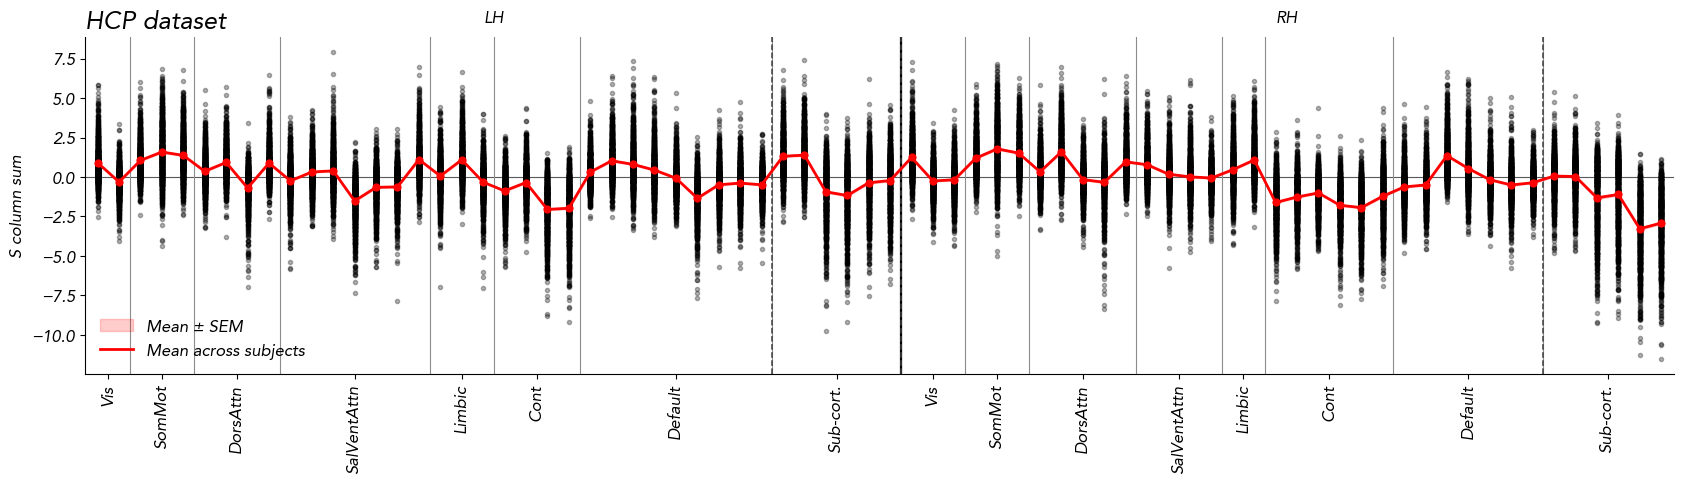

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ============================================================
# INPUT
# ============================================================

# Matrice soggetti × parcelle Schaefer-100
# Esempio: values_all.shape = (1013, 100)
values_all = np.asarray(np.sum(S_s[:,:100,:100],1), dtype=float)

# Label delle 100 parcelle:
# ['LH_Vis_1', ..., 'RH_Default_...']
labels_100 = np.asarray(labels_100)

mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

network_order = [
    "LH_Vis",
    "LH_SomMot",
    "LH_DorsAttn",
    "LH_SalVentAttn",
    "LH_Limbic",
    "LH_Cont",
    "LH_Default",
    "RH_Vis",
    "RH_SomMot",
    "RH_DorsAttn",
    "RH_SalVentAttn",
    "RH_Limbic",
    "RH_Cont",
    "RH_Default"
]

network_display_names = {
    "LH_Vis": "Vis",
    "LH_SomMot": "SomMot",
    "LH_DorsAttn": "DorsAttn",
    "LH_SalVentAttn": "SalVentAttn",
    "LH_Limbic": "Limbic",
    "LH_Cont": "Cont",
    "LH_Default": "Default",
    "RH_Vis": "Vis",
    "RH_SomMot": "SomMot",
    "RH_DorsAttn": "DorsAttn",
    "RH_SalVentAttn": "SalVentAttn",
    "RH_Limbic": "Limbic",
    "RH_Cont": "Cont",
    "RH_Default": "Default"
}


# ============================================================
# FUNZIONI
# ============================================================

def extract_network(label):
    """
    Estrae la network da label tipo:
        LH_Vis_1
        7Networks_LH_Vis_1
    """
    parts = str(label).split("_")

    if parts[0] in ("LH", "RH"):
        return "_".join(parts[:2])

    if len(parts) >= 3 and parts[1] in ("LH", "RH"):
        return "_".join(parts[1:3])

    raise ValueError(f"Formato label non riconosciuto: {label}")


def prepare_62_network_order(
    labels_100,
    mapping_100_to_62,
    network_order
):
    """
    Costruisce una sola volta:
    - network delle 100 parcelle;
    - network dominante di ciascuna parcella 62;
    - ordine delle 62 parcelle per network;
    - confini e centri per il plot.
    """

    labels_100 = np.asarray(labels_100)
    mapping_100_to_62 = np.asarray(mapping_100_to_62)

    if len(labels_100) != 100:
        raise ValueError(
            f"labels_100 deve avere lunghezza 100, non {len(labels_100)}"
        )

    if len(mapping_100_to_62) != 100:
        raise ValueError(
            "mapping_100_to_62 deve avere lunghezza 100"
        )

    network_100 = np.array([
        extract_network(label)
        for label in labels_100
    ], dtype=object)

    network_62 = np.empty(62, dtype=object)
    purity_62 = np.full(62, np.nan)
    composition_62 = {}

    for parcel_62 in range(1, 63):

        idx_100 = np.where(
            mapping_100_to_62 == parcel_62
        )[0]

        if len(idx_100) == 0:
            raise ValueError(
                f"La parcella 62 n. {parcel_62} non compare nel mapping"
            )

        counts = Counter(network_100[idx_100])
        dominant_network, dominant_count = counts.most_common(1)[0]

        network_62[parcel_62 - 1] = dominant_network
        purity_62[parcel_62 - 1] = (
            dominant_count / len(idx_100)
        )
        composition_62[parcel_62] = dict(counts)

    unknown_networks = set(np.unique(network_62)) - set(network_order)

    if unknown_networks:
        raise ValueError(
            f"Network non previste in network_order: {unknown_networks}"
        )

    ordered_indices_62 = np.concatenate([
        np.where(network_62 == network)[0]
        for network in network_order
    ])

    network_62_ordered = network_62[ordered_indices_62]

    network_sizes = np.array([
        np.sum(network_62_ordered == network)
        for network in network_order
    ])

    present_mask = network_sizes > 0
    present_networks = np.asarray(network_order)[present_mask]
    present_sizes = network_sizes[present_mask]

    boundaries = np.cumsum(present_sizes)[:-1] - 0.5

    starts = np.r_[
        0,
        np.cumsum(present_sizes)[:-1]
    ]

    centers = starts + (present_sizes - 1) / 2

    n_left = np.sum(
        np.char.startswith(
            network_62_ordered.astype(str),
            "LH_"
        )
    )

    return {
        "network_100": network_100,
        "network_62": network_62,
        "network_62_ordered": network_62_ordered,
        "ordered_indices_62": ordered_indices_62,
        "purity_62": purity_62,
        "composition_62": composition_62,
        "present_networks": present_networks,
        "present_sizes": present_sizes,
        "boundaries": boundaries,
        "centers": centers,
        "n_left": n_left
    }


def convert_subject_100_to_62(
    subject_vector_100,
    mapping_100_to_62,
    aggregation="mean"
):
    """
    Converte un singolo vettore da 100 a 62.

    aggregation:
        'mean'   -> media delle parcelle 100
        'median' -> mediana
        'sum'    -> somma
    """

    subject_vector_100 = np.asarray(
        subject_vector_100,
        dtype=float
    )

    if subject_vector_100.ndim != 1:
        raise ValueError(
            "Ogni soggetto deve essere un vettore monodimensionale"
        )

    if len(subject_vector_100) != 100:
        raise ValueError(
            f"Il vettore deve avere lunghezza 100, "
            f"non {len(subject_vector_100)}"
        )

    subject_vector_62 = np.full(62, np.nan)

    for parcel_62 in range(1, 63):

        idx_100 = np.where(
            mapping_100_to_62 == parcel_62
        )[0]

        current_values = subject_vector_100[idx_100]

        if aggregation == "mean":
            subject_vector_62[parcel_62 - 1] = np.nanmean(
                current_values
            )

        elif aggregation == "median":
            subject_vector_62[parcel_62 - 1] = np.nanmedian(
                current_values
            )

        elif aggregation == "sum":
            subject_vector_62[parcel_62 - 1] = np.nansum(
                current_values
            )

        else:
            raise ValueError(
                "aggregation deve essere 'mean', 'median' oppure 'sum'"
            )

    return subject_vector_62


def convert_all_subjects_100_to_62(
    values_all,
    mapping_100_to_62,
    ordered_indices_62=None,
    aggregation="mean"
):
    """
    Riutilizza convert_subject_100_to_62 per ciascun soggetto.

    Input:
        values_all: shape (n_subjects, 100)

    Output:
        values_62_all: shape (n_subjects, 62)
    """

    values_all = np.asarray(values_all, dtype=float)

    if values_all.ndim != 2:
        raise ValueError(
            "values_all deve essere una matrice 2D "
            "con shape (n_subjects, 100)"
        )

    if values_all.shape[1] != 100:
        raise ValueError(
            f"La seconda dimensione deve essere 100, "
            f"shape trovata: {values_all.shape}"
        )

    values_62_all = np.array([
        convert_subject_100_to_62(
            subject_vector_100=subject_vector,
            mapping_100_to_62=mapping_100_to_62,
            aggregation=aggregation
        )
        for subject_vector in values_all
    ])

    if ordered_indices_62 is not None:
        values_62_all = values_62_all[:, ordered_indices_62]

    return values_62_all

# ============================================================
# SOURCE-SINK VALUES: 100 CORTICAL + 12 SUBCORTICAL
# ============================================================

S_s = np.asarray(S_s, dtype=float)

if S_s.ndim != 3:
    raise ValueError(
        "S_s deve avere shape (n_subjects, 112, 112)"
    )

if S_s.shape[1:] != (112, 112):
    raise ValueError(
        f"S_s deve avere shape (n_subjects, 112, 112), "
        f"ma ha shape {S_s.shape}"
    )

# Somma lungo le righe:
# per ogni soggetto si ottiene un vettore di 112 column sums
values_all_112 = np.nansum(
    S_s[:, :112, :112],
    axis=1
)

print("Shape vettori originali:", values_all_112.shape)


# ============================================================
# PREPARAZIONE NETWORK CORTICALI
# ============================================================

network_info = prepare_62_network_order(
    labels_100=labels_100,
    mapping_100_to_62=mapping_100_to_62,
    network_order=network_order
)


# ============================================================
# 100 CORTICALI -> 62 CORTICALI
# ============================================================

values_cortical_100 = values_all_112[:, :100]

values_cortical_62 = convert_all_subjects_100_to_62(
    values_all=values_cortical_100,
    mapping_100_to_62=mapping_100_to_62,
    ordered_indices_62=network_info["ordered_indices_62"],
    aggregation="mean"
)


# ============================================================
# KEEP THE 12 SUBCORTICAL REGIONS UNCHANGED
#
# Assumption:
#   first 6  = LH subcortical
#   last 6   = RH subcortical
# ============================================================

values_subcortical_12 = values_all_112[:, 100:112]

values_subcortical_lh = values_subcortical_12[:, :6]
values_subcortical_rh = values_subcortical_12[:, 6:]


# ============================================================
# FINAL ORDER:
#
# LH cortical | LH subcortical | RH cortical | RH subcortical
# ============================================================

n_left_cortical = network_info["n_left"]

values_lh_cortical = values_cortical_62[:, :n_left_cortical]
values_rh_cortical = values_cortical_62[:, n_left_cortical:]

values_74_all = np.concatenate(
    [
        values_lh_cortical,
        values_subcortical_lh,
        values_rh_cortical,
        values_subcortical_rh
    ],
    axis=1
)

if values_74_all.shape[1] != 74:
    raise ValueError(
        f"Il vettore finale dovrebbe avere 74 elementi, "
        f"ma ha shape {values_74_all.shape}"
    )


# ============================================================
# NETWORK INFORMATION FOR THE FINAL 74-REGION VECTOR
# ============================================================

# Network corticali già ordinate
cortical_networks_ordered = (
    network_info["network_62_ordered"]
)

lh_cortical_networks = cortical_networks_ordered[
    :n_left_cortical
]

rh_cortical_networks = cortical_networks_ordered[
    n_left_cortical:
]

# Una label per ciascun elemento del vettore finale
network_74 = np.concatenate(
    [
        lh_cortical_networks,
        np.repeat("LH_SubCort", 6),
        rh_cortical_networks,
        np.repeat("RH_SubCort", 6)
    ]
)

network_order_74 = [
    "LH_Vis",
    "LH_SomMot",
    "LH_DorsAttn",
    "LH_SalVentAttn",
    "LH_Limbic",
    "LH_Cont",
    "LH_Default",
    "LH_SubCort",

    "RH_Vis",
    "RH_SomMot",
    "RH_DorsAttn",
    "RH_SalVentAttn",
    "RH_Limbic",
    "RH_Cont",
    "RH_Default",
    "RH_SubCort"
]

network_display_names_74 = {
    "LH_Vis": "Vis",
    "LH_SomMot": "SomMot",
    "LH_DorsAttn": "DorsAttn",
    "LH_SalVentAttn": "SalVentAttn",
    "LH_Limbic": "Limbic",
    "LH_Cont": "Cont",
    "LH_Default": "Default",
    "LH_SubCort": "Sub-cort.",

    "RH_Vis": "Vis",
    "RH_SomMot": "SomMot",
    "RH_DorsAttn": "DorsAttn",
    "RH_SalVentAttn": "SalVentAttn",
    "RH_Limbic": "Limbic",
    "RH_Cont": "Cont",
    "RH_Default": "Default",
    "RH_SubCort": "Sub-cort."
}


# ============================================================
# NETWORK SIZES, BOUNDARIES AND CENTERS
# ============================================================

network_sizes_74 = np.array([
    np.sum(network_74 == network)
    for network in network_order_74
])

present_mask_74 = network_sizes_74 > 0

present_networks_74 = np.asarray(
    network_order_74
)[present_mask_74]

present_sizes_74 = network_sizes_74[
    present_mask_74
]

# Borders between consecutive networks
boundaries_74 = (
    np.cumsum(present_sizes_74)[:-1] - 0.5
)

network_starts_74 = np.r_[
    0,
    np.cumsum(present_sizes_74)[:-1]
]

network_centers_74 = (
    network_starts_74 +
    (present_sizes_74 - 1) / 2
)

# Number of LH regions:
# LH cortical regions + 6 LH subcortical regions
n_left_74 = n_left_cortical + 6


# ============================================================
# STATISTICS ACROSS SUBJECTS
# ============================================================

mean_across_subjects = np.nanmean(
    values_74_all,
    axis=0
)

std_across_subjects = np.nanstd(
    values_74_all,
    axis=0,
    ddof=1
)

n_valid_subjects = np.sum(
    np.isfinite(values_74_all),
    axis=0
)

sem_across_subjects = (
    std_across_subjects /
    np.sqrt(n_valid_subjects)
)

x = np.arange(74)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(17, 5)
)


# ------------------------------------------------------------
# Individual subjects
# ------------------------------------------------------------

for subject_values in values_74_all:

    ax.plot(
        x,
        subject_values,
        "o",
        alpha=.3,
        color="black",
        markersize=3,
        zorder=1
    )


# ------------------------------------------------------------
# Mean ± SEM
# ------------------------------------------------------------

ax.fill_between(
    x,
    mean_across_subjects - sem_across_subjects,
    mean_across_subjects + sem_across_subjects,
    alpha=0.20,
    color="red",
    linewidth=1,
    label="Mean ± SEM",
    zorder=2
)


# ------------------------------------------------------------
# Mean across subjects
# ------------------------------------------------------------

ax.plot(
    x,
    mean_across_subjects,
    linewidth=2,
    color="red",
    label="Mean across subjects",
    zorder=3
)

ax.scatter(
    x,
    mean_across_subjects,
    s=24,
    color="red",
    zorder=4
)


# ------------------------------------------------------------
# Horizontal zero
# ------------------------------------------------------------

ax.axhline(
    0,
    color="0.35",
    linewidth=0.8,
    zorder=0
)


# ------------------------------------------------------------
# Separations between networks
# ------------------------------------------------------------

for boundary in boundaries_74:

    ax.axvline(
        boundary,
        color="0.55",
        linewidth=0.8,
        zorder=0
    )


# ------------------------------------------------------------
# Stronger separation between LH and RH
# ------------------------------------------------------------

ax.axvline(
    n_left_74 - 0.5,
    color="black",
    linewidth=1.6,
    zorder=0
)


# ------------------------------------------------------------
# Optional: emphasize cortical/subcortical boundaries
# ------------------------------------------------------------

lh_subcort_start = n_left_cortical - 0.5
lh_subcort_end = n_left_cortical + 6 - 0.5

rh_subcort_start = (
    n_left_74 +
    values_rh_cortical.shape[1] -
    0.5
)

for boundary in [
    lh_subcort_start,
    lh_subcort_end,
    rh_subcort_start
]:
    ax.axvline(
        boundary,
        color="0.25",
        linewidth=1.1,
        linestyle="--",
        zorder=0
    )


# ------------------------------------------------------------
# Network labels
# ------------------------------------------------------------

ax.set_xticks(
    network_centers_74
)

ax.set_xticklabels(
    [
        network_display_names_74[network]
        for network in present_networks_74
    ],
    rotation=90
)


# ------------------------------------------------------------
# LH and RH labels
# ------------------------------------------------------------

left_center = (
    n_left_74 - 1
) / 2

right_center = (
    n_left_74 +
    (74 - n_left_74 - 1) / 2
)

ax.text(
    left_center,
    1.03,
    "LH",
    ha="center",
    va="bottom",
    transform=ax.get_xaxis_transform(),
    fontsize=12,
    fontweight="bold"
)

ax.text(
    right_center,
    1.03,
    "RH",
    ha="center",
    va="bottom",
    transform=ax.get_xaxis_transform(),
    fontsize=12,
    fontweight="bold"
)


# ------------------------------------------------------------
# Final axis formatting
# ------------------------------------------------------------

ax.set_xlim(-0.6, 73.6)

ax.set_ylabel(
    "S column sum"
)

ax.set_xlabel("")

ax.set_title(
    "HCP dataset",
    loc="left",
    fontsize=18
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="best"
)

plt.tight_layout()


# ============================================================
# OUTPUT AND CHECKS
# ============================================================

print("Shape S_s:", S_s.shape)
print("Shape vettori 112:", values_all_112.shape)
print("Shape corticali 100:", values_cortical_100.shape)
print("Shape corticali aggregate:", values_cortical_62.shape)
print("Shape sottocorticali:", values_subcortical_12.shape)
print("Shape finale:", values_74_all.shape)
print("Shape media:", mean_across_subjects.shape)

print("\nNumero regioni LH corticali:", n_left_cortical)
print("Numero regioni LH totali:", n_left_74)
print("Numero regioni RH totali:", 74 - n_left_74)

# plt.savefig(
#     "../Figures/source_sink_74.jpg",
#     bbox_inches="tight",
#     dpi=300
# )
plt.savefig('../Figures/source_sink.jpg', bbox_inches ='tight', dpi =300);

In [245]:
S_s.shape

(1013, 112, 112)

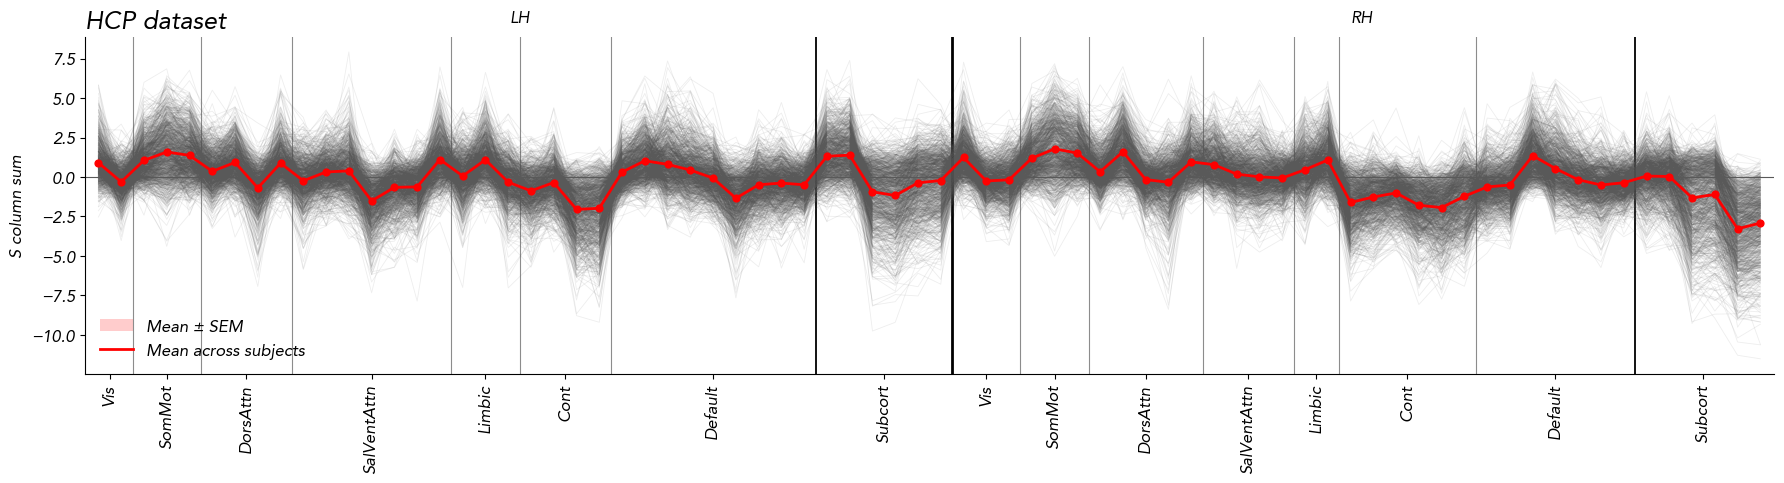

Shape originale: (1013, 112)
Shape finale: (1013, 74)

Ordine finale:
32 corticali LH + 6 sottocorticali LH + 30 corticali RH + 6 sottocorticali RH

Indici corticali originali 62, indicizzati da 1:
LH: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32]
RH: [33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56
 57 58 59 60 61 62]


In [246]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ============================================================
# INPUT
# ============================================================

# shape = (n_subjects, 112)
# prime 100 colonne: corticali Schaefer
# colonne 100:106: sottocorticali sinistre
# colonne 106:112: sottocorticali destre
values_all_112 = np.sum(S_s,1)
#values_all_112 = 
#np.asarray(values_all_112, dtype=float)

# Label delle 100 parcelle corticali
labels_100 = np.asarray(labels_100)

mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

network_order = [
    "LH_Vis",
    "LH_SomMot",
    "LH_DorsAttn",
    "LH_SalVentAttn",
    "LH_Limbic",
    "LH_Cont",
    "LH_Default",
    "RH_Vis",
    "RH_SomMot",
    "RH_DorsAttn",
    "RH_SalVentAttn",
    "RH_Limbic",
    "RH_Cont",
    "RH_Default"
]

network_display_names = {
    "LH_Vis": "Vis",
    "LH_SomMot": "SomMot",
    "LH_DorsAttn": "DorsAttn",
    "LH_SalVentAttn": "SalVentAttn",
    "LH_Limbic": "Limbic",
    "LH_Cont": "Cont",
    "LH_Default": "Default",
    "RH_Vis": "Vis",
    "RH_SomMot": "SomMot",
    "RH_DorsAttn": "DorsAttn",
    "RH_SalVentAttn": "SalVentAttn",
    "RH_Limbic": "Limbic",
    "RH_Cont": "Cont",
    "RH_Default": "Default"
}


# ============================================================
# FUNZIONI
# ============================================================

def extract_network(label):
    parts = str(label).split("_")

    if parts[0] in ("LH", "RH"):
        return "_".join(parts[:2])

    if len(parts) >= 3 and parts[1] in ("LH", "RH"):
        return "_".join(parts[1:3])

    raise ValueError(f"Formato label non riconosciuto: {label}")


def prepare_cortical_order(
    labels_100,
    mapping_100_to_62,
    network_order
):
    labels_100 = np.asarray(labels_100)
    mapping_100_to_62 = np.asarray(mapping_100_to_62)

    if len(labels_100) != 100:
        raise ValueError(
            f"labels_100 deve avere lunghezza 100, non {len(labels_100)}"
        )

    if len(mapping_100_to_62) != 100:
        raise ValueError(
            "mapping_100_to_62 deve avere lunghezza 100"
        )

    network_100 = np.array(
        [extract_network(label) for label in labels_100],
        dtype=object
    )

    network_62 = np.empty(62, dtype=object)
    purity_62 = np.full(62, np.nan)
    composition_62 = {}

    for parcel_62 in range(1, 63):

        idx_100 = np.where(
            mapping_100_to_62 == parcel_62
        )[0]

        if len(idx_100) == 0:
            raise ValueError(
                f"La parcella {parcel_62} non compare nel mapping"
            )

        counts = Counter(network_100[idx_100])
        dominant_network, dominant_count = counts.most_common(1)[0]

        network_62[parcel_62 - 1] = dominant_network
        purity_62[parcel_62 - 1] = (
            dominant_count / len(idx_100)
        )
        composition_62[parcel_62] = dict(counts)

    lh_networks = [
        network for network in network_order
        if network.startswith("LH_")
    ]

    rh_networks = [
        network for network in network_order
        if network.startswith("RH_")
    ]

    ordered_indices_lh = np.concatenate([
        np.where(network_62 == network)[0]
        for network in lh_networks
    ])

    ordered_indices_rh = np.concatenate([
        np.where(network_62 == network)[0]
        for network in rh_networks
    ])

    network_62_lh = network_62[ordered_indices_lh]
    network_62_rh = network_62[ordered_indices_rh]

    lh_sizes = np.array([
        np.sum(network_62_lh == network)
        for network in lh_networks
    ])

    rh_sizes = np.array([
        np.sum(network_62_rh == network)
        for network in rh_networks
    ])

    lh_present = lh_sizes > 0
    rh_present = rh_sizes > 0

    lh_networks_present = np.asarray(lh_networks)[lh_present]
    rh_networks_present = np.asarray(rh_networks)[rh_present]

    lh_sizes_present = lh_sizes[lh_present]
    rh_sizes_present = rh_sizes[rh_present]

    return {
        "network_62": network_62,
        "ordered_indices_lh": ordered_indices_lh,
        "ordered_indices_rh": ordered_indices_rh,
        "lh_networks_present": lh_networks_present,
        "rh_networks_present": rh_networks_present,
        "lh_sizes": lh_sizes_present,
        "rh_sizes": rh_sizes_present,
        "purity_62": purity_62,
        "composition_62": composition_62
    }


def aggregate_cortical_100_to_62(
    cortical_100,
    mapping_100_to_62,
    aggregation="mean"
):
    cortical_100 = np.asarray(cortical_100, dtype=float)

    if cortical_100.shape != (100,):
        raise ValueError(
            f"cortical_100 deve avere shape (100,), "
            f"trovata {cortical_100.shape}"
        )

    cortical_62 = np.full(62, np.nan)

    for parcel_62 in range(1, 63):

        idx_100 = np.where(
            mapping_100_to_62 == parcel_62
        )[0]

        current_values = cortical_100[idx_100]

        if aggregation == "mean":
            cortical_62[parcel_62 - 1] = np.nanmean(
                current_values
            )

        elif aggregation == "median":
            cortical_62[parcel_62 - 1] = np.nanmedian(
                current_values
            )

        elif aggregation == "sum":
            cortical_62[parcel_62 - 1] = np.nansum(
                current_values
            )

        else:
            raise ValueError(
                "aggregation deve essere 'mean', 'median' o 'sum'"
            )

    return cortical_62


def convert_subject_112_to_74(
    subject_vector_112,
    mapping_100_to_62,
    ordered_indices_lh,
    ordered_indices_rh,
    aggregation="mean"
):
    """
    Input:
        [100 corticali, 6 subcort LH, 6 subcort RH]

    Output:
        [corticali LH, 6 subcort LH,
         corticali RH, 6 subcort RH]
    """

    subject_vector_112 = np.asarray(
        subject_vector_112,
        dtype=float
    )

    if subject_vector_112.shape != (112,):
        raise ValueError(
            f"Il vettore deve avere shape (112,), "
            f"trovata {subject_vector_112.shape}"
        )

    cortical_100 = subject_vector_112[:100]
    subcortical_lh = subject_vector_112[100:106]
    subcortical_rh = subject_vector_112[106:112]

    cortical_62 = aggregate_cortical_100_to_62(
        cortical_100=cortical_100,
        mapping_100_to_62=mapping_100_to_62,
        aggregation=aggregation
    )

    cortical_lh = cortical_62[ordered_indices_lh]
    cortical_rh = cortical_62[ordered_indices_rh]

    subject_vector_74 = np.concatenate([
        cortical_lh,
        subcortical_lh,
        cortical_rh,
        subcortical_rh
    ])

    return subject_vector_74


def convert_all_subjects_112_to_74(
    values_all_112,
    mapping_100_to_62,
    ordered_indices_lh,
    ordered_indices_rh,
    aggregation="mean"
):
    values_all_112 = np.asarray(
        values_all_112,
        dtype=float
    )

    if values_all_112.ndim != 2:
        raise ValueError(
            "values_all_112 deve essere una matrice 2D"
        )

    if values_all_112.shape[1] != 112:
        raise ValueError(
            f"La seconda dimensione deve essere 112, "
            f"shape trovata: {values_all_112.shape}"
        )

    return np.array([
        convert_subject_112_to_74(
            subject_vector_112=subject_vector,
            mapping_100_to_62=mapping_100_to_62,
            ordered_indices_lh=ordered_indices_lh,
            ordered_indices_rh=ordered_indices_rh,
            aggregation=aggregation
        )
        for subject_vector in values_all_112
    ])


# ============================================================
# PREPARAZIONE E CONVERSIONE
# ============================================================

network_info = prepare_cortical_order(
    labels_100=labels_100,
    mapping_100_to_62=mapping_100_to_62,
    network_order=network_order
)

values_all_74 = convert_all_subjects_112_to_74(
    values_all_112=values_all_112,
    mapping_100_to_62=mapping_100_to_62,
    ordered_indices_lh=network_info["ordered_indices_lh"],
    ordered_indices_rh=network_info["ordered_indices_rh"],
    aggregation="mean"
)

# ============================================================
# STATISTICHE ACROSS SUBJECTS
# ============================================================

mean_across_subjects = np.nanmean(
    values_all_74,
    axis=0
)

std_across_subjects = np.nanstd(
    values_all_74,
    axis=0,
    ddof=1
)

n_valid_subjects = np.sum(
    np.isfinite(values_all_74),
    axis=0
)

sem_across_subjects = np.divide(
    std_across_subjects,
    np.sqrt(n_valid_subjects),
    out=np.full_like(std_across_subjects, np.nan),
    where=n_valid_subjects > 0
)

x = np.arange(74)

# ============================================================
# POSIZIONI DEI GRUPPI
# ============================================================

n_lh_cortical = len(network_info["ordered_indices_lh"])
n_rh_cortical = len(network_info["ordered_indices_rh"])

lh_cortical_start = 0
lh_subcort_start = n_lh_cortical
rh_cortical_start = n_lh_cortical + 6
rh_subcort_start = n_lh_cortical + 6 + n_rh_cortical

# Centri delle network corticali sinistre
lh_starts = np.r_[
    0,
    np.cumsum(network_info["lh_sizes"])[:-1]
]

lh_centers = (
    lh_starts + (network_info["lh_sizes"] - 1) / 2
)

# Centro delle sottocorticali sinistre
lh_subcort_center = lh_subcort_start + 2.5

# Centri delle network corticali destre
rh_starts_local = np.r_[
    0,
    np.cumsum(network_info["rh_sizes"])[:-1]
]

rh_centers = (
    rh_cortical_start
    + rh_starts_local
    + (network_info["rh_sizes"] - 1) / 2
)

# Centro delle sottocorticali destre
rh_subcort_center = rh_subcort_start + 2.5

all_centers = np.concatenate([
    lh_centers,
    [lh_subcort_center],
    rh_centers,
    [rh_subcort_center]
])

all_labels = (
    [
        network_display_names[n]
        for n in network_info["lh_networks_present"]
    ]
    + ["Subcort"]
    + [
        network_display_names[n]
        for n in network_info["rh_networks_present"]
    ]
    + ["Subcort"]
)

# Confini interni alle network corticali sinistre
lh_boundaries = (
    np.cumsum(network_info["lh_sizes"])[:-1] - 0.5
)

# Confini interni alle network corticali destre
rh_boundaries = (
    rh_cortical_start
    + np.cumsum(network_info["rh_sizes"])[:-1]
    - 0.5
)

# Separazioni principali
boundary_lh_cort_sub = n_lh_cortical - 0.5
boundary_lh_rh = n_lh_cortical + 6 - 0.5
boundary_rh_cort_sub = rh_subcort_start - 0.5

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(18, 5))

# Singoli soggetti
for subject_values in values_all_74:
    ax.plot(
        x,
        subject_values,
        linewidth=0.6,
        alpha=0.10,
        color="0.35",
        zorder=1
    )

# Mean ± SEM
ax.fill_between(
    x,
    mean_across_subjects - sem_across_subjects,
    mean_across_subjects + sem_across_subjects,
    alpha=0.20,
    color="red",
    linewidth=0,
    label="Mean ± SEM",
    zorder=2
)

# Media
ax.plot(
    x,
    mean_across_subjects,
    linewidth=2,
    color="red",
    label="Mean across subjects",
    zorder=3
)

ax.scatter(
    x,
    mean_across_subjects,
    s=24,
    color="red",
    zorder=4
)

# Zero
ax.axhline(
    0,
    color="0.35",
    linewidth=0.8,
    zorder=0
)

# Confini tra network
for boundary in np.r_[lh_boundaries, rh_boundaries]:
    ax.axvline(
        boundary,
        color="0.55",
        linewidth=0.8,
        zorder=0
    )

# Confini tra corticali e sottocorticali
ax.axvline(
    boundary_lh_cort_sub,
    color="black",
    linewidth=1.3,
    zorder=0
)

ax.axvline(
    boundary_rh_cort_sub,
    color="black",
    linewidth=1.3,
    zorder=0
)

# Separazione principale LH / RH
ax.axvline(
    boundary_lh_rh,
    color="black",
    linewidth=2,
    zorder=0
)

# Etichette asse x
ax.set_xticks(all_centers)
ax.set_xticklabels(
    all_labels,
    rotation=90
)

# Etichette superiori LH e RH
lh_center = (
    0 + (n_lh_cortical + 6 - 1)
) / 2

rh_center = (
    rh_cortical_start + 73
) / 2

ax.text(
    lh_center,
    1.03,
    "LH",
    ha="center",
    va="bottom",
    transform=ax.get_xaxis_transform(),
    fontsize=12
)

ax.text(
    rh_center,
    1.03,
    "RH",
    ha="center",
    va="bottom",
    transform=ax.get_xaxis_transform(),
    fontsize=12
)

ax.set_xlim(-0.6, 73.6)
ax.set_ylabel("S column sum")
ax.set_xlabel("")
ax.set_title("HCP dataset", loc="left", fontsize=18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    loc="best"
)

plt.tight_layout()
plt.show()

# ============================================================
# OUTPUT
# ============================================================

print("Shape originale:", values_all_112.shape)
print("Shape finale:", values_all_74.shape)

print("\nOrdine finale:")
print(
    f"{n_lh_cortical} corticali LH + "
    f"6 sottocorticali LH + "
    f"{n_rh_cortical} corticali RH + "
    f"6 sottocorticali RH"
)

print("\nIndici corticali originali 62, indicizzati da 1:")

print(
    "LH:",
    network_info["ordered_indices_lh"] + 1
)

print(
    "RH:",
    network_info["ordered_indices_rh"] + 1
)

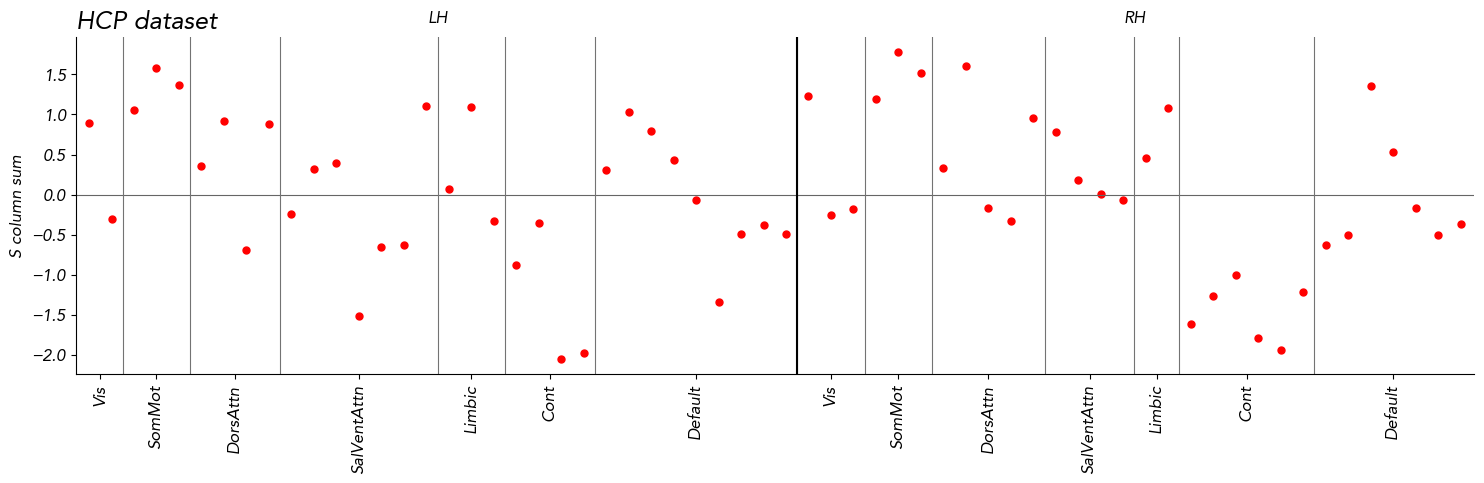

Shape originale: (100,)
Shape aggregata: (62,)
Shape visualizzata: (62,)
Indici originali delle 62 parcelle nel nuovo ordine:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61]

Parcelle 62 non completamente contenute in una sola network:


In [235]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ============================================================
# INPUT
# ============================================================

# Vettore di lunghezza 100
values_100 = np.asarray(source_sink_S[:100], dtype=float)

# Errori associati alle 100 parcelle.
# Se non hai errori, metti:
# errors_100 = None
errors_100 = None
errors_100 = np.asarray(errors_100, dtype=float) if errors_100 is not None else None

# Label Schaefer-100:
# ['LH_Vis_1', ..., 'RH_Default_...']
labels_100 = np.asarray(labels_100)

# mapping[i] = indice della parcella 62 che contiene la parcella 100 i
# Indicizzazione da 1 a 62
mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

network_order = [
    "LH_Vis",
    "LH_SomMot",
    "LH_DorsAttn",
    "LH_SalVentAttn",
    "LH_Limbic",
    "LH_Cont",
    "LH_Default",
    "RH_Vis",
    "RH_SomMot",
    "RH_DorsAttn",
    "RH_SalVentAttn",
    "RH_Limbic",
    "RH_Cont",
    "RH_Default"
]

network_display_names = {
    "LH_Vis": "Vis",
    "LH_SomMot": "SomMot",
    "LH_DorsAttn": "DorsAttn",
    "LH_SalVentAttn": "SalVentAttn",
    "LH_Limbic": "Limbic",
    "LH_Cont": "Cont",
    "LH_Default": "Default",
    "RH_Vis": "Vis",
    "RH_SomMot": "SomMot",
    "RH_DorsAttn": "DorsAttn",
    "RH_SalVentAttn": "SalVentAttn",
    "RH_Limbic": "Limbic",
    "RH_Cont": "Cont",
    "RH_Default": "Default"
}

# ============================================================
# CONTROLLI
# ============================================================

if values_100.ndim != 1 or len(values_100) != 100:
    raise ValueError(
        f"values_100 deve avere shape (100,), trovata {values_100.shape}"
    )

if errors_100 is not None:
    if errors_100.ndim != 1 or len(errors_100) != 100:
        raise ValueError(
            f"errors_100 deve avere shape (100,), trovata {errors_100.shape}"
        )

if len(labels_100) != 100:
    raise ValueError("labels_100 deve contenere 100 label")

if len(mapping_100_to_62) != 100:
    raise ValueError("mapping_100_to_62 deve avere lunghezza 100")

if set(np.unique(mapping_100_to_62)) != set(range(1, 63)):
    raise ValueError("Il mapping deve contenere tutti gli indici da 1 a 62")

# ============================================================
# ESTRAZIONE NETWORK DALLE LABEL SCHAEFER-100
# ============================================================

def extract_network(label):
    parts = str(label).split("_")

    # Esempio: LH_Vis_1
    if parts[0] in ("LH", "RH"):
        return "_".join(parts[:2])

    # Esempio: 7Networks_LH_Vis_1
    if len(parts) >= 3 and parts[1] in ("LH", "RH"):
        return "_".join(parts[1:3])

    raise ValueError(f"Formato label non riconosciuto: {label}")


network_100 = np.array(
    [extract_network(label) for label in labels_100],
    dtype=object
)

# ============================================================
# AGGREGAZIONE 100 -> 62
# ============================================================

values_62 = np.full(62, np.nan)
errors_62 = np.full(62, np.nan) if errors_100 is not None else None
network_62 = np.empty(62, dtype=object)
purity_62 = np.full(62, np.nan)

for parcel_62 in range(1, 63):

    idx_100 = np.where(mapping_100_to_62 == parcel_62)[0]

    # Media delle parcelle 100 contenute nella parcella 62
    values_62[parcel_62 - 1] = np.nanmean(values_100[idx_100])

    # Propagazione dell'errore della media:
    # SEM(mean) = sqrt(sum(SEM_i^2)) / n
    if errors_100 is not None:
        valid = np.isfinite(errors_100[idx_100])
        n_valid = np.sum(valid)

        if n_valid > 0:
            errors_62[parcel_62 - 1] = (
                np.sqrt(np.sum(errors_100[idx_100][valid] ** 2))
                / n_valid
            )

    # Network della parcella 62:
    # maggioranza delle network delle parcelle 100 contenute
    counts = Counter(network_100[idx_100])
    dominant_network, dominant_count = counts.most_common(1)[0]

    network_62[parcel_62 - 1] = dominant_network
    purity_62[parcel_62 - 1] = dominant_count / len(idx_100)

# ============================================================
# ORDINAMENTO DELLE 62 PARCELLE PER NETWORK
# ============================================================

ordered_indices_62 = np.concatenate([
    np.where(network_62 == network)[0]
    for network in network_order
])

values_plot = values_62[ordered_indices_62]
errors_plot = (
    errors_62[ordered_indices_62]
    if errors_62 is not None
    else None
)
network_plot = network_62[ordered_indices_62]

x = np.arange(len(values_plot))

# Numero di parcelle 62 per ciascuna network
network_sizes = np.array([
    np.sum(network_plot == network)
    for network in network_order
])

# Rimuove eventuali network vuote
present = network_sizes > 0
present_networks = np.array(network_order)[present]
present_sizes = network_sizes[present]

# Confini e centri delle network
boundaries = np.cumsum(present_sizes)[:-1] - 0.5
starts = np.r_[0, np.cumsum(present_sizes)[:-1]]
centers = starts + (present_sizes - 1) / 2

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

if errors_plot is not None:
    ax.errorbar(
        x,
        values_plot,
        yerr=errors_plot,
        fmt="o",
        markersize=5,
        capsize=0,
        linewidth=1,
        color="red",
        ecolor="red"
    )
else:
    ax.plot(
        x,
        values_plot,
        "o",
        markersize=5,
        color="red"
    )

# Linea orizzontale a zero
ax.axhline(0, color="0.4", linewidth=0.8)

# Linee verticali tra le network
for boundary in boundaries:
    ax.axvline(
        boundary,
        color="0.45",
        linewidth=0.8
    )

# Linea più marcata tra emisfero sinistro e destro
n_left = sum(
    np.sum(network_plot == network)
    for network in network_order
    if network.startswith("LH_")
)

if 0 < n_left < len(values_plot):
    ax.axvline(
        n_left - 0.5,
        color="black",
        linewidth=1.5
    )

# Label delle network sotto l'asse x
ax.set_xticks(centers)
ax.set_xticklabels(
    [network_display_names[n] for n in present_networks],
    rotation=90
)

# Label LH e RH sopra il grafico
left_center = (n_left - 1) / 2
right_center = n_left + (len(values_plot) - n_left - 1) / 2

ax.text(
    left_center,
    1.03,
    "LH",
    ha="center",
    va="bottom",
    transform=ax.get_xaxis_transform(),
    fontsize=12
)

ax.text(
    right_center,
    1.03,
    "RH",
    ha="center",
    va="bottom",
    transform=ax.get_xaxis_transform(),
    fontsize=12
)

ax.set_xlim(-0.6, len(values_plot) - 0.4)
ax.set_ylabel("S column sum")
ax.set_xlabel("")
ax.set_title("HCP dataset", loc="left", fontsize=18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# ============================================================
# OUTPUT UTILI
# ============================================================

print("Shape originale:", values_100.shape)
print("Shape aggregata:", values_62.shape)
print("Shape visualizzata:", values_plot.shape)
print("Indici originali delle 62 parcelle nel nuovo ordine:")
print(ordered_indices_62)

# Eventuali parcelle 62 che includono più network Schaefer
mixed = np.where(purity_62 < 1)[0]

print("\nParcelle 62 non completamente contenute in una sola network:")
for idx in mixed:
    idx_100 = np.where(mapping_100_to_62 == idx + 1)[0]
    print(
        f"Parcella 62 n. {idx + 1:2d}: "
        f"network assegnata = {network_62[idx]:15s}, "
        f"purity = {purity_62[idx]:.2f}, "
        f"composizione = {dict(Counter(network_100[idx_100]))}"
    )

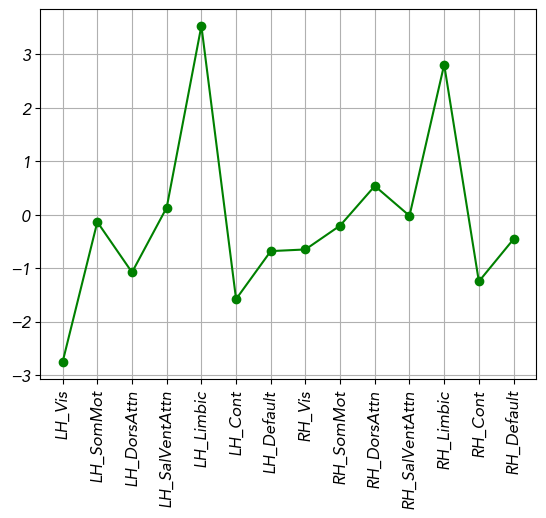

In [229]:
import numpy as np

# ============================================================
# INPUT
# ============================================================

# Vettore di lunghezza 62
values_62 = np.asarray(source_sink_dcm)

# Label delle 100 parcelle, ad esempio:
# ['LH_Vis_1', 'LH_Vis_2', ..., 'RH_Default_...']
labels = np.asarray(labels100)

# Per ogni parcella Schaefer-100 indica la corrispondente
# parcella nella parcellazione a 62 regioni
mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

# ============================================================
# CONTROLLI
# ============================================================

if values_62.ndim != 1 or len(values_62) != 62:
    raise ValueError(
        f"values_62 deve essere un vettore di lunghezza 62; "
        f"shape trovata: {values_62.shape}"
    )

if len(labels) != 100:
    raise ValueError(
        f"labels deve contenere 100 elementi; trovati: {len(labels)}"
    )

if len(mapping_100_to_62) != 100:
    raise ValueError(
        f"Il mapping deve contenere 100 elementi; "
        f"trovati: {len(mapping_100_to_62)}"
    )

# ============================================================
# ESPANSIONE DEL VETTORE 62 -> 100
# ============================================================

# Il mapping usa indici da 1 a 62, mentre Python usa indici da 0 a 61
values_100 = values_62[mapping_100_to_62 - 1]

# ============================================================
# ESTRAZIONE DELLE 14 NETWORK
# ============================================================

network_order = [
    "LH_Vis",
    "LH_SomMot",
    "LH_DorsAttn",
    "LH_SalVentAttn",
    "LH_Limbic",
    "LH_Cont",
    "LH_Default",
    "RH_Vis",
    "RH_SomMot",
    "RH_DorsAttn",
    "RH_SalVentAttn",
    "RH_Limbic",
    "RH_Cont",
    "RH_Default"
]

# Funziona sia con:
# LH_Vis_1
# sia con:
# 7Networks_LH_Vis_1
def extract_network(label):
    parts = str(label).split("_")

    if parts[0] in ("LH", "RH"):
        return "_".join(parts[:2])

    if len(parts) >= 3 and parts[1] in ("LH", "RH"):
        return "_".join(parts[1:3])

    raise ValueError(f"Formato della label non riconosciuto: {label}")


network_labels = np.array([
    extract_network(label)
    for label in labels
])

# Indici Schaefer-100 appartenenti a ogni network
indices_by_network = {
    network: np.where(network_labels == network)[0]
    for network in network_order
}

missing_networks = [
    network
    for network in network_order
    if len(indices_by_network[network]) == 0
]

if missing_networks:
    raise ValueError(
        f"Network non trovate nelle labels: {missing_networks}\n"
        f"Network rilevate: {np.unique(network_labels)}"
    )

# ============================================================
# ORGANIZZAZIONE PER NETWORK
# ============================================================

# Valori espansi, separati nelle 14 network
values_by_network = {
    network: values_100[indices_by_network[network]]
    for network in network_order
}

# Label separate nelle 14 network
labels_by_network = {
    network: labels[indices_by_network[network]]
    for network in network_order
}

# Indici originali delle 100 parcelle, separati per network
parcel_indices_by_network = {
    network: indices_by_network[network]
    for network in network_order
}

# Indici delle parcelle a 62 associate a ogni network
# Restano indicizzati da 1 a 62
mapping_by_network = {
    network: mapping_100_to_62[indices_by_network[network]]
    for network in network_order
}

# Riordinamento complessivo delle 100 parcelle secondo le 14 network
ordered_indices = np.concatenate([
    indices_by_network[network]
    for network in network_order
])

values_100_ordered = values_100[ordered_indices]
labels_ordered = labels[ordered_indices]
network_labels_ordered = network_labels[ordered_indices]

# Media sulle parcelle Schaefer-100 di ciascuna network
network_means = np.array([
    np.nanmean(values_by_network[network])
    for network in network_order
])

# ============================================================
# RIEPILOGO
# ============================================================

# = 
plt.plot(network_means, '-o',color='g')


plt.xticks(np.arange(0,14,1), labels =_, rotation =90);
plt.grid()

LH_Vis             | n parcelle 62 =  2 | indici = [1 2] | media = -0.6851
LH_SomMot          | n parcelle 62 =  3 | indici = [3 4 5] | media = 0.1782
LH_DorsAttn        | n parcelle 62 =  4 | indici = [6 7 8 9] | media = -0.9961
LH_SalVentAttn     | n parcelle 62 =  7 | indici = [10 11 12 13 14 15 16] | media = 0.1316
LH_Limbic          | n parcelle 62 =  3 | indici = [17 18 19] | media = 3.5303
LH_Cont            | n parcelle 62 =  4 | indici = [20 21 22 23] | media = -1.5815
LH_Default         | n parcelle 62 =  9 | indici = [24 25 26 27 28 29 30 31 32] | media = -0.2505
RH_Vis             | n parcelle 62 =  3 | indici = [33 34 35] | media = 0.0927
RH_SomMot          | n parcelle 62 =  3 | indici = [36 37 38] | media = -0.0905
RH_DorsAttn        | n parcelle 62 =  5 | indici = [39 40 41 42 43] | media = 0.6727
RH_SalVentAttn     | n parcelle 62 =  4 | indici = [44 45 46 47] | media = 0.0107
RH_Limbic          | n parcelle 62 =  2 | indici = [48 49] | media = 2.8052
RH_Cont          

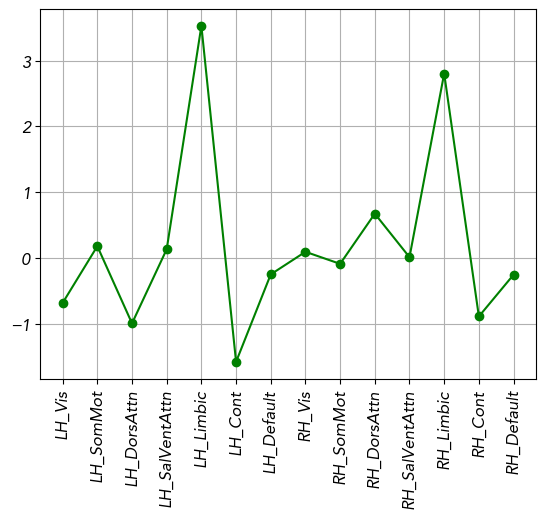

In [231]:
import numpy as np
from collections import Counter

# ============================================================
# INPUT
# ============================================================

# Vettore originale di lunghezza 62
values_62 = np.asarray(source_sink_dcm)

# Label Schaefer-100, per esempio:
# ['LH_Vis_1', 'LH_Vis_2', ..., 'RH_Default_...']
labels_100 = np.asarray(labels100)

# mapping[i] = parcella 62 a cui appartiene la parcella Schaefer-100 i
# Indicizzazione originale: 1,...,62
mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

network_order = [
    "LH_Vis",
    "LH_SomMot",
    "LH_DorsAttn",
    "LH_SalVentAttn",
    "LH_Limbic",
    "LH_Cont",
    "LH_Default",
    "RH_Vis",
    "RH_SomMot",
    "RH_DorsAttn",
    "RH_SalVentAttn",
    "RH_Limbic",
    "RH_Cont",
    "RH_Default"
]

# ============================================================
# CONTROLLI
# ============================================================

if values_62.ndim != 1 or len(values_62) != 62:
    raise ValueError(
        f"values_62 deve avere lunghezza 62; shape trovata: {values_62.shape}"
    )

if len(labels_100) != 100:
    raise ValueError(
        f"labels_100 deve avere lunghezza 100; trovati {len(labels_100)} elementi"
    )

if len(mapping_100_to_62) != 100:
    raise ValueError("mapping_100_to_62 deve avere lunghezza 100")

# ============================================================
# NETWORK DELLE PARCELLE SCHAEFER-100
# ============================================================

def extract_network(label):
    parts = str(label).split("_")

    # Label tipo LH_Vis_1
    if parts[0] in ("LH", "RH"):
        return "_".join(parts[:2])

    # Label tipo 7Networks_LH_Vis_1
    if len(parts) >= 3 and parts[1] in ("LH", "RH"):
        return "_".join(parts[1:3])

    raise ValueError(f"Formato label non riconosciuto: {label}")


network_100 = np.array([
    extract_network(label)
    for label in labels_100
])

# ============================================================
# ASSEGNAZIONE DELLE 62 PARCELLE ALLE NETWORK
# ============================================================

network_62 = np.empty(62, dtype=object)
network_composition_62 = {}
network_purity_62 = np.zeros(62)

for parcel_62 in range(1, 63):

    # Parcelle Schaefer-100 confluite nella parcella corrente
    idx_100 = np.where(mapping_100_to_62 == parcel_62)[0]

    # Network presenti dentro la parcella aggregata
    contained_networks = network_100[idx_100]

    counts = Counter(contained_networks)

    # Network maggioritaria
    dominant_network, dominant_count = counts.most_common(1)[0]

    network_62[parcel_62 - 1] = dominant_network
    network_composition_62[parcel_62] = dict(counts)

    # Percentuale delle Schaefer-100 appartenenti alla network maggioritaria
    network_purity_62[parcel_62 - 1] = dominant_count / len(idx_100)

# ============================================================
# ORGANIZZAZIONE DEL VETTORE 62 NELLE 14 NETWORK
# ============================================================

indices_62_by_network = {
    network: np.where(network_62 == network)[0]
    for network in network_order
}

values_62_by_network = {
    network: values_62[indices_62_by_network[network]]
    for network in network_order
}

# Riordina i 62 elementi, senza duplicarne nessuno
ordered_indices_62 = np.concatenate([
    indices_62_by_network[network]
    for network in network_order
])

values_62_ordered = values_62[ordered_indices_62]
network_62_ordered = network_62[ordered_indices_62]

# Media: ogni parcella 62 conta esattamente una volta
network_means_62 = np.array([
    np.nanmean(values_62_by_network[network])
    if len(values_62_by_network[network]) > 0
    else np.nan
    for network in network_order
])

# ============================================================
# RIEPILOGO
# ============================================================

for network, mean_value in zip(network_order, network_means_62):
    idx = indices_62_by_network[network]

    print(
        f"{network:18s} | "
        f"n parcelle 62 = {len(idx):2d} | "
        f"indici = {idx + 1} | "
        f"media = {mean_value:.4f}"
    )

print("\nControllo:")
print("Numero totale di parcelle:", sum(
    len(idx) for idx in indices_62_by_network.values()
))
print("Shape vettore ordinato:", values_62_ordered.shape)

# Parcelle aggregate che contengono più di una network
mixed_parcels = np.where(network_purity_62 < 1)[0]

print("\nParcelle 62 contenenti Schaefer-100 di network diverse:")
for idx in mixed_parcels:
    print(
        f"Parcella {idx + 1:2d} | "
        f"assegnata a {network_62[idx]:15s} | "
        f"composizione = {network_composition_62[idx + 1]} | "
        f"purity = {network_purity_62[idx]:.2f}"
    )



# ============================================================

# = 
plt.plot(network_means_62, '-o',color='g')


plt.xticks(np.arange(0,14,1), labels =_, rotation =90);
plt.grid()

In [135]:

S_s =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], False)
    S_s.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s = np.asarray(S_s)
source_sink_S = np.sum(np.mean(S_s,0),0)
plt.hist(source_sink_S)

(array([ 2.,  0.,  7.,  9.,  9., 21., 17., 16., 23.,  8.]),
 array([-3.27736046, -2.75819606, -2.23903167, -1.71986727, -1.20070288,
        -0.68153848, -0.16237409,  0.35679031,  0.8759547 ,  1.3951191 ,
         1.91428349]),
 <BarContainer object of 10 artists>)

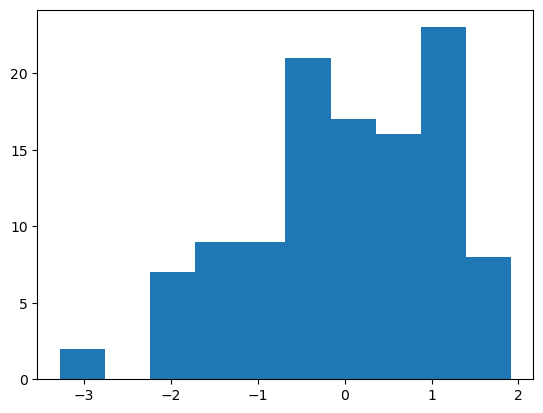

In [100]:
S_s =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], False)
    S_s.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s = np.asarray(S_s)
source_sink_S = np.sum(np.mean(S_s,0),0)
plt.hist(source_sink_S)

In [66]:
/home/benedetta/Scripts/Insight_project/Notebook figure'

'/home/benedetta/Scripts/Insight_project/Notebook figure'

In [67]:
# ---------------------------
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S[r]

img_J = nib.Nifti1Image(data_J, affine)
s#ource_sink_S
nib.save(img_J, 'nifti_S.nii');

### comparisons

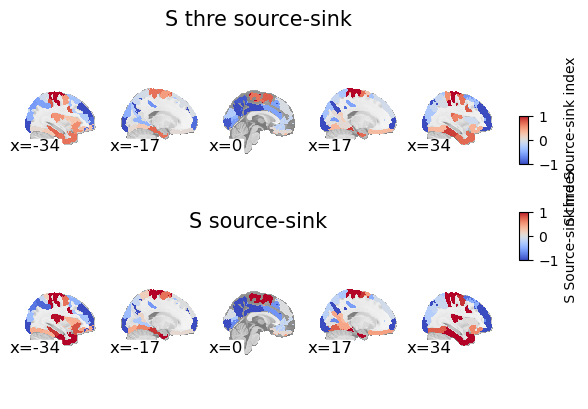

In [38]:
# Source-sink index map
import matplotlib.pyplot as plt
import nibabel as nib
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import nilearn.plotting as plotting

I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)
fig.suptitle('All links considered')
data = I1.get_fdata()
affine = I1.affine

# ---------------------------
# Source-sink index map
# ---------------------------
data_J = np.zeros_like(data)
# ---------------------------
fig,ax = plt.subplots(2,1)
data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S_thre[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 1

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[0],
    vmin=-numero,
    vmax=numero
)

ax[0].set_title(
    "S thre source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.6, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label='S thre Source-sink index'
)

data_J = np.zeros_like(data)

for r in range(100):
    data_J[data == r + 1] = source_sink_S[r]

img_J = nib.Nifti1Image(data_J, affine)

numero = 1

display_ssi = plotting.plot_stat_map(
    img_J,
    cmap='coolwarm',
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax[1],
    vmin=-numero,
    vmax=numero
)

ax[1].set_title(
    "S source-sink",
    fontsize=15,
    pad=1
)

norm = Normalize(vmin=-numero, vmax=numero)
sm = ScalarMappable(norm=norm, cmap='coolwarm')
sm.set_array([])

cax_ssi = fig.add_axes([0.92, 0.4, 0.015, 0.10])

cbar_ssi = fig.colorbar(
    sm,
    cax=cax_ssi,
    label=' S Source-sink index'
)

In [ ]:
source_sink_S = np.nansum(np.nanmean(S_s,0),0)


In [36]:
S_s =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], False)
    S_s.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s = np.asarray(S_s)
source_sink_S = np.nansum(np.nanmean(S_s,0),0)

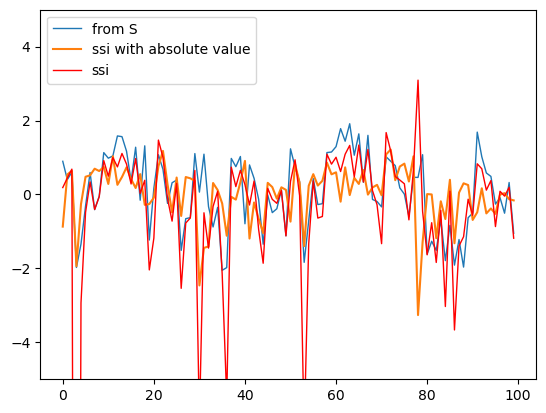

In [56]:
plt.plot(source_sink_S[:100], label='from S',lw = 1)
plt.plot(ssi_mean[:100]*30, label='ssi with absolute value')
plt.plot(ssi_mean_noabs[:100]*20, color='red', label='ssi',lw=1)
plt.ylim(-5,5)
plt.legend();


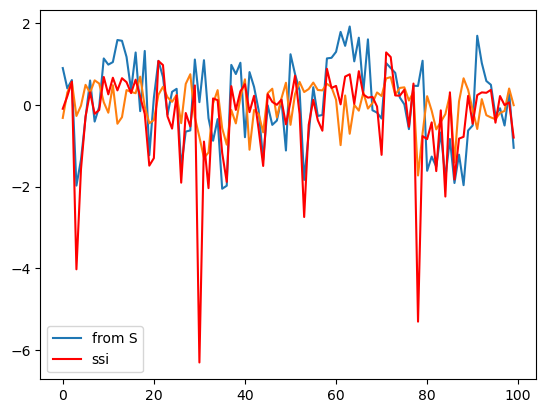

In [44]:
plt.plot(source_sink_S[:100], label='from S')
plt.plot(ssi_mean__thres[:100]*20)
plt.plot(ssi_mean__thres_noabs[:100]*20, color='red', label='ssi',)

plt.legend();


In [23]:
S.shape, significant_mask.shape

((112, 112), (100, 100))

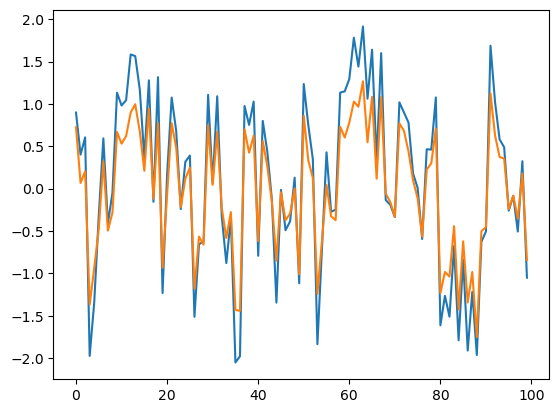

In [28]:
plt.plot(source_sink_S[:100])
plt.plot(source_sink_S_thre);

In [24]:
S_s=[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], False)
    S_s.append(S[:100,:100]*significant_mask)
S_s = np.asarray(S_s)
source_sink_S_thre = np.nansum(np.nanmean(S_s,0),0)

In [ ]:
source_sink_S = np.nansum(np.nanmean(S_s,0),0)


In [106]:
C = dediag(np.mean(JS,0))[:100,:100].T

in_strength  = np.sum(np.abs(C), axis=1)
out_strength = np.sum(np.abs(C), axis=0)

_ssi_mean = (out_strength - in_strength) / \
                  (out_strength + in_strength + 1e-12)


in_strength  = np.sum((C), axis=1)
out_strength = np.sum((C), axis=0)

_ssi_mean_No_abs =  (out_strength - in_strength) / \
                  (out_strength + in_strength + 1e-12)


_source_sink_S = np.sum(np.mean(S_s,0),0)[:100]

In [142]:
S_s_abs =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i], True)
    S_s_abs.append(S)
   # print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s_abs = np.asarray(S_s_abs)
source_sink_S_abs = np.nansum(np.nanmean(S_s_abs,0),0)

In [136]:
source_sink_S_abs

np.float64(6.661338147750939e-16)

/tmp/ipykernel_61739/2339836556.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(-50.0, 50.0)

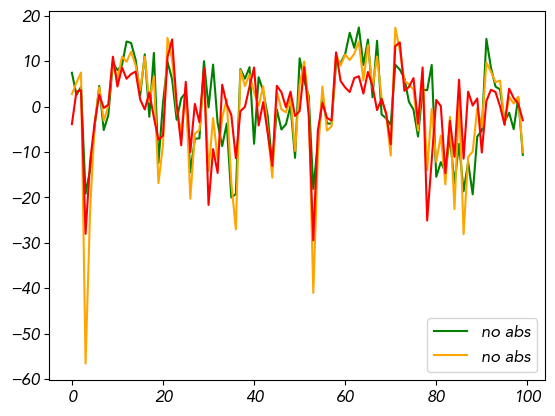

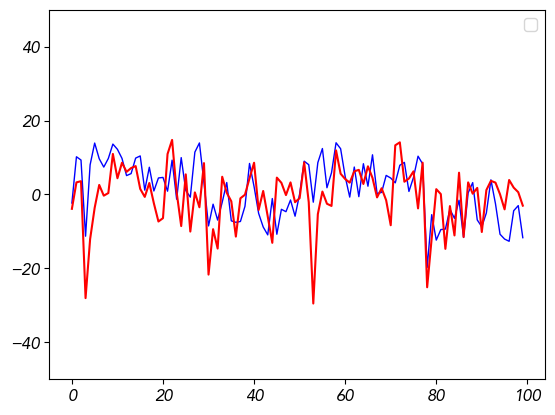

In [157]:
plt.plot(source_sink_S,color='green', label ='no abs')
plt.plot(_ssi_mean_No_abs*200, color='orange', label ='no abs')
#plt.plot(source_sink_S_abs[:100],color='blue',lw=1)
plt.plot(_ssi_mean*250, color='red')

plt.legend()
plt.figure()
plt.plot(source_sink_S_abs[:100],color='blue',lw=1)
plt.plot(_ssi_mean*250, color='red')
#plt.plot(ssi_mean*20)
#
plt.legend()
plt.ylim(-50,50)

(-5.0, 5.0)

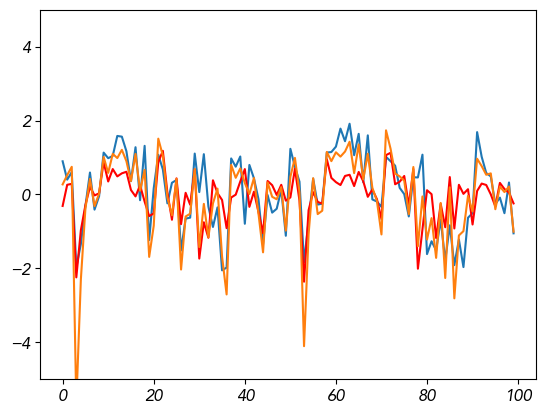

In [110]:
plt.plot(_source_sink_S,)
plt.plot(_ssi_mean*20, color='red')
#plt.plot(ssi_mean*20)
#
plt.plot(_ssi_mean_No_abs*20)
plt.ylim(-5,5)

In [90]:
stats.spearmanr(ssi_mean__thres, ssi_mean)

SignificanceResult(statistic=np.float64(0.7688688868886887), pvalue=np.float64(9.606409275845353e-21))

In [89]:
stats.spearmanr(ssi_mean_No_abs_thres, ssi_mean_No_abs)


SignificanceResult(statistic=np.float64(0.8778877887788777), pvalue=np.float64(4.1831662127099226e-33))

In [69]:
stats.spearmanr(source_sink_S, ssi_mean)

SignificanceResult(statistic=np.float64(0.28111611161116107), pvalue=np.float64(0.004608625547355989))

In [65]:
stats.spearmanr(coords_df['z'], ssi_mean_No_abs)

SignificanceResult(statistic=np.float64(0.07657965796579656), pvalue=np.float64(0.44888115992605004))

In [66]:
stats.spearmanr(coords_df['z'], ssi_mean)


SignificanceResult(statistic=np.float64(0.34527452745274523), pvalue=np.float64(0.00043451609912508967))

In [ ]:
def asym_norm(a):
    #a = dediag(a)
    return np.sum(np.abs(a - a.T))/np.sum(np.abs(a))/2, np.linalg.norm(a-a.T, ord='fro')/np.linalg.norm(a, ord='fro')/2
S_s =[]
for i in range(len(fc_1)):
    S =antisymmetric_differential_cross_covariance(JS[i].T, fc_1[i])
    S_s.append(S)
    print(asym_norm(dediag(S@np.linalg.inv(fc_1[i]))))
S_s = np.asarray(S_s)

In [212]:
JS[:1][0].shape

(112, 112)

In [224]:
import numpy as np

commutator = JS[:1][0] @ fc_1[:1][0] - fc_1[:1][0] @JS[:1][0]
J = JS[:1][0]
Q0 =fc_1[:1][0]

comm_norm = np.linalg.norm(
    commutator,
    ord="fro"
)

relative_comm = (
    comm_norm
    / (
        np.linalg.norm(J @ Q0, ord="fro")
        + np.linalg.norm(Q0 @ J, ord="fro")
    )
)

print("Commutator norm:", comm_norm)
print("Relative commutator:", relative_comm)
Q0 = fc_1[0][:100,:100]
J = m.Sigma
commutator_T = Q0 @ J.T - J.T @ Q0

relative_comm_T = (
    np.linalg.norm(commutator_T, ord="fro")
    / (
        np.linalg.norm(Q0 @ J.T, ord="fro")
        + np.linalg.norm(J.T @ Q0, ord="fro")
    )
)

print("Relative commutator Q0, J.T:", relative_comm_T)

Commutator norm: 10.309680726278996
Relative commutator: 0.37213367835443834
Relative commutator Q0, J.T: 0.08322354230562932


In [38]:
np.corrcoef(ssi_mean, ssi_mean_abs)

array([[1., 1.],
       [1., 1.]])

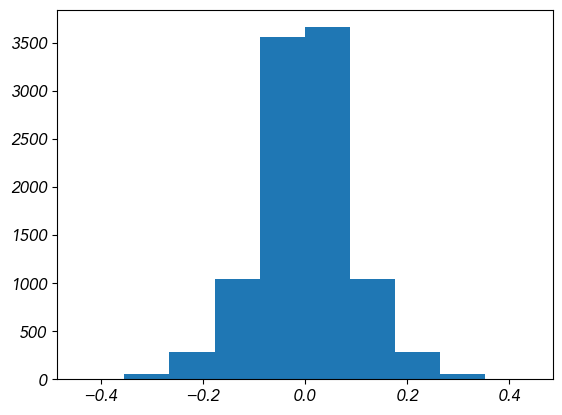

In [223]:
plt.hist((m.Sigma@fc_1[0][:100,:100]-(m.Sigma@fc_1[0][:100,:100]).T).flatten());

In [214]:
print("J shape:", np.shape(J))
print("Q0 shape:", np.shape(Q0))
print("J @ Q0 shape:", np.shape(J @ Q0))
print("Q0 @ J shape:", np.shape(Q0 @ J))

J shape: (112,)
Q0 shape: (112, 112)
J @ Q0 shape: (112,)
Q0 @ J shape: (112,)


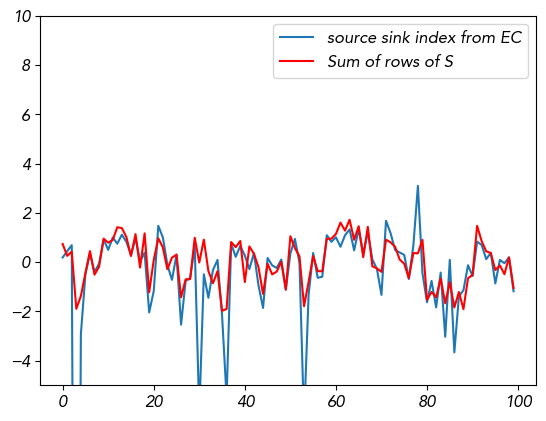

In [201]:
plt.plot(ssi_mean*20, label='source sink index from EC')
plt.plot(np.sum(np.mean(S_s[:,:100,:100],0),0), 'r-', label='Sum of rows of S');
plt.ylim(-5,10)
plt.legend();

In [110]:
#stats.pearsonr(ssi_mean,my_grad)


In [44]:
from scipy import stats
my_grad = np.load('../numpy files/myelin_sh100.npy')
stats.pearsonr(ssi_mean,my_grad)


PearsonRResult(statistic=np.float64(0.36157067407083937), pvalue=np.float64(0.00021892343644278942))

In [43]:
stats.pearsonr(coords_df['z'],ssi_mean)


PearsonRResult(statistic=np.float64(0.3001840122095536), pvalue=np.float64(0.002410101467714261))

In [49]:
stats.pearsonr(coords_df['z'],ssi_mean)

PearsonRResult(statistic=np.float64(0.3001840122095536), pvalue=np.float64(0.002410101467714261))

In [139]:
stats.pearsonr(my_grad,ssi_mean)

PearsonRResult(statistic=np.float64(0.36157067407083937), pvalue=np.float64(0.00021892343644278942))

In [196]:
source_sink_S = np.sum(np.mean(S_s[:,:100,:100],0),0)

In [45]:
from scipy import stats
stats.pearsonr(my_grad,source_sink_S)


PearsonRResult(statistic=np.float64(0.26496942700224524), pvalue=np.float64(0.007717651017660348))

In [226]:
stats.pearsonr(my_grad,source_sink_S)


PearsonRResult(statistic=np.float64(0.26496942700224524), pvalue=np.float64(0.007717651017660348))

In [50]:
stats.pearsonr(first_grad,source_sink_S)

PearsonRResult(statistic=np.float64(-0.25286054037076344), pvalue=np.float64(0.011142258487614428))

In [137]:
stats.pearsonr(first_grad,ssi_mean)

PearsonRResult(statistic=np.float64(-0.3385302802098624), pvalue=np.float64(0.0005709558919608994))

In [113]:
from scipy import stats
stats.spearmanr(coords_df['z'],ssi_norm_glob)

SignificanceResult(statistic=np.float64(0.209036903690369), pvalue=np.float64(0.03686953831938536))

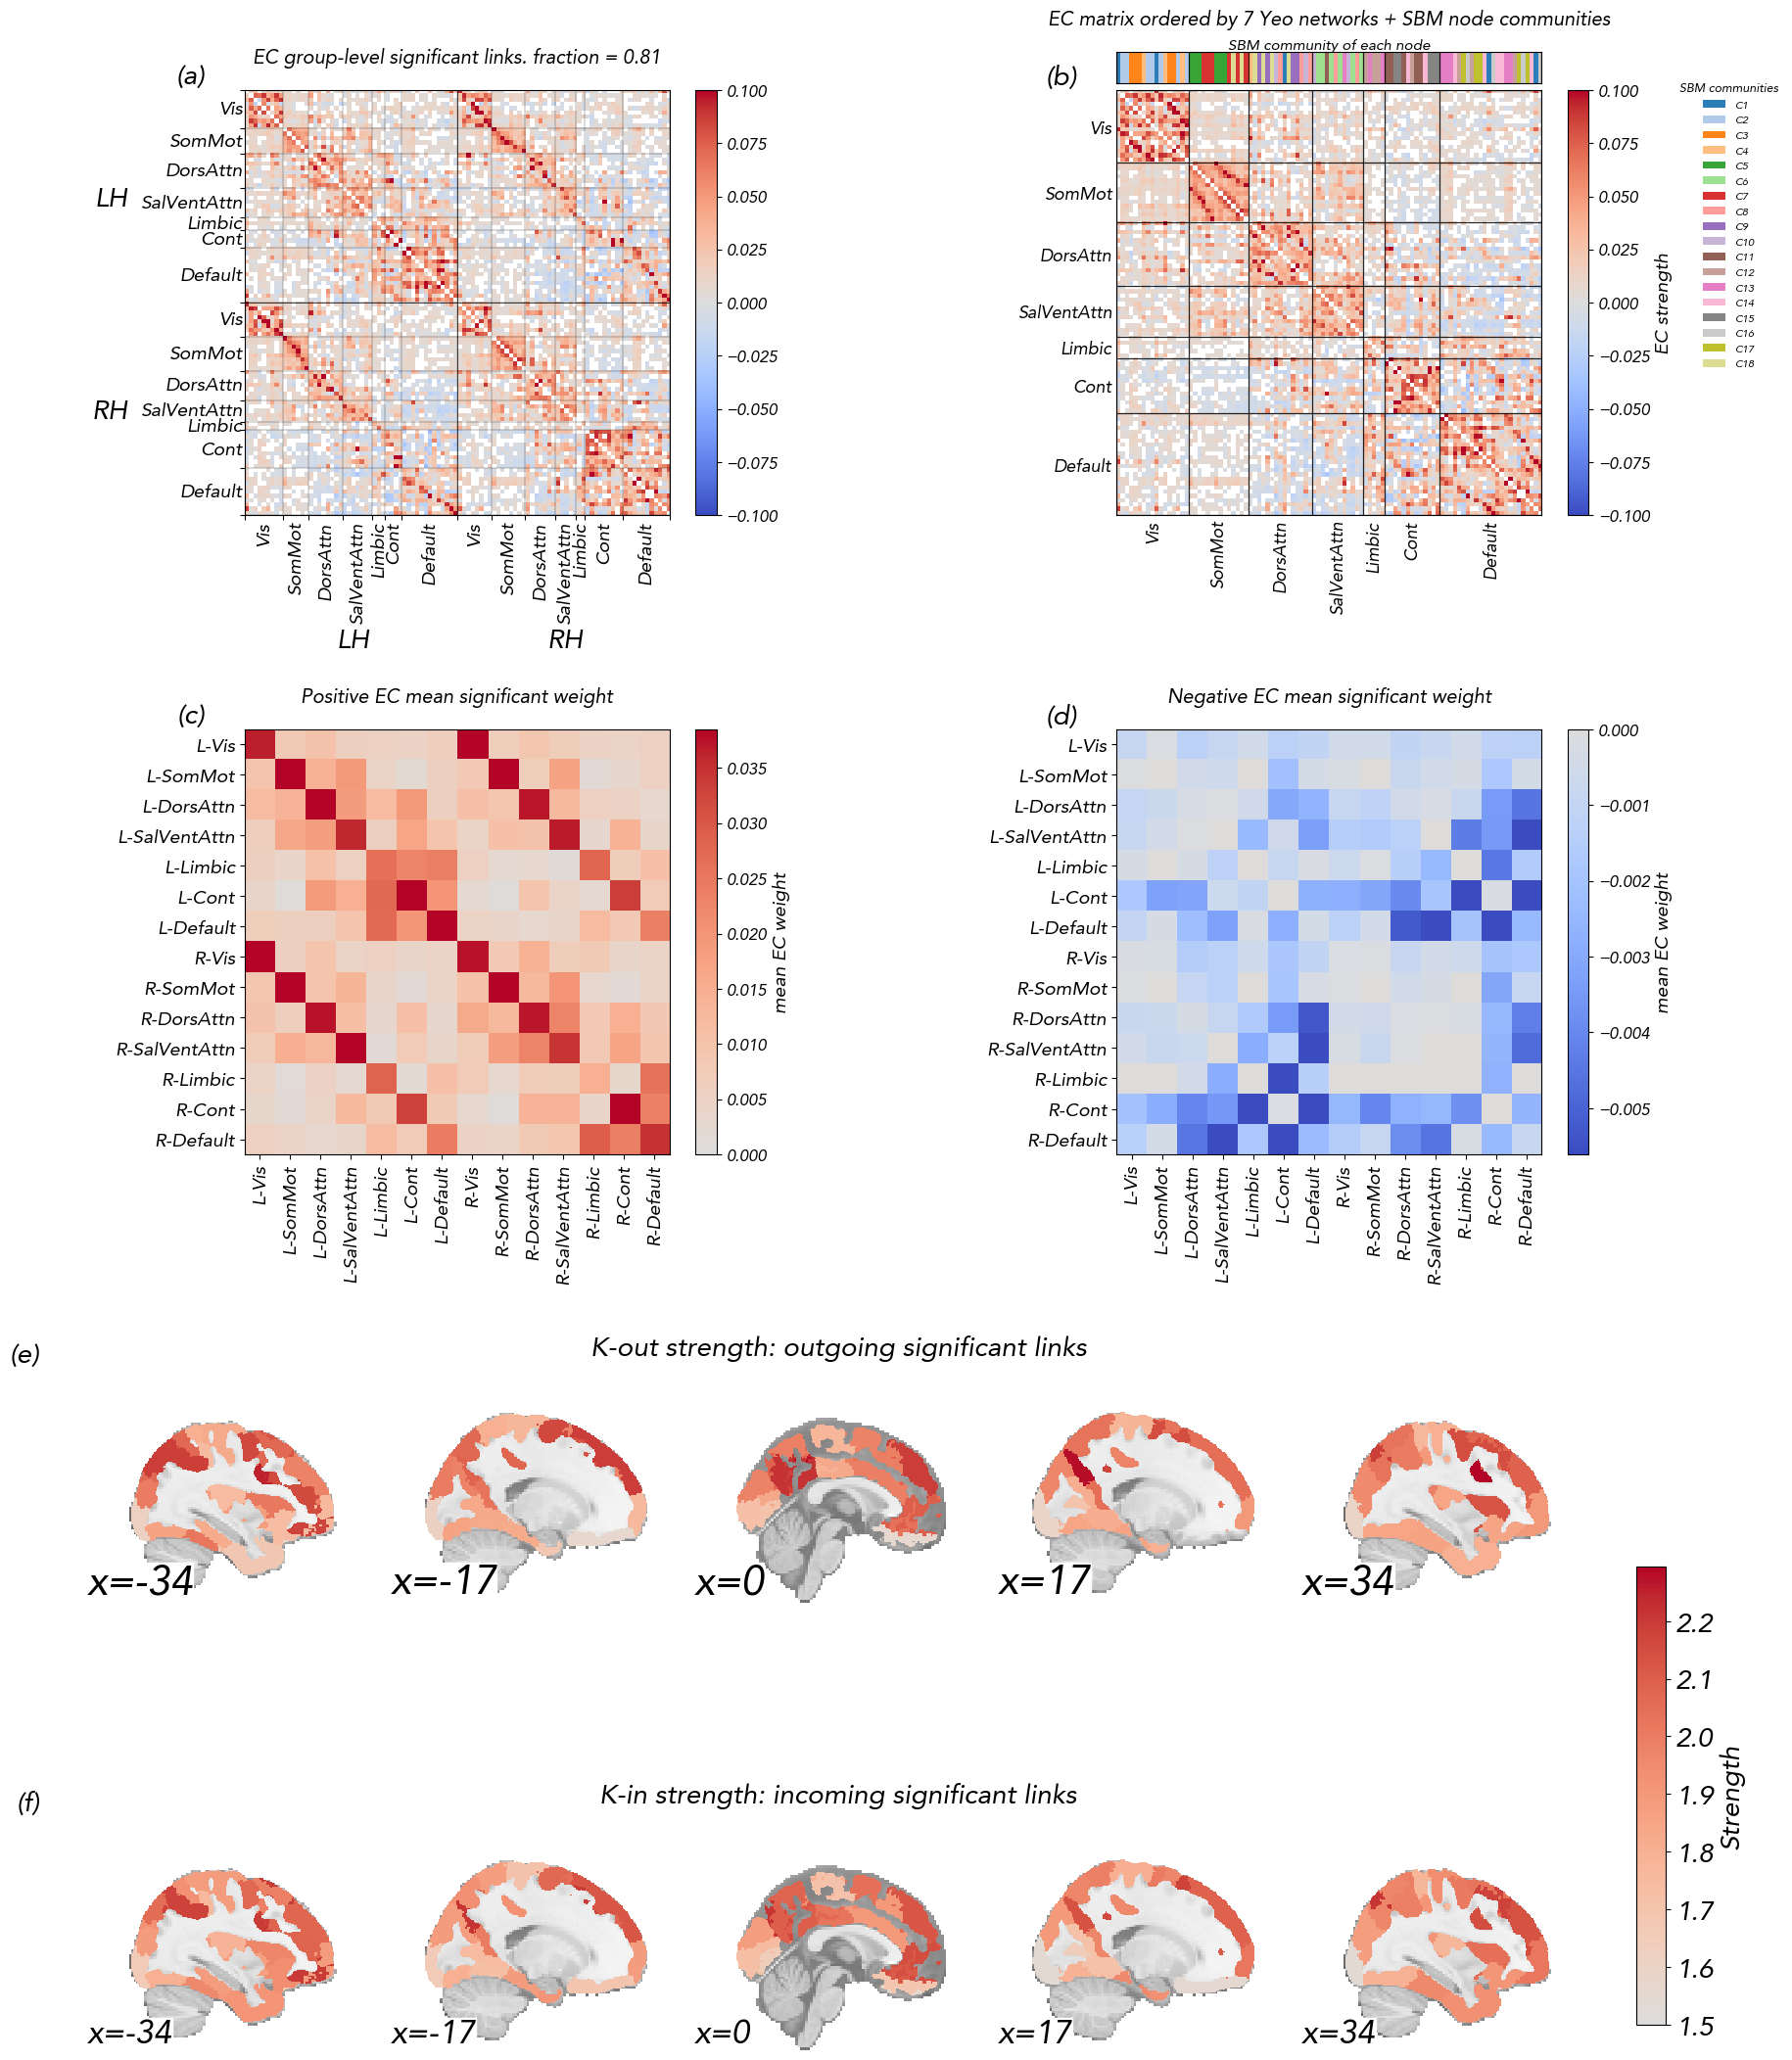

In [33]:
ssi_mean = np.mean(np.asarray(ssi_norm_all), 0)

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import nilearn.plotting as plotting

from matplotlib.colors import ListedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import colormaps
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
from collections import OrderedDict
from sklearn.metrics import normalized_mutual_info_score

plt.rcParams['font.size'] = 18


# =========================================================
# FC PLOTTING FUNCTION
# =========================================================

def plot_fc_matrix(fc, labels, ax, cmap="bwr", vmin=-0.2, vmax=0.2):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]

    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order, bounds, names = [], [], []
    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)

    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks) - .5)
    ax.set_yticks(np.array(ticks) - .5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    for t in ticks:
        ax.axhline(t - 0.5, color="black", linewidth=0.2)
        ax.axvline(t - 0.5, color="black", linewidth=0.2)

    lh_count = sum(lab.startswith("LH_") for lab in labels)

    ax.axhline(lh_count - 0.5, color="black", linewidth=0.5)
    ax.axvline(lh_count - 0.5, color="black", linewidth=0.5)

    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split("_")

        ax.text(
            center - .5, n + 1, net,
            ha="center", va="top",
            rotation=90, clip_on=False,fontsize = 14
        )

        ax.text(
            -1, center - .5, net,
            ha="right", va="center",
            clip_on=False, fontsize = 14
        )

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2

    offset_x = n + 26
    offset_y = -28

    ax.text(
        lh_center, offset_x, "LH",
        ha="center", va="top",
        fontweight='bold', clip_on=False, fontsize=20
    )

    ax.text(
        rh_center, offset_x, "RH",
        ha="center", va="top",
        fontweight='bold', clip_on=False, fontsize=20
    )

    ax.text(
        offset_y, lh_center, "LH",
        ha="right", va="center",
        fontweight='bold', clip_on=False, fontsize=20
    )

    ax.text(
        offset_y, rh_center, "RH",
        ha="right", va="center",
        fontweight='bold', clip_on=False, fontsize=20
    )

    return im


# =========================================================
# COMMUNITY MATRIX FUNCTION
# =========================================================

def plot(a, labels, ax, fig, no_net=14, cmap='Greens', fontsize=14):

    partition_array = np.array(a[0])

    unique_blocks = np.unique(partition_array)
    id_map = {old: new for new, old in enumerate(unique_blocks)}
    compact_partition = np.array([id_map[b] for b in partition_array])

    N = len(partition_array)

    if N != len(labels):
        raise Exception("wrong shape")

    yeo_names_2 = [
        "LH_Vis", "LH_SomMot", "LH_DorsAttn",
        "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
        "RH_Vis", "RH_SomMot", "RH_DorsAttn",
        "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
    ]

    riferi = yeo_names_2 if no_net == 14 else yeo_names_2[:7]

    schaefer_network_hemi_2 = np.zeros(N, dtype=int)

    for i, lab in enumerate(labels):
        for k, net in enumerate(riferi):
            if net in lab:
                schaefer_network_hemi_2[i] = k
                break

    K = len(np.unique(compact_partition))
    Y = len(np.unique(schaefer_network_hemi_2))

    M = np.zeros((K, Y), dtype=float)

    for i in range(N):
        M[compact_partition[i], schaefer_network_hemi_2[i]] += 1

    M = M / (M.sum(axis=1, keepdims=True) + 1e-12)

    im = ax.imshow(M, cmap=cmap, aspect='auto')

    ax.set_title(f"SBM vs Yeo-{len(riferi)}")
    ax.set_ylabel("SBM communities")

    ax.set_xticks(np.arange(Y))
    ax.set_xticklabels(riferi, rotation=90, ha='right', fontsize=fontsize)

    ax.set_yticks(np.arange(K))
    ax.set_yticklabels(np.arange(K), fontsize=fontsize)

    fig.colorbar(
        im,
        ax=ax,
        label='fraction of nodes',
        fraction=0.046,
        pad=0.04
    )

    nmi = normalized_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition
    )

    print("NMI SBM vs Yeo:", len(riferi), nmi)

    return im, nmi


# =========================================================
# FIGURE LAYOUT
# =========================================================

fig = plt.figure(figsize=(20, 26))

gs = fig.add_gridspec(
    4, 2,
    height_ratios=[1, 1, .55, .55],
    width_ratios=[1, 1],
    hspace=.65,
    wspace=.35
)

ax_fc        = fig.add_subplot(gs[0, 0])
ax_cm        = fig.add_subplot(gs[0, 1])
ax_pos       = fig.add_subplot(gs[1, 0])
ax_neg       = fig.add_subplot(gs[1, 1])
ax_brain_out = fig.add_subplot(gs[2, 0:2])
ax_brain_in  = fig.add_subplot(gs[3, 0:2])

plt.rcParams['font.size'] = 12


# =========================================================
# (a) FC SIGNIFICANT LINKS
# =========================================================

JS_fc = JS[:, :100, :100]
n_nodes = JS_fc.shape[1]

_, p_values = ttest_1samp(JS_fc, popmean=0, axis=0)

mask = ~np.eye(n_nodes, dtype=bool)
p_flat = p_values[mask]

reject, _, _, _ = multipletests(
    p_flat,
    method='bonferroni',
    alpha=0.05
)

sig_mask = np.zeros((n_nodes, n_nodes), dtype=bool)
sig_mask[mask] = reject
np.fill_diagonal(sig_mask, 0)

mean_fc = np.mean(JS_fc, axis=0)

vis_fc = np.full((n_nodes, n_nodes), np.nan)
vis_fc[sig_mask] = mean_fc[sig_mask]

cmap_fc = colormaps['coolwarm'].copy()
cmap_fc.set_bad(color='white')

media = dediag(np.mean(JS, 0))

im_fc = plot_fc_matrix(
    vis_fc,
    labels100,
    ax=ax_fc,
    cmap=cmap_fc,
    vmin=-0.1,
    vmax=0.1
)

ax_fc.set_title(
    f"EC group-level significant links. fraction = {sig_mask.sum() / (n_nodes * (n_nodes - 1)):.2f}",
    pad=20
)

fig.colorbar(im_fc, ax=ax_fc, fraction=0.046, pad=0.04)


# =========================================================
# (b) COMMUNITY MATRIX
# =========================================================
# =========================================================
# (b) EC CONNECTIVITY MATRIX ORDERED BY SBM COMMUNITIES
# =========================================================
# =========================================================
# =========================================================
# (b) EC MATRIX ORDERED BY 7 YEO NETWORKS + TOP SBM COMMUNITY BAR
# =========================================================

from matplotlib.patches import Patch

def plot_ec_matrix_7net_with_sbm_topbar(
    ec_mat,
    sig_mask,
    labels,
    communities,
    ax,
    fig,
    cmap_ec="coolwarm",
    vmin=-0.1,
    vmax=0.1,
    node_bar_alpha=0.95,
    network_linewidth=0.9,
    fontsize_net=13
):
    """
    EC matrix ordered by 7 Yeo networks.

    Order:
        LH_Vis, RH_Vis,
        LH_SomMot, RH_SomMot,
        ...
        LH_Default, RH_Default

    The SBM communities are shown only as a top bar.
    No community lines/overlays are drawn inside the matrix.
    """

    # ---------------------------
    # inputs
    # ---------------------------
    ec_mat = np.asarray(ec_mat)
    sig_mask = np.asarray(sig_mask)
    communities = np.asarray(communities)

    if ec_mat.shape[0] != ec_mat.shape[1]:
        raise ValueError("ec_mat deve essere quadrata.")

    if sig_mask.shape != ec_mat.shape:
        raise ValueError("sig_mask deve avere la stessa shape di ec_mat.")

    if len(labels) != ec_mat.shape[0]:
        raise ValueError("labels deve avere la stessa lunghezza della matrice EC.")

    if len(communities) != ec_mat.shape[0]:
        raise ValueError("communities deve avere la stessa lunghezza della matrice EC.")

    # ---------------------------
    # 7-network order
    # ---------------------------
    yeo_7 = [
        "Vis",
        "SomMot",
        "DorsAttn",
        "SalVentAttn",
        "Limbic",
        "Cont",
        "Default"
    ]

    hemis = ["LH", "RH"]

    def parse_label(lab):
        parts = lab.split("_")
        hemi = parts[0]
        net = parts[1]
        return hemi, net

    # ---------------------------
    # order nodes: network first, then LH/RH
    # ---------------------------
    new_order = []
    bounds = []
    names = []

    start = 0

    for net in yeo_7:
        idx_net = []

        for hemi in hemis:
            idx_hemi_net = [
                i for i, lab in enumerate(labels)
                if parse_label(lab)[0] == hemi and parse_label(lab)[1] == net
            ]

            idx_net.extend(idx_hemi_net)

        new_order.extend(idx_net)

        end = start + len(idx_net)
        bounds.append((start, end))
        names.append(net)
        start = end

    if len(new_order) != len(labels):
        missing = set(range(len(labels))) - set(new_order)
        raise ValueError(
            f"Alcune ROI non sono state ordinate. Indici mancanti: {missing}"
        )

    # ---------------------------
    # significant EC matrix
    # ---------------------------
    ec_sig = ec_mat.copy()
    ec_sig[~sig_mask] = np.nan
    np.fill_diagonal(ec_sig, np.nan)

    ec_ord = ec_sig[np.ix_(new_order, new_order)]
    comm_ord = communities[new_order]

    n = ec_ord.shape[0]

    # ---------------------------
    # compact community labels
    # ---------------------------
    unique_comms = np.unique(comm_ord)
    comm_map = {old: new for new, old in enumerate(unique_comms)}
    comm_compact = np.array([comm_map[c] for c in comm_ord])

    ncomm = len(unique_comms)

    # ---------------------------
    # community colors for top bar
    # ---------------------------
    base_colors = plt.cm.tab20(np.linspace(0, 1, max(ncomm, 20)))[:ncomm]
    base_colors[:, 3] = node_bar_alpha

    # ---------------------------
    # plot EC matrix
    # ---------------------------
    cmap_use = colormaps[cmap_ec].copy()
    cmap_use.set_bad(color="white")

    im = ax.imshow(
        ec_ord,
        cmap=cmap_use,
        vmin=vmin,
        vmax=vmax,
        interpolation="none"
    )

    # =====================================================
    # TOP COMMUNITY BAR ONLY
    # =====================================================

    top_bar = np.zeros((1, n, 4))

    for i, c in enumerate(comm_compact):
        top_bar[0, i, :] = base_colors[c]

    ax_top = ax.inset_axes([0, 1.015, 1, 0.075])
    ax_top.imshow(top_bar, aspect="auto", interpolation="none")
    ax_top.set_xticks([])
    ax_top.set_yticks([])
    ax_top.set_title("SBM community of each node", fontsize=11, pad=2)

    # ---------------------------
    # 7-network boundaries only
    # ---------------------------
    ticks = [0] + [end for _, end in bounds]

    for t in ticks:
        ax.axhline(
            t - 0.5,
            color="black",
            linewidth=network_linewidth,
            alpha=0.85
        )

        ax.axvline(
            t - 0.5,
            color="black",
            linewidth=network_linewidth,
            alpha=0.85
        )

        ax_top.axvline(
            t - 0.5,
            color="black",
            linewidth=network_linewidth,
            alpha=0.85
        )

    # ---------------------------
    # axis labels: 7 networks
    # ---------------------------
    label_pos = []
    label_txt = []

    for (start, end), net in zip(bounds, names):
        label_pos.append((start + end - 1) / 2)
        label_txt.append(net)

    ax.set_xticks(label_pos)
    ax.set_yticks(label_pos)

    ax.set_xticklabels(
        label_txt,
        rotation=90,
        fontsize=fontsize_net
    )

    ax.set_yticklabels(
        label_txt,
        fontsize=fontsize_net
    )

    ax.tick_params(length=0)

    # ---------------------------
    # legend for SBM communities
    # ---------------------------
    legend_handles = []

    for c, old_label in enumerate(unique_comms):
        legend_handles.append(
            Patch(
                facecolor=base_colors[c],
                edgecolor="none",
                label=f"C{c + 1}"
            )
        )

    ax.legend(
        handles=legend_handles,
        title="SBM communities",
        loc="upper left",
        bbox_to_anchor=(1.3, 1.04),
        frameon=False,
        fontsize=8,
        title_fontsize=9,
        ncol=1
    )

    # ---------------------------
    # final settings
    # ---------------------------
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    ax.set_title(
        "EC matrix ordered by 7 Yeo networks + SBM node communities",
        pad=48
    )

    return im


# ---------------------------
# Plot panel b
# ---------------------------

communities = np.asarray(a_ec_norm[0])

im_cm = plot_ec_matrix_7net_with_sbm_topbar(
    ec_mat=media[:100, :100],
    sig_mask=sig_mask,
    labels=labels100,
    communities=communities,
    ax=ax_cm,
    fig=fig,
    cmap_ec="coolwarm",
    vmin=-0.1,
    vmax=0.1,
    node_bar_alpha=0.95,
    network_linewidth=0.9,
    fontsize_net=13
)

ax_cm.set_box_aspect(1)

cbar_cm = fig.colorbar(
    im_cm,
    ax=ax_cm,
    fraction=0.046,
    pad=0.04,
    label="EC strength"
)

cbar_cm.set_label("EC strength", fontsize=14)
cbar_cm.ax.tick_params(labelsize=12)
# =========================================================
# (c) POSITIVE / (d) NEGATIVE EC - 14x14 SIGNIFICANT LINKS
# =========================================================
# =========================================================
# (c) POSITIVE / (d) NEGATIVE EC - MEAN SIGNIFICANT LINK WEIGHT 14x14
# =========================================================

yeo_names_14 = [
    "LH_Vis", "LH_SomMot", "LH_DorsAttn",
    "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
    "RH_Vis", "RH_SomMot", "RH_DorsAttn",
    "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
]

short_yeo_names = [
    x.replace("LH_", "L-").replace("RH_", "R-")
    for x in yeo_names_14
]

# ---------------------------
# assign each ROI to one of the 14 Yeo/hemi networks
# ---------------------------
net_ids = np.full(len(labels), -1, dtype=int)

for i, lab in enumerate(labels):
    for k, net in enumerate(yeo_names_14):
        if net in lab:
            net_ids[i] = k
            break

if np.any(net_ids == -1):
    raise ValueError("Alcune label in labels100 non sono state assegnate a nessun network.")

# ---------------------------
# significant EC matrix
# ---------------------------
mat = media[:100, :100].copy()
mat[~sig_mask] = 0
np.fill_diagonal(mat, 0)

pos_mask = mat > 0
neg_mask = mat < 0

nnet = len(yeo_names_14)
pos_mat = mat*pos_mask
neg_mat = mat*neg_mask

# sums of weights
pos_sum = np.zeros((nnet, nnet), dtype=float)
neg_sum = np.zeros((nnet, nnet), dtype=float)

# counts of significant links
pos_count = np.zeros((nnet, nnet), dtype=float)
neg_count = np.zeros((nnet, nnet), dtype=float)

# ---------------------------
# aggregate sums and counts
# ---------------------------
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):

        ni = net_ids[i]
        nj = net_ids[j]

        #if pos_mask[i, j]:
        pos_sum[ni, nj] += pos_mat[i, j]
        pos_count[ni, nj] += 1

        #elif neg_mask[i, j]:
        neg_sum[ni, nj] += neg_mat[i, j]
        neg_count[ni, nj] += 1

# ---------------------------
# mean significant link weight
# ---------------------------
pos_net = np.full((nnet, nnet), np.nan)
neg_net = np.full((nnet, nnet), 0, dtype = float)

pos_net[pos_count > 0] = pos_sum[pos_count > 0] / pos_count[pos_count > 0]
neg_net[neg_count > 0] = neg_sum[neg_count > 0] / neg_count[neg_count > 0]

# Optional:
# if you prefer empty cells to be zero instead of white/nan:
# pos_net = np.nan_to_num(pos_net, nan=0)
# neg_net = np.nan_to_num(neg_net, nan=0)

# ---------------------------
# colormaps
# ---------------------------
base = colormaps['coolwarm']

reds = ListedColormap(base(np.linspace(0.5, 1.0, 256)))
blues = ListedColormap(base(np.linspace(0.0, 0.5, 256)))

#reds.set_bad(color='white')
#blues.set_bad(color='white')

# robust limits
pos_vmax = np.nanpercentile(pos_net, 95) if np.any(~np.isnan(pos_net)) else 1
neg_vmax = np.nanpercentile(np.abs(neg_net), 95) if np.any(~np.isnan(neg_net)) else 1

if pos_vmax == 0:
    pos_vmax = np.nanmax(pos_net)

if neg_vmax == 0:
    neg_vmax = np.nanmax(np.abs(neg_net))

# =========================================================
# Positive mean EC
# =========================================================

im_pos = ax_pos.imshow(
    pos_net,
    cmap=reds,
    vmin=0,
    vmax=pos_vmax
)

ax_pos.set_title("Positive EC mean significant weight", pad=20)
ax_pos.set_xticks(np.arange(nnet))
ax_pos.set_yticks(np.arange(nnet))
ax_pos.set_xticklabels(short_yeo_names, rotation=90, fontsize=14)
ax_pos.set_yticklabels(short_yeo_names, fontsize=14)

cbar_pos = fig.colorbar(
    im_pos,
    ax=ax_pos,
    fraction=0.046,
    pad=0.04,
    label='mean EC weight'
)

cbar_pos.set_label('mean EC weight', fontsize=14)
cbar_pos.ax.tick_params(labelsize=12)

# =========================================================
# Negative mean EC
# =========================================================

im_neg = ax_neg.imshow(
    neg_net,
    cmap=blues,
    vmin=-neg_vmax,
    vmax=0
)

ax_neg.set_title("Negative EC mean significant weight", pad=20)
ax_neg.set_xticks(np.arange(nnet))
ax_neg.set_yticks(np.arange(nnet))
ax_neg.set_xticklabels(short_yeo_names, rotation=90, fontsize=14)
ax_neg.set_yticklabels(short_yeo_names, fontsize=14)

cbar_neg = fig.colorbar(
    im_neg,
    ax=ax_neg,
    fraction=0.046,
    pad=0.04,
    label='mean EC weight'
)

cbar_neg.set_label('mean EC weight', fontsize=14)
cbar_neg.ax.tick_params(labelsize=12)

# =========================================================
# (e) / (f) BRAIN MAPS - K-OUT AND K-IN DEGREE
# =========================================================

I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)

data = I1.get_fdata()
affine = I1.affine

A = media[:100, :100].copy()
A[~sig_mask] = 0
np.fill_diagonal(A, 0)

# binary degree: number of significant directed links
k_out = np.mean(out_strength,0)
k_in = np.mean(in_strength,0)
#np.sum(np.abs(A) , axis=1)
#k_in = np.sum(np.abs(A), axis=0)

data_kout = np.zeros_like(data)
data_kin = np.zeros_like(data)

for r in range(100):
    data_kout[data == r + 1] = k_out[r]
    data_kin[data == r + 1] = k_in[r]

img_kout = nib.Nifti1Image(data_kout, affine)
img_kin = nib.Nifti1Image(data_kin, affine)

vmax_degree = max(k_out.max(), k_in.max())

display=plotting.plot_stat_map(
    img_kout,
    cmap=reds,
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_out,
    vmin=1.5
    ,
    vmax=vmax_degree
)


for ax in display.axes.values():
    for text in ax.ax.texts:
        text.set_fontsize(30)
ax_brain_out.set_title("K-out strength: outgoing significant links", pad=10, fontsize =20)

display=plotting.plot_stat_map(
    img_kin,
    cmap=reds,
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_in,
    vmin=1.5,
    vmax=vmax_degree
)

ax_brain_in.set_title("K-in strength: incoming significant links", pad=10, fontsize =20)

norm = Normalize(vmin=1.5, vmax=vmax_degree)
sm = ScalarMappable(norm=norm, cmap=reds)
sm.set_array([])

cax = fig.add_axes([0.92, 0.12, 0.015, 0.18])

cbar=fig.colorbar(
    sm,
    cax=cax,
    label='Strength',
)
cbar.set_label('Strength', fontsize=20)
cbar.ax.tick_params(labelsize=20)
# =========================================================
# FINAL LAYOUT AND PANEL LABELS
# =========================================================

plt.subplots_adjust(hspace=0.7, wspace=0.35)


def add_panel_label(ax, label):
    bbox = ax.get_position()

    fig.text(
        bbox.x0 - 0.02,
        bbox.y1 + 0.01,
        label,
        fontsize=20,
        fontweight='bold',
        va='top',
        ha='right'
    )

add_panel_label(ax_fc, "(a)")
add_panel_label(ax_cm, "(b)")
add_panel_label(ax_pos, "(c)")
add_panel_label(ax_neg, "(d)")
add_panel_label(ax_brain_out, "(e)")
add_panel_label(ax_brain_in, "(f)")

# enlarge coordinate labels in nilearn brain plots
for ax in display.axes.values():
    for text in ax.ax.texts:
        text.set_fontsize(24)
#for ax in fig.get_axes():
 #   for text in ax.texts:
  #      if text.get_text().replace("-", "").replace(".", "").isdigit():
   #         text.set_fontsize(40)

#plt.savefig('Figures/networks_figure_2.jpg', bbox_inches='tight', dpi=300)
plt.show()

In [26]:
labels100=labels

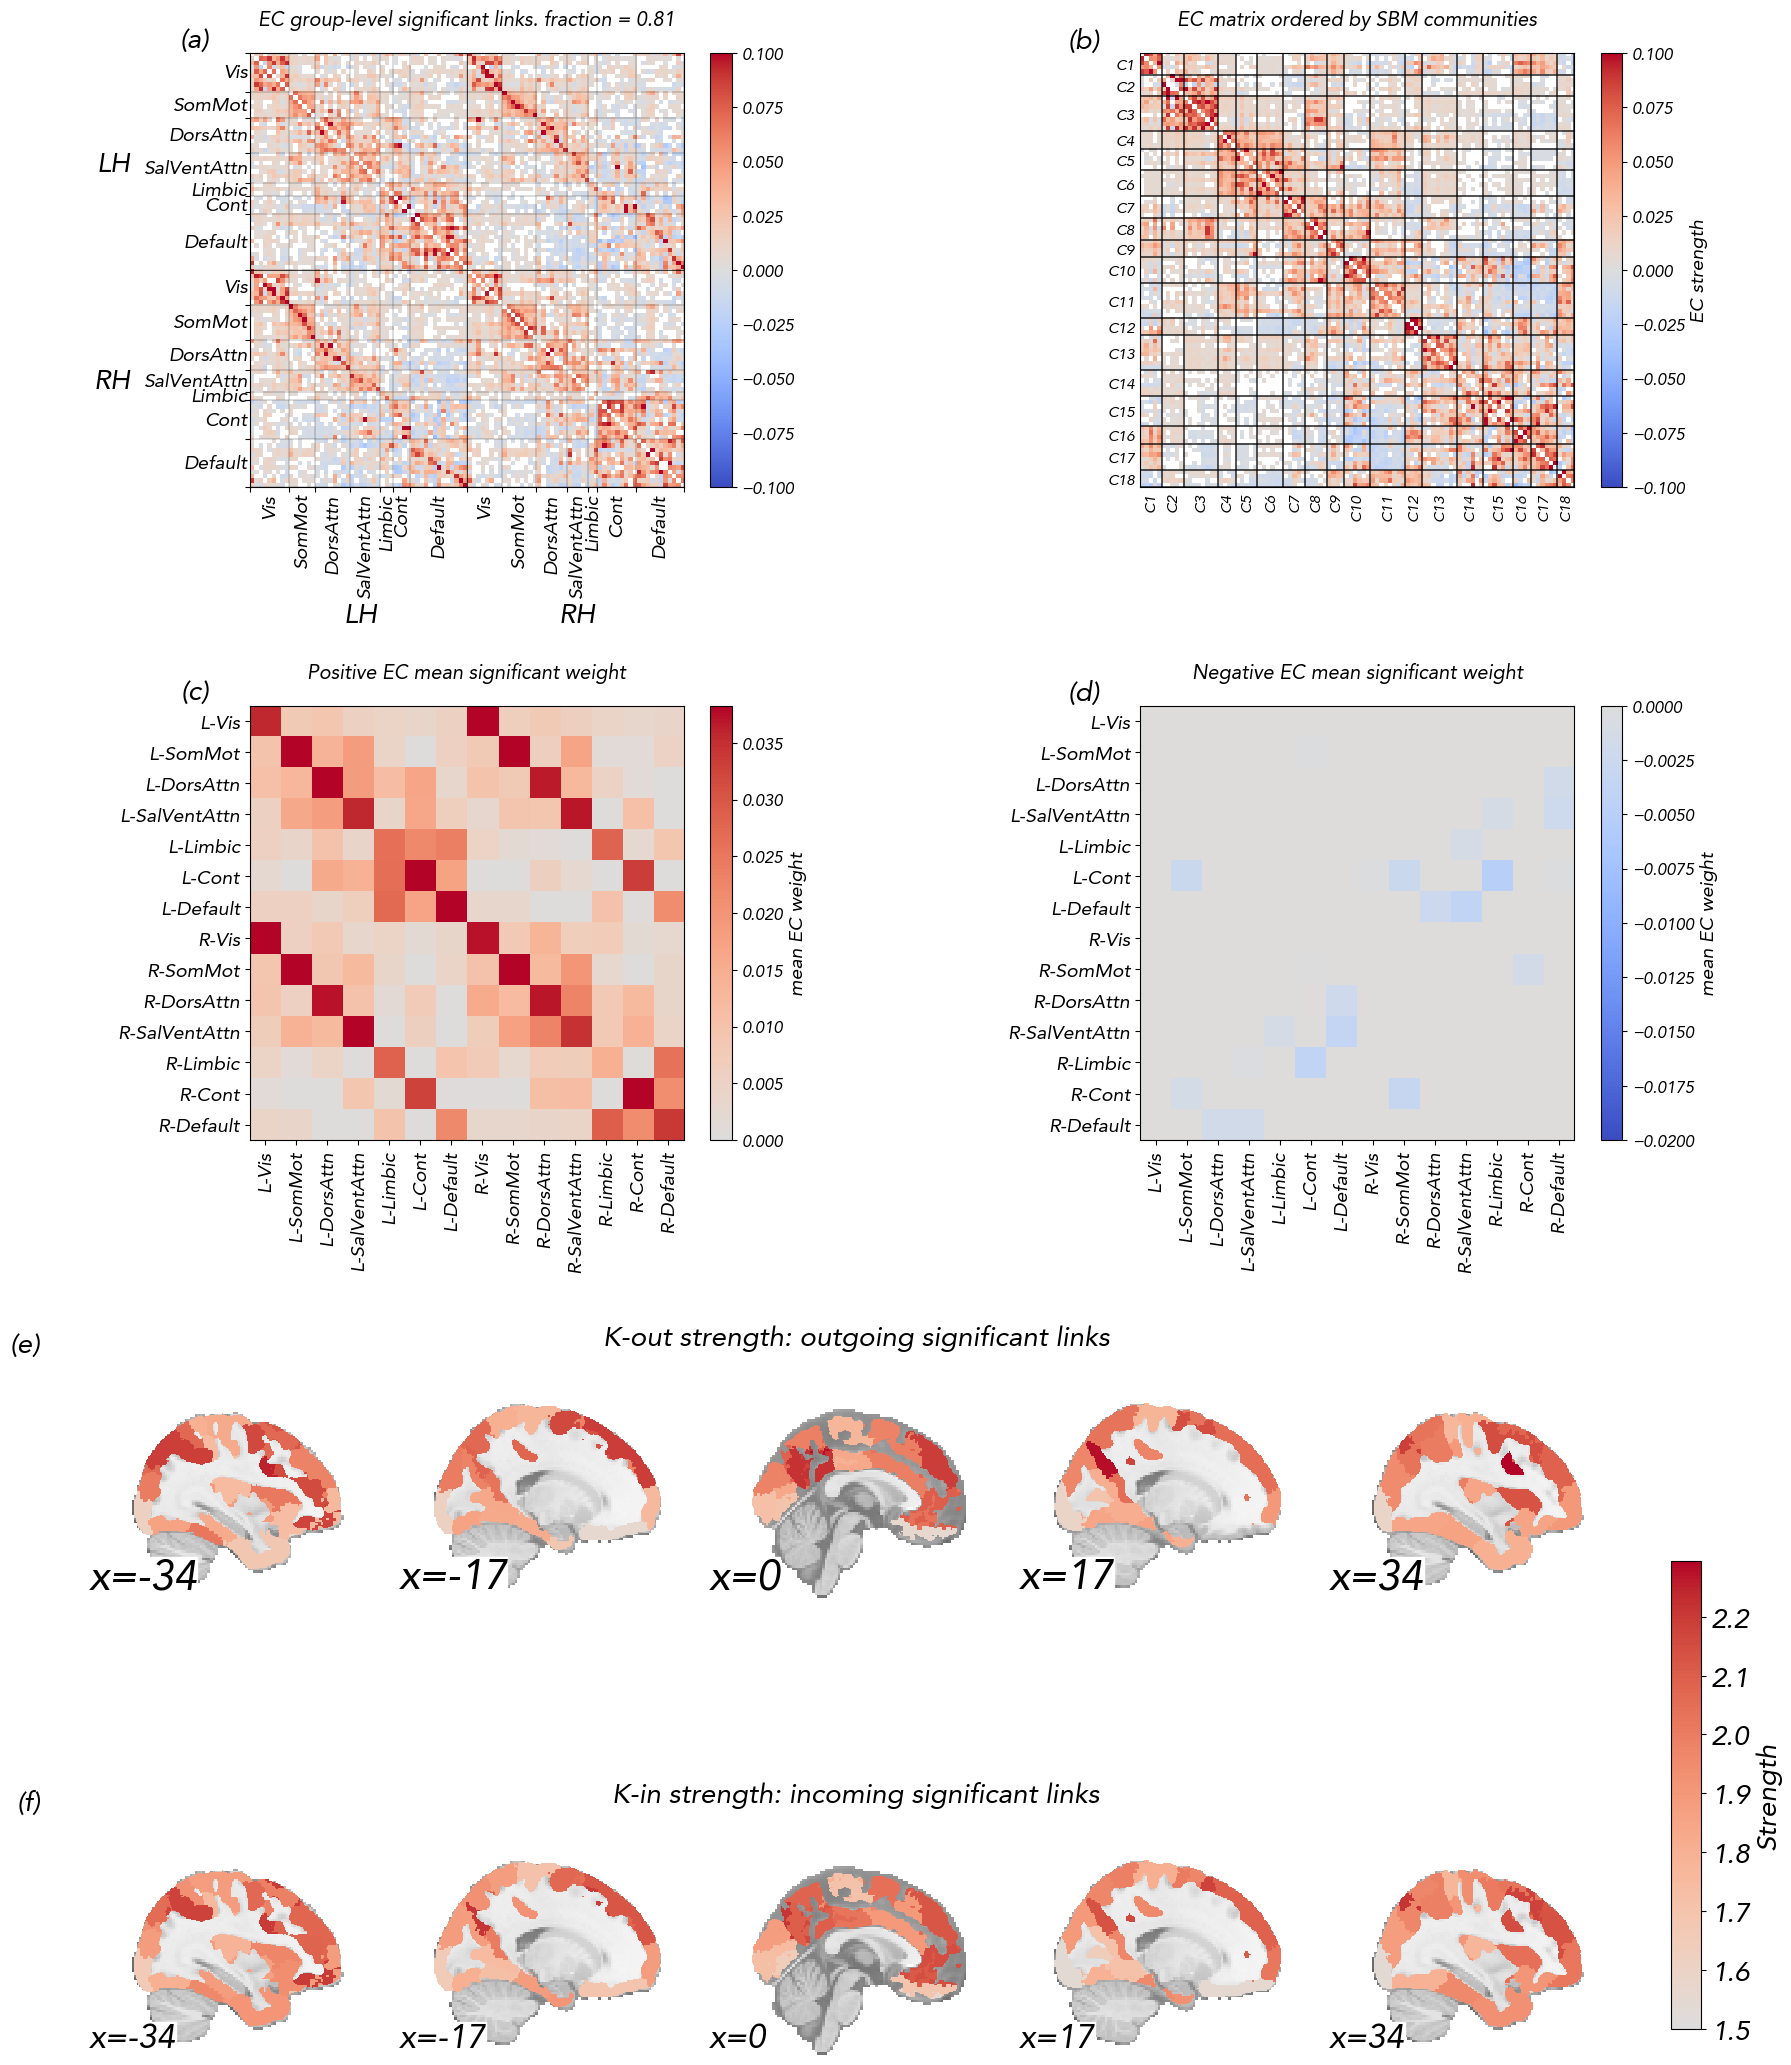

In [49]:
ssi_mean = np.mean(np.asarray(ssi_norm_all), 0)

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import nilearn.plotting as plotting

from matplotlib.colors import ListedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import colormaps
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
from collections import OrderedDict
from sklearn.metrics import normalized_mutual_info_score

plt.rcParams['font.size'] = 18


# =========================================================
# FC PLOTTING FUNCTION
# =========================================================

def plot_fc_matrix(fc, labels, ax, cmap="bwr", vmin=-0.2, vmax=0.2):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]

    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order, bounds, names = [], [], []
    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)

    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks) - .5)
    ax.set_yticks(np.array(ticks) - .5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    for t in ticks:
        ax.axhline(t - 0.5, color="black", linewidth=0.2)
        ax.axvline(t - 0.5, color="black", linewidth=0.2)

    lh_count = sum(lab.startswith("LH_") for lab in labels)

    ax.axhline(lh_count - 0.5, color="black", linewidth=0.5)
    ax.axvline(lh_count - 0.5, color="black", linewidth=0.5)

    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split("_")

        ax.text(
            center - .5, n + 1, net,
            ha="center", va="top",
            rotation=90, clip_on=False,fontsize = 14
        )

        ax.text(
            -1, center - .5, net,
            ha="right", va="center",
            clip_on=False, fontsize = 14
        )

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2

    offset_x = n + 26
    offset_y = -28

    ax.text(
        lh_center, offset_x, "LH",
        ha="center", va="top",
        fontweight='bold', clip_on=False, fontsize=20
    )

    ax.text(
        rh_center, offset_x, "RH",
        ha="center", va="top",
        fontweight='bold', clip_on=False, fontsize=20
    )

    ax.text(
        offset_y, lh_center, "LH",
        ha="right", va="center",
        fontweight='bold', clip_on=False, fontsize=20
    )

    ax.text(
        offset_y, rh_center, "RH",
        ha="right", va="center",
        fontweight='bold', clip_on=False, fontsize=20
    )

    return im


# =========================================================
# COMMUNITY MATRIX FUNCTION
# =========================================================

def plot(a, labels, ax, fig, no_net=14, cmap='Greens', fontsize=14):

    partition_array = np.array(a[0])

    unique_blocks = np.unique(partition_array)
    id_map = {old: new for new, old in enumerate(unique_blocks)}
    compact_partition = np.array([id_map[b] for b in partition_array])

    N = len(partition_array)

    if N != len(labels):
        raise Exception("wrong shape")

    yeo_names_2 = [
        "LH_Vis", "LH_SomMot", "LH_DorsAttn",
        "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
        "RH_Vis", "RH_SomMot", "RH_DorsAttn",
        "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
    ]

    riferi = yeo_names_2 if no_net == 14 else yeo_names_2[:7]

    schaefer_network_hemi_2 = np.zeros(N, dtype=int)

    for i, lab in enumerate(labels):
        for k, net in enumerate(riferi):
            if net in lab:
                schaefer_network_hemi_2[i] = k
                break

    K = len(np.unique(compact_partition))
    Y = len(np.unique(schaefer_network_hemi_2))

    M = np.zeros((K, Y), dtype=float)

    for i in range(N):
        M[compact_partition[i], schaefer_network_hemi_2[i]] += 1

    M = M / (M.sum(axis=1, keepdims=True) + 1e-12)

    im = ax.imshow(M, cmap=cmap, aspect='auto')

    ax.set_title(f"SBM vs Yeo-{len(riferi)}")
    ax.set_ylabel("SBM communities")

    ax.set_xticks(np.arange(Y))
    ax.set_xticklabels(riferi, rotation=90, ha='right', fontsize=fontsize)

    ax.set_yticks(np.arange(K))
    ax.set_yticklabels(np.arange(K), fontsize=fontsize)

    fig.colorbar(
        im,
        ax=ax,
        label='fraction of nodes',
        fraction=0.046,
        pad=0.04
    )

    nmi = normalized_mutual_info_score(
        schaefer_network_hemi_2,
        compact_partition
    )

    print("NMI SBM vs Yeo:", len(riferi), nmi)

    return im, nmi


# =========================================================
# FIGURE LAYOUT
# =========================================================

fig = plt.figure(figsize=(20, 26))

gs = fig.add_gridspec(
    4, 2,
    height_ratios=[1, 1, .55, .55],
    width_ratios=[1, 1],
    hspace=.65,
    wspace=.35
)

ax_fc        = fig.add_subplot(gs[0, 0])
ax_cm        = fig.add_subplot(gs[0, 1])
ax_pos       = fig.add_subplot(gs[1, 0])
ax_neg       = fig.add_subplot(gs[1, 1])
ax_brain_out = fig.add_subplot(gs[2, 0:2])
ax_brain_in  = fig.add_subplot(gs[3, 0:2])

plt.rcParams['font.size'] = 12


# =========================================================
# (a) FC SIGNIFICANT LINKS
# =========================================================

JS_fc = JS[:, :100, :100]
n_nodes = JS_fc.shape[1]

_, p_values = ttest_1samp(JS_fc, popmean=0, axis=0)

mask = ~np.eye(n_nodes, dtype=bool)
p_flat = p_values[mask]

reject, _, _, _ = multipletests(
    p_flat,
    method='bonferroni',
    alpha=0.05
)

sig_mask = np.zeros((n_nodes, n_nodes), dtype=bool)
sig_mask[mask] = reject
np.fill_diagonal(sig_mask, 0)

mean_fc = np.mean(JS_fc, axis=0)

vis_fc = np.full((n_nodes, n_nodes), np.nan)
vis_fc[sig_mask] = mean_fc[sig_mask]

cmap_fc = colormaps['coolwarm'].copy()
cmap_fc.set_bad(color='white')

media = dediag(np.mean(JS, 0))

im_fc = plot_fc_matrix(
    vis_fc,
    labels100,
    ax=ax_fc,
    cmap=cmap_fc,
    vmin=-0.1,
    vmax=0.1
)

ax_fc.set_title(
    f"EC group-level significant links. fraction = {sig_mask.sum() / (n_nodes * (n_nodes - 1)):.2f}",
    pad=20
)

fig.colorbar(im_fc, ax=ax_fc, fraction=0.046, pad=0.04)


# =========================================================
# (b) COMMUNITY MATRIX
# =========================================================
# =========================================================
# (b) EC CONNECTIVITY MATRIX ORDERED BY SBM COMMUNITIES
# =========================================================
# =========================================================
# =========================================================
# (b) EC MATRIX ORDERED BY 7 YEO NETWORKS + TOP SBM COMMUNITY BAR
# =========================================================
# =========================================================
# (b) EC MATRIX ORDERED BY SBM COMMUNITIES
# =========================================================

def plot_ec_matrix_ordered_by_sbm(
    ec_mat,
    sig_mask,
    communities,
    ax,
    cmap_ec="coolwarm",
    vmin=-0.1,
    vmax=0.1,
    community_linewidth=1.1,
    fontsize_comm=11
):
    """
    Plot EC matrix ordered by SBM communities.

    ec_mat: 100 x 100 EC matrix
    sig_mask: 100 x 100 boolean significance mask
    communities: SBM community assignment, one value per node

    The only change is node ordering:
    nodes belonging to the same SBM community are placed together.
    """

    # ---------------------------
    # inputs
    # ---------------------------
    ec_mat = np.asarray(ec_mat)
    sig_mask = np.asarray(sig_mask)
    communities = np.asarray(communities)

    if ec_mat.shape[0] != ec_mat.shape[1]:
        raise ValueError("ec_mat deve essere quadrata.")

    if sig_mask.shape != ec_mat.shape:
        raise ValueError("sig_mask deve avere la stessa shape di ec_mat.")

    if len(communities) != ec_mat.shape[0]:
        raise ValueError("communities deve avere la stessa lunghezza della matrice EC.")

    # ---------------------------
    # compact communities
    # ---------------------------
    unique_comms = np.unique(communities)
    comm_map = {old: new for new, old in enumerate(unique_comms)}
    comm_compact = np.array([comm_map[c] for c in communities])

    # ---------------------------
    # order nodes by SBM community
    # ---------------------------
    order = np.argsort(comm_compact)
    comm_ord = comm_compact[order]

    # ---------------------------
    # significant EC matrix
    # ---------------------------
    ec_sig = ec_mat.copy()
    ec_sig[~sig_mask] = np.nan
    np.fill_diagonal(ec_sig, np.nan)

    ec_ord = ec_sig[np.ix_(order, order)]
    n = ec_ord.shape[0]

    # ---------------------------
    # plot matrix
    # ---------------------------
    cmap_use = colormaps[cmap_ec].copy()
    cmap_use.set_bad(color="white")

    im = ax.imshow(
        ec_ord,
        cmap=cmap_use,
        vmin=vmin,
        vmax=vmax,
        interpolation="none"
    )

    # ---------------------------
    # community boundaries
    # ---------------------------
    bounds = []
    label_pos = []
    label_txt = []

    for c in np.unique(comm_ord):
        idx = np.where(comm_ord == c)[0]

        start = idx[0]
        end = idx[-1] + 1

        bounds.append((start, end))
        label_pos.append((start + end - 1) / 2)
        label_txt.append(f"C{c + 1}")

    ticks = [0] + [end for _, end in bounds]

    for t in ticks:
        ax.axhline(
            t - 0.5,
            color="black",
            linewidth=community_linewidth,
            alpha=0.85
        )
        ax.axvline(
            t - 0.5,
            color="black",
            linewidth=community_linewidth,
            alpha=0.85
        )

    # ---------------------------
    # community labels on axes
    # ---------------------------
    ax.set_xticks(label_pos)
    ax.set_yticks(label_pos)

    ax.set_xticklabels(
        label_txt,
        rotation=90,
        fontsize=fontsize_comm
    )

    ax.set_yticklabels(
        label_txt,
        fontsize=fontsize_comm
    )

    ax.tick_params(length=0)

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    ax.set_title(
        "EC matrix ordered by SBM communities",
        pad=20
    )

    return im


# ---------------------------
# Plot panel b
# ---------------------------

communities = np.asarray(a_ec_norm[0])

im_cm = plot_ec_matrix_ordered_by_sbm(
    ec_mat=media[:100, :100],
    sig_mask=sig_mask,
    communities=communities,
    ax=ax_cm,
    cmap_ec="coolwarm",
    vmin=-0.1,
    vmax=0.1,
    community_linewidth=1.1,
    fontsize_comm=11
)

ax_cm.set_box_aspect(1)

cbar_cm = fig.colorbar(
    im_cm,
    ax=ax_cm,
    fraction=0.046,
    pad=0.04,
    label="EC strength"
)

cbar_cm.set_label("EC strength", fontsize=14)
cbar_cm.ax.tick_params(labelsize=12)
# =========================================================
# (c) POSITIVE / (d) NEGATIVE EC - 14x14 SIGNIFICANT LINKS
# =========================================================
# =========================================================
# (c) POSITIVE / (d) NEGATIVE EC - MEAN SIGNIFICANT LINK WEIGHT 14x14
# =========================================================

yeo_names_14 = [
    "LH_Vis", "LH_SomMot", "LH_DorsAttn",
    "LH_SalVentAttn", "LH_Limbic", "LH_Cont", "LH_Default",
    "RH_Vis", "RH_SomMot", "RH_DorsAttn",
    "RH_SalVentAttn", "RH_Limbic", "RH_Cont", "RH_Default"
]

short_yeo_names = [
    x.replace("LH_", "L-").replace("RH_", "R-")
    for x in yeo_names_14
]

# ---------------------------
# assign each ROI to one of the 14 Yeo/hemi networks
# ---------------------------
net_ids = np.full(len(labels), -1, dtype=int)

for i, lab in enumerate(labels):
    for k, net in enumerate(yeo_names_14):
        if net in lab:
            net_ids[i] = k
            break

if np.any(net_ids == -1):
    raise ValueError("Alcune label in labels100 non sono state assegnate a nessun network.")

# ---------------------------
# significant EC matrix
# ---------------------------
mat = media[:100, :100].copy()
mat[~sig_mask] = 0
np.fill_diagonal(mat, 0)

pos_mask = mat > 0
neg_mask = mat < 0

nnet = len(yeo_names_14)

# sums of weights
pos_sum = np.zeros((nnet, nnet), dtype=float)
neg_sum = np.zeros((nnet, nnet), dtype=float)

# counts of significant links
pos_count = np.zeros((nnet, nnet), dtype=float)
neg_count = np.zeros((nnet, nnet), dtype=float)

# ---------------------------
# aggregate sums and counts
# ---------------------------
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):

        ni = net_ids[i]
        nj = net_ids[j]

        #if pos_mask[i, j]:
        pos_sum[ni, nj] += mat[i, j]
        pos_count[ni, nj] += 1

        #elif neg_mask[i, j]:
        neg_sum[ni, nj] += mat[i, j]
        neg_count[ni, nj] += 1

# ---------------------------
# mean significant link weight
# ---------------------------
pos_net = np.full((nnet, nnet), np.nan)
neg_net = np.full((nnet, nnet), 0, dtype = float)

pos_net[pos_count > 0] = pos_sum[pos_count > 0] / pos_count[pos_count > 0]
neg_net[neg_count > 0] = neg_sum[neg_count > 0] / neg_count[neg_count > 0]

# Optional:
# if you prefer empty cells to be zero instead of white/nan:
# pos_net = np.nan_to_num(pos_net, nan=0)
# neg_net = np.nan_to_num(neg_net, nan=0)

# ---------------------------
# colormaps
# ---------------------------
base = colormaps['coolwarm']

reds = ListedColormap(base(np.linspace(0.5, 1.0, 256)))
blues = ListedColormap(base(np.linspace(0.0, 0.5, 256)))

#reds.set_bad(color='white')
#blues.set_bad(color='white')

# robust limits
pos_vmax = np.nanpercentile(pos_net, 95) if np.any(~np.isnan(pos_net)) else 1
neg_vmax = np.nanpercentile(np.abs(neg_net), 99) if np.any(~np.isnan(neg_net)) else 1

if pos_vmax == 0:
    pos_vmax = np.nanmax(pos_net)

if neg_vmax == 0:
    neg_vmax = np.nanmax(np.abs(neg_net))

# =========================================================
# Positive mean EC
# =========================================================

im_pos = ax_pos.imshow(
    pos_net,
    cmap=reds,
    vmin=0,
    vmax=pos_vmax
)

ax_pos.set_title("Positive EC mean significant weight", pad=20)
ax_pos.set_xticks(np.arange(nnet))
ax_pos.set_yticks(np.arange(nnet))
ax_pos.set_xticklabels(short_yeo_names, rotation=90, fontsize=14)
ax_pos.set_yticklabels(short_yeo_names, fontsize=14)

cbar_pos = fig.colorbar(
    im_pos,
    ax=ax_pos,
    fraction=0.046,
    pad=0.04,
    label='mean EC weight'
)

cbar_pos.set_label('mean EC weight', fontsize=14)
cbar_pos.ax.tick_params(labelsize=12)

# =========================================================
# Negative mean EC
# =========================================================

im_neg = ax_neg.imshow(
    neg_net,
    cmap=blues,
    vmin=-0.020,
    vmax=0
)

ax_neg.set_title("Negative EC mean significant weight", pad=20)
ax_neg.set_xticks(np.arange(nnet))
ax_neg.set_yticks(np.arange(nnet))
ax_neg.set_xticklabels(short_yeo_names, rotation=90, fontsize=14)
ax_neg.set_yticklabels(short_yeo_names, fontsize=14)

cbar_neg = fig.colorbar(
    im_neg,
    ax=ax_neg,
    fraction=0.046,
    pad=0.04,
    label='mean EC weight'
)

cbar_neg.set_label('mean EC weight', fontsize=14)
cbar_neg.ax.tick_params(labelsize=12)

# =========================================================
# (e) / (f) BRAIN MAPS - K-OUT AND K-IN DEGREE
# =========================================================

I1 = nib.load(
    '/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii'
)

data = I1.get_fdata()
affine = I1.affine

A = media[:100, :100].copy()
A[~sig_mask] = 0
np.fill_diagonal(A, 0)

# binary degree: number of significant directed links
k_out = np.mean(out_strength,0)
k_in = np.mean(in_strength,0)
#np.sum(np.abs(A) , axis=1)
#k_in = np.sum(np.abs(A), axis=0)

data_kout = np.zeros_like(data)
data_kin = np.zeros_like(data)

for r in range(100):
    data_kout[data == r + 1] = k_out[r]
    data_kin[data == r + 1] = k_in[r]

img_kout = nib.Nifti1Image(data_kout, affine)
img_kin = nib.Nifti1Image(data_kin, affine)

vmax_degree = max(k_out.max(), k_in.max())

display=plotting.plot_stat_map(
    img_kout,
    cmap=reds,
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_out,
    vmin=1.5
    ,
    vmax=vmax_degree
)


for ax in display.axes.values():
    for text in ax.ax.texts:
        text.set_fontsize(30)
ax_brain_out.set_title("K-out strength: outgoing significant links", pad=10, fontsize =20)

display=plotting.plot_stat_map(
    img_kin,
    cmap=reds,
    display_mode='x',
    cut_coords=[-34, -17, 0, 17, 34],
    colorbar=False,
    axes=ax_brain_in,
    vmin=1.5,
    vmax=vmax_degree
)

ax_brain_in.set_title("K-in strength: incoming significant links", pad=10, fontsize =20)

norm = Normalize(vmin=1.5, vmax=vmax_degree)
sm = ScalarMappable(norm=norm, cmap=reds)
sm.set_array([])

cax = fig.add_axes([0.92, 0.12, 0.015, 0.18])

cbar=fig.colorbar(
    sm,
    cax=cax,
    label='Strength',
)
cbar.set_label('Strength', fontsize=20)
cbar.ax.tick_params(labelsize=20)
# =========================================================
# FINAL LAYOUT AND PANEL LABELS
# =========================================================

plt.subplots_adjust(hspace=0.7, wspace=0.35)


def add_panel_label(ax, label):
    bbox = ax.get_position()

    fig.text(
        bbox.x0 - 0.02,
        bbox.y1 + 0.01,
        label,
        fontsize=20,
        fontweight='bold',
        va='top',
        ha='right'
    )

add_panel_label(ax_fc, "(a)")
add_panel_label(ax_cm, "(b)")
add_panel_label(ax_pos, "(c)")
add_panel_label(ax_neg, "(d)")
add_panel_label(ax_brain_out, "(e)")
add_panel_label(ax_brain_in, "(f)")

# enlarge coordinate labels in nilearn brain plots
for ax in display.axes.values():
    for text in ax.ax.texts:
        text.set_fontsize(24)
#for ax in fig.get_axes():
 #   for text in ax.texts:
  #      if text.get_text().replace("-", "").replace(".", "").isdigit():
   #         text.set_fontsize(40)

#plt.savefig('Figures/networks_figure_2.jpg', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
source_sink_S

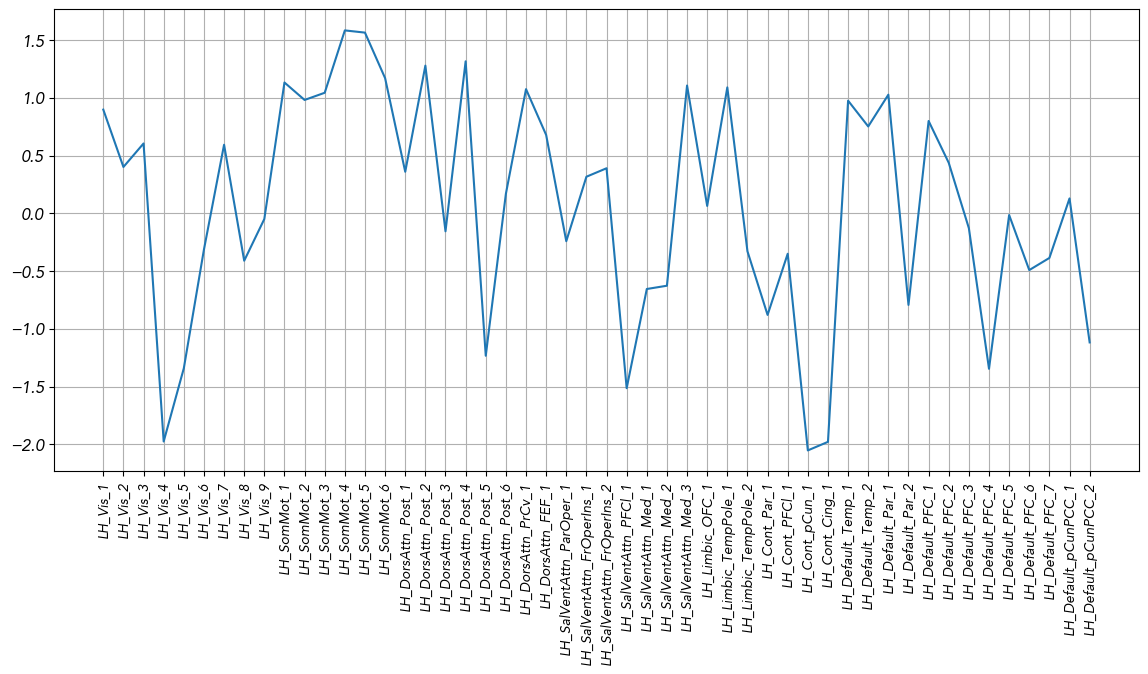

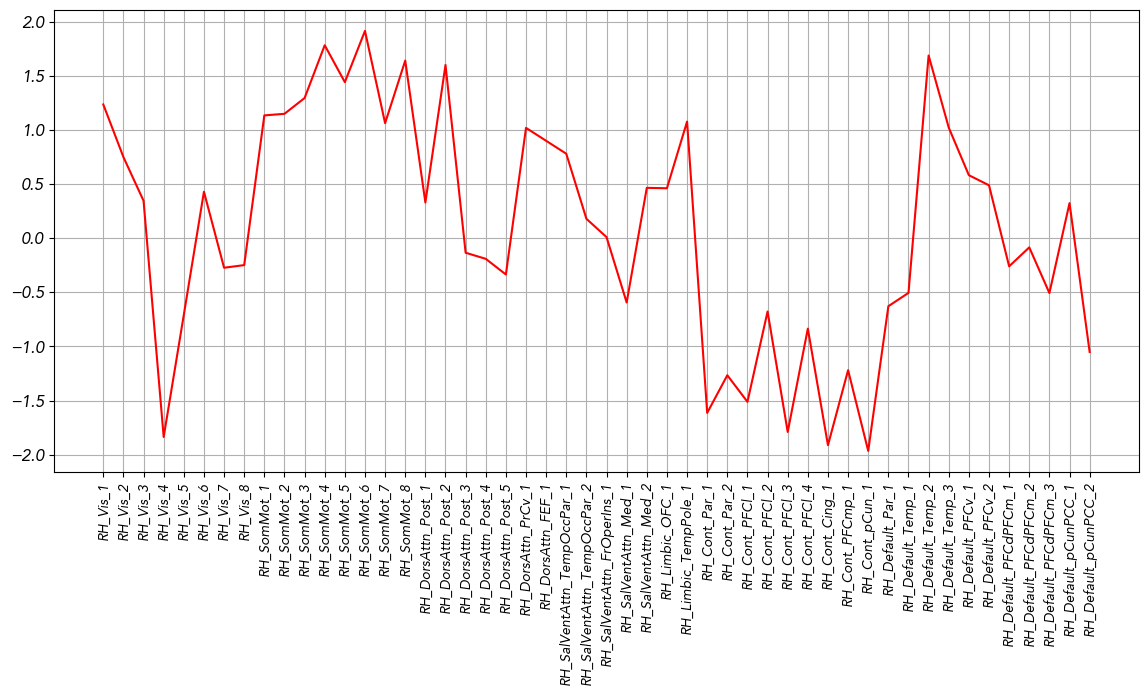

In [184]:
plt.figure(figsize=(14,6))
plt.plot(source_sink_S[:50])
plt.xticks(np.arange(0,50,1),labels=labels100[:50], rotation=90, fontsize=10);
plt.grid(True);
#plt.xticks()

plt.figure(figsize=(14,6))
plt.plot(source_sink_S[50:100], color ='red')
plt.xticks(np.arange(0,50,1),labels=labels100[50:], rotation=90, fontsize=10);
plt.grid(True);
#plt.xticks()


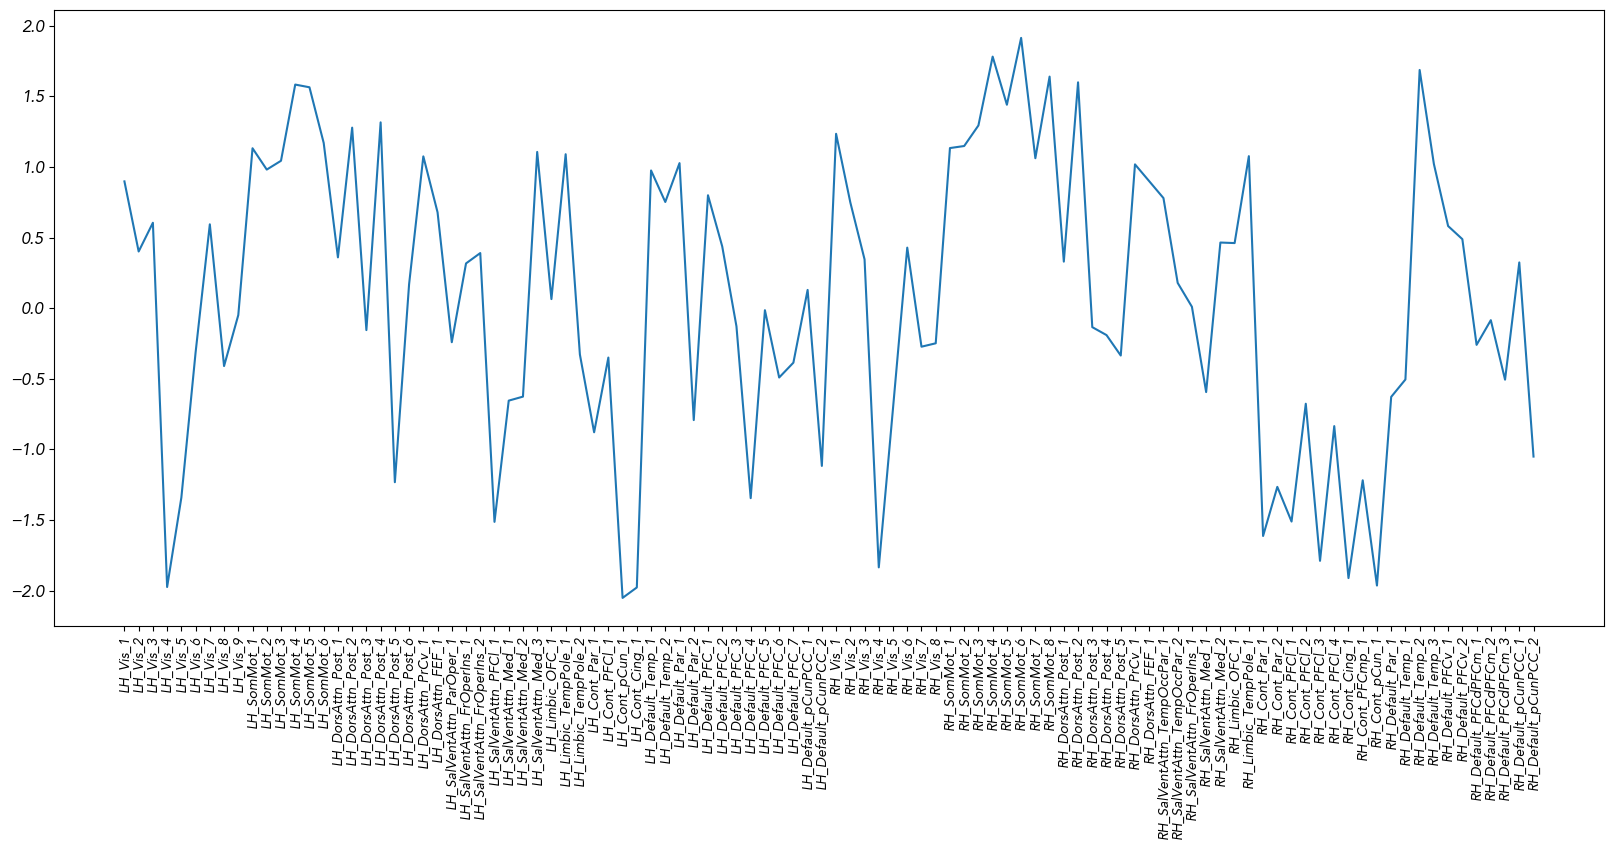

In [177]:
plt.figure(figsize=(20,8))
plt.plot(source_sink_S[:100])
plt.xticks(np.arange(0,100,1),labels=labels100[:], rotation=90, fontsize=10);
#plt.xticks()


In [170]:
labels100[:5]

['LH_Vis_1', 'LH_Vis_2', 'LH_Vis_3', 'LH_Vis_4', 'LH_Vis_5']

In [165]:
np.any(~np.isnan(pos_net))

np.True_

In [164]:

pos_vmax = np.nanpercentile(pos_net, 95) if np.any(~np.isnan(pos_net)) else 1
neg_vmax = np.nanpercentile(np.abs(neg_net), 95) if np.any(~np.isnan(neg_net)) else 1
print(neg_vmax)
if pos_vmax == 0:
    pos_vmax = np.nanmax(pos_net)

if neg_vmax == 0:
    neg_vmax = np.nanmax(np.abs(neg_net))
    print(neg_vmax)

0.012056163960200681


In [147]:
np.any(~np.isnan(neg_net))

np.True_

In [149]:
neg_net

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [138]:
neg_count

array([[ 6.,  3., 12., 10.,  3.,  9., 22.,  4.,  9., 11.,  8.,  2., 15.,
        23.],
       [ 1.,  0.,  4.,  4.,  0.,  9.,  6.,  2.,  0.,  5.,  3.,  1., 17.,
         6.],
       [10.,  7.,  2.,  1.,  2., 11., 33.,  8., 10.,  4.,  3.,  3., 33.,
        43.],
       [ 8.,  3.,  1.,  0.,  6.,  2., 32., 14., 11., 12.,  0.,  6., 22.,
        37.],
       [ 2.,  0.,  2.,  4.,  0.,  2.,  1.,  4.,  1.,  6.,  6.,  0., 11.,
         9.],
       [14., 12., 12.,  3.,  2.,  0., 10., 14., 15., 12.,  6.,  5.,  1.,
        22.],
       [20.,  5., 32., 32.,  1., 10.,  9., 24., 12., 53., 45.,  5., 53.,
        27.],
       [ 2.,  2., 15., 13.,  3.,  8., 21.,  2.,  2.,  7.,  4.,  2., 19.,
        26.],
       [ 2.,  0., 10., 10.,  0.,  9.,  9.,  2.,  0.,  4.,  2.,  0., 34.,
        17.],
       [ 8.,  5.,  3.,  9.,  6.,  9., 51.,  4.,  6.,  1.,  1.,  1., 17.,
        35.],
       [ 4.,  3.,  6.,  0.,  6.,  5., 47.,  3.,  5.,  1.,  0.,  0., 10.,
        23.],
       [ 0.,  0.,  2.,  4.,  0.,  5.,  5., 

(array([89., 41., 19., 10., 16.,  1., 11.,  1.,  4.,  4.]),
 array([ 0. ,  5.3, 10.6, 15.9, 21.2, 26.5, 31.8, 37.1, 42.4, 47.7, 53. ]),
 <BarContainer object of 10 artists>)

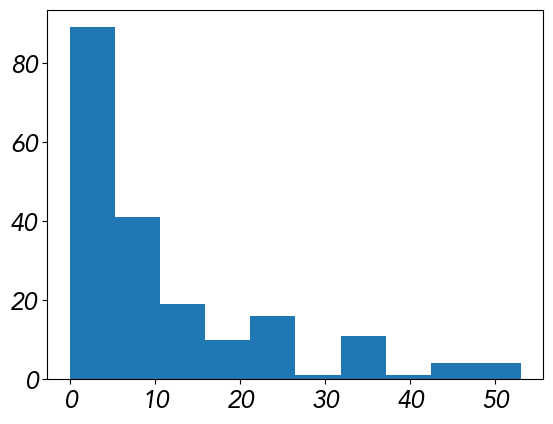

In [65]:
plt.hist(neg_net.flatten())

(182, 218, 182)

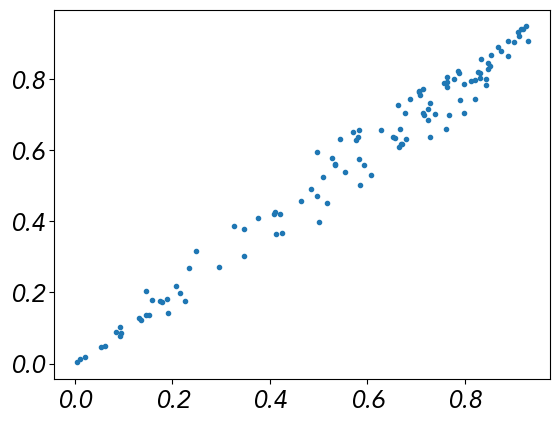

In [254]:
np.linalg.eigvalsh(

In [256]:
ssi_mean = np.mean(np.asarray(ssi_norm_all)[:,:100],0)

In [153]:
pos.shape

(100, 100)

## Study on hcp

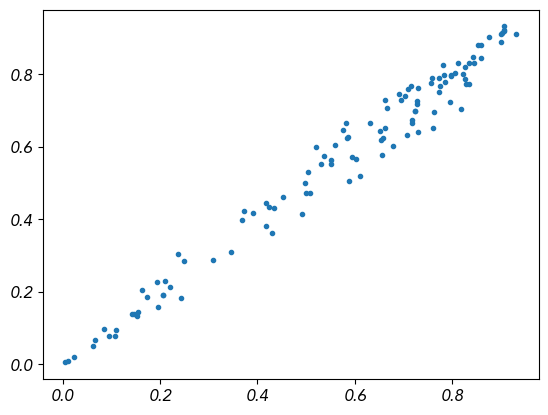

In [85]:
ssi_mean = np.mean(ssi_norm_all,0)
ssi_mean.shape

(112,)

In [45]:
labels_100= np.asarray(labels_100, dtype=str)
labels_100[0]
len(labels)
labels100=[]
for i in labels_100[1:]:
    labels100.append(i[10:])
labels100[:3]

['LH_Vis_2', 'LH_Vis_3', 'LH_Vis_4']

In [46]:
#--------------------------
# 2. Test statistico (1-sample t-test vs 0)
# ----------------------------
from nilearn.datasets import fetch_atlas_schaefer_2018

# specifica parametri: n_rois, network, resolution (1mm o 2mm)
schaefer = fetch_atlas_schaefer_2018(
    n_rois=100,  # numero di ROI
    yeo_networks=7,
    resolution_mm=1  # 1mm MNI
)

# ottieni il path alla mappa volumetrica (NIfTI)
atlas_img = schaefer['maps']
labels_100    = schaefer['labels']
description = schaefer['description']

print(atlas_img)      # percorso locale del file .nii.gz
#print(labels[:10])    # primi 10 nomi etichette
print(description)    # descrizione atlante
#len(labels)
labels100=[]
for i in labels_100[1:]:
    labels100.append(i[10:])
#labels200
N = 100
from statsmodels.stats.multitest import fdrcorrection 
from scipy.stats import ttest_1samp
pvals = np.array([
    ttest_1samp(ssi_norm_all[:, i], 0.0).pvalue
    for i in range(N)
])

# Correzione FDR
_, pvals_fdr = fdrcorrection(pvals, alpha=0.05)

# ----------------------------
# 3. Classificazione dei nodi
# ----------------------------
for i in range(N):
    if pvals_fdr[i] < 0.05:
        role = "SOURCE" if ssi_mean[i] > 0 else "SINK"
    else:
        role = "NOT SIGNIFICANT"

    print(
        f"Node {labels100[i]} | "
        f"SSI_mean = {ssi_mean[i]:+.3f} | "
        f"p_FDR = {pvals_fdr[i]:.3e} | "
        f"Role: {role}"
    )
    

/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
['Vis' 'Vis' 'Vis' 'Vis' 'Vis' 'Vis' 'Vis' 'Vis' 'Vis' 'SomMot']
.. _schaefer_atlas:

Schaefer 2018 atlas

Access
------
See :func:`nilearn.datasets.fetch_atlas_schaefer_2018`.

Notes
-----
This atlas (:footcite:t:`schaefer_atlas`) provides a labeling of cortical voxels in the MNI152
space, see :footcite:t:`Schaefer2017`.
Each ROI is annotated with a network from the :term:`parcellation`
(7- or 17-network solution; see :footcite:t:`Yeo2011`).

Different versions of the atlas are available, varying in
- number of rois (100 to 1000),
- network annotation (7 or 17)
- spatial resolution of the atlas (1 or 2 mm)

Content
-------
    :'maps': 3D Nifti image, values are indices in the list of labels.
    :'labels': ROI labels including Yeo-network annotation.
    :'description': A short description of the atlas and some references.

References
----------

.. footbibliography::

License
----

IndexError: list index out of range

## HERE main plots shown

In [131]:
import nibabel as nib

I1=nib.load('/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii')

data = I1.get_fdata()
affine=I1.affine

data_J = np.zeros(np.shape(data))

for r in range(100):
    v=np.where(data==r+1)
    data_J[v]=ssi_mean[r]
    #np.sum(J_all,axis=(1,2))[r]-np.sum(J_all,axis=(0,2))[r]
    
    

img_J = nib.Nifti1Image(data_J, affine)

#nib.save(img_J, 'J.nii.gz')

/tmp/ipykernel_82861/1638872432.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  top = cm.get_cmap('Blues_r', 128)
/tmp/ipykernel_82861/1638872432.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  bottom = cm.get_cmap('Oranges', 128)
/tmp/ipykernel_82861/1638872432.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


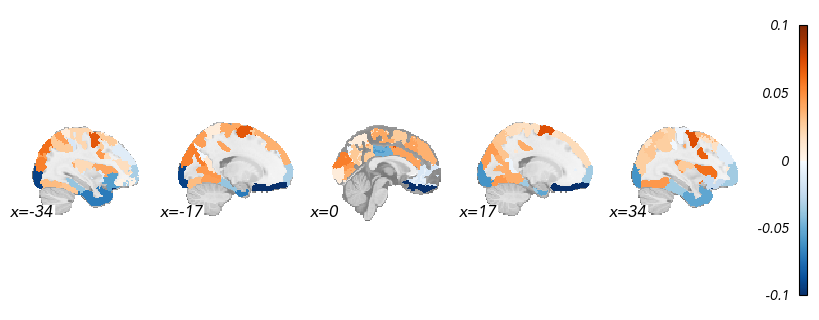

In [136]:
plot(a_ec_norm,labels,14)
import nibabel as nib

I1=nib.load('/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii')

data = I1.get_fdata()
affine=I1.affine

data_J = np.zeros(np.shape(data))

for r in range(100):
    v=np.where(data==r+1)
    data_J[v]=ssi_mean[r]
    #np.sum(J_all,axis=(1,2))[r]-np.sum(J_all,axis=(0,2))[r]
    
    

img_J = nib.Nifti1Image(data_J, affine)



from matplotlib import cm
from matplotlib.colors import ListedColormap

top = cm.get_cmap('Blues_r', 128)
bottom = cm.get_cmap('Oranges', 128)
newcolors1 = np.vstack((top(np.linspace(0, 1, 128)),
                       bottom(np.linspace(0, 1, 128))))
newcmp = ListedColormap(newcolors1, name='OrangeBlue')


import nilearn
import nilearn.plotting

fig = plt.figure(figsize=(8, 3))
display=nilearn.plotting.plot_stat_map(img_J,cmap=newcmp,draw_cross=False,display_mode='x',\
                                       cut_coords=[-34,-17,0,17, 34],colorbar=True,figure=fig, vmin=-.1, vmax=.1)
display._colorbar_ax.tick_params(labelsize=10)
#fig.suptitle('C MOU', fontsize=20, y=1.05)
fig.subplots_adjust(top=0.85)
plt.tight_layout()
plt.savefig('deltaJ_map.png')

In [57]:
whos

Variable                                      Type              Data/Info
-------------------------------------------------------------------------
BaseEstimator                                 type              <class 'sklearn.base.BaseEstimator'>
C                                             ndarray           100x100: 10000 elems, type `float64`, 80000 bytes
C_thr                                         ndarray           100x100: 10000 elems, type `float64`, 80000 bytes
I1                                            Nifti1Image       \n<class 'nibabel.nifti1.<...>    : np.bytes_(b'n+1')\n
JS                                            ndarray           1013x112x112: 12707072 elems, type `float64`, 101656576 bytes (96.947265625 Mb)
JS_2                                          ndarray           1013x112x112: 12707072 elems, type `float64`, 101656576 bytes (96.947265625 Mb)
JS_significant                                ndarray           100x100: 10000 elems, type `float64`, 80000 bytes
M

In [62]:
number = 102
# ==========================================================
# OUTPUT VARIABLES
# ==========================================================
my_info = [[] for _ in range(number)]
my_info_ec = [[] for _ in range(number)]
my_info_ec_sym =[[] for _ in range(number)]

corr = [[] for _ in range(number)]
corr_ = [[] for _ in range(number)]
ass = [[] for _ in range(number)]

# Previously introduced directional measure
corr_S_Q1asym_ = [[] for _ in range(number)]
corr_plus = [[] for _ in range(number)]

# New quantities
neq_to_diss_ratio = [[] for _ in range(number)]
S_amplitude_ratio = [[] for _ in range(number)]


MAX_ITER = 100

taus=np.logspace(-.35,2,)
# ==========================================================
# MAIN LOOP
# ==========================================================

for l, sub in enumerate(tqdm(sub_tot[:2])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub}/'
        f'{sub}_REST1_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )

    Y = cluster_regions(data_ref[:, :100], aggregate[:100])

    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    Q0_inv = np.linalg.pinv(Q0)

    # Empirical antisymmetric lagged covariance
    Q1_asym = 0.5 * (Q1 - Q1.T)

    q1_asym_norm = np.linalg.norm(
        Q1_asym,
        ord='fro'
    )

    for _,tau_ in enumerate(taus):

        #m = MOU()

        m.fit_LO(
            Q0,
            Q1,
            lag=1,
            prior=0.0,
            tau=float(tau_),
            eta_C=0.005,
            max_iter=MAX_ITER
        )
        if _ in [0,4,5,6]:
            J = m.J
        print('printing',m.J[:10,:10],
             J[:10,:10])

  0%|          | 0/2 [00:00<?, ?it/s]

printing [[-2.23872114e+00  1.21021773e-02  2.27961169e-03 -5.93972845e-02
   2.27238278e-02  1.37100140e-02 -7.58912557e-03  1.94640674e-02
   4.86614190e-02 -4.04116657e-02]
 [ 3.32159788e-03 -2.23872114e+00  2.18238006e-02  1.10793305e-02
  -7.93167203e-03  1.06159009e-01 -5.75390395e-02  2.27924055e-02
  -8.24720171e-02 -2.41790299e-02]
 [-6.31333169e-03  3.38511166e-02 -2.23872114e+00  1.35515620e-01
   1.26355136e-01  4.93801225e-03  5.60644165e-02  8.32073060e-03
   5.00426255e-02  4.99748766e-02]
 [-9.24023947e-02  1.04443166e-03  1.04840991e-01 -2.23872114e+00
   1.01998334e-01  3.85953431e-03  5.93549257e-04 -1.29495526e-02
   2.81397517e-02 -2.85082927e-02]
 [ 3.84842577e-02  3.74859458e-02  1.14735274e-01  1.11315386e-01
  -2.23872114e+00  7.31390880e-02  1.49197907e-01  1.15617843e-02
   4.09241231e-02 -8.16155035e-02]
 [ 1.33947277e-02  1.59518105e-01  1.48419216e-02 -2.07342745e-03
   8.25707220e-02 -2.23872114e+00  1.16334924e-01  9.04655970e-02
   3.11443222e-02  2.750

  0%|          | 0/2 [00:13<?, ?it/s]


KeyboardInterrupt: 

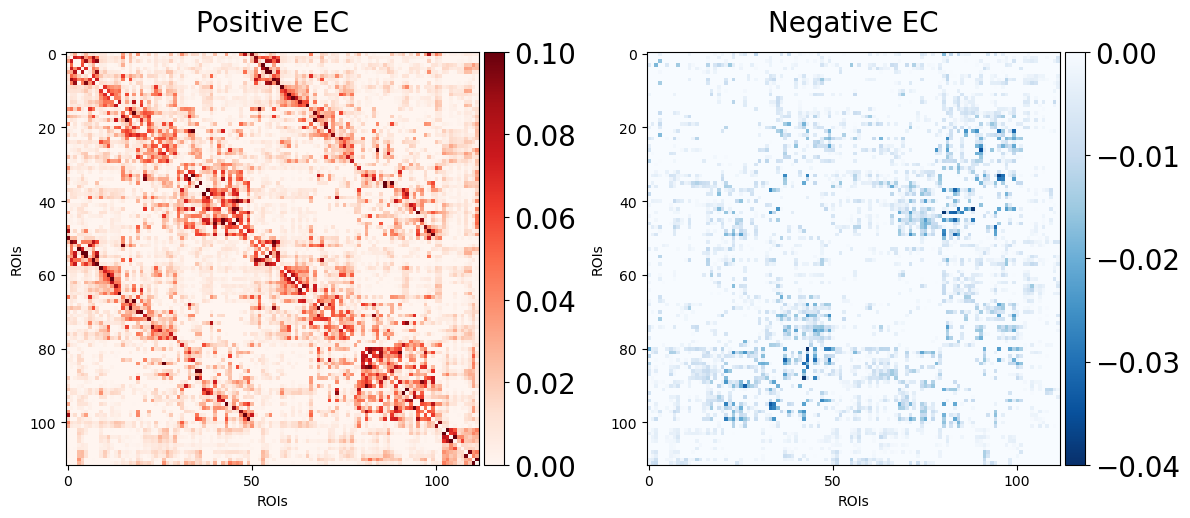

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12,6)  )
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 44
#12

#JS = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')
media = dediag(np.mean(JS,0))
#sub = 600
#media = JS[sub]

pos = media.copy()
neg = media.copy()
pos[media<0] = 0
neg[media>0] = 0


plt.rcParams["axes.titlesize"] = 20
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20



# Primo pannello
v = [[0.,.1],[-.04,0]]
#mat = loadmat(pat + np.sort(os.listdir('/readonly/insights/RESULTS_YA_new_1000/RESULTS_YA_new_1000_RUN1_noisevar/'))[subject])['A']
js=[pos, neg]
cmaps = ['Reds', 'Blues_r']

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['Positive EC', 'Negative EC',]
for i,ax in enumerate(axes.reshape(-1)[:2]):
    im= ax.imshow(dediag(js[i]), vmin=v[i][0], vmax=v[i][1], cmap = cmaps[i]);
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}",pad=15)
    ax.set_xlabel('ROIs')
    ax.set_ylabel('ROIs')
plt.tight_layout()
from nilearn.datasets import fetch_atlas_schaefer_2018

# specifica parametri: n_rois, network, resolution (1mm o 2mm)
schaefer = fetch_atlas_schaefer_2018(
    n_rois=200,  # numero di ROI
    yeo_networks=7,
    resolution_mm=1  # 1mm MNI
)

# ottieni il path alla mappa volumetrica (NIfTI)
atlas_img = schaefer['maps']
labels_200    = schaefer['labels']
description = schaefer['description']

print(atlas_img)      # percorso locale del file .nii.gz
print(labels[:10])    # primi 10 nomi etichette
print(description)    # descrizione atlante
len(labels)
#plt.savefig('Figures/positivemap.jpg', dpi = 300, bbox_inches='tight');

In [92]:
from nilearn.datasets import fetch_atlas_schaefer_2018

# specifica parametri: n_rois, network, resolution (1mm o 2mm)
schaefer = fetch_atlas_schaefer_2018(
    n_rois=200,  # numero di ROI
    yeo_networks=7,
    resolution_mm=1  # 1mm MNI
)

# ottieni il path alla mappa volumetrica (NIfTI)
atlas_img = schaefer['maps']
labels_200    = schaefer['labels']
description = schaefer['description']

print(atlas_img)      # percorso locale del file .nii.gz
print(labels[:10])    # primi 10 nomi etichette
print(description)    # descrizione atlante
len(labels)

/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_200Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
['7Networks_LH_Vis_1' '7Networks_LH_Vis_2' '7Networks_LH_Vis_3'
 '7Networks_LH_Vis_4' '7Networks_LH_Vis_5' '7Networks_LH_Vis_6'
 '7Networks_LH_Vis_7' '7Networks_LH_Vis_8' '7Networks_LH_Vis_9'
 '7Networks_LH_SomMot_1']
.. _schaefer_atlas:

Schaefer 2018 atlas

Access
------
See :func:`nilearn.datasets.fetch_atlas_schaefer_2018`.

Notes
-----
This atlas (:footcite:t:`schaefer_atlas`) provides a labeling of cortical voxels in the MNI152
space, see :footcite:t:`Schaefer2017`.
Each ROI is annotated with a network from the :term:`parcellation`
(7- or 17-network solution; see :footcite:t:`Yeo2011`).

Different versions of the atlas are available, varying in
- number of rois (100 to 1000),
- network annotation (7 or 17)
- spatial resolution of the atlas (1 or 2 mm)

Content
-------
    :'maps': 3D Nifti image, values are indices in the list of labels.
    :'labels': ROI labels including Yeo-

100